# Challenge 2 – Customer Engagement Score

Dữ liệu đầu vào là các file trong `clean_data`. Cài thư viện: `pip install duckdb pandas matplotlib scikit-learn`.

Mọi con số trong phần nhận xét đều lấy từ bảng kết quả của một ô code trong notebook: thường là ô ngay phía trên, còn khi lấy từ mục khác thì nhận xét ghi rõ số mục.

In [1]:
import os, itertools
import duckdb, pandas as pd, numpy as np, matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from matplotlib.colors import LinearSegmentedColormap

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 220)
pd.set_option('display.max_colwidth', 120)

CLEAN_DIR = 'clean_data'
OUT_DIR = 'output'
os.makedirs(OUT_DIR, exist_ok=True)
HINH_DIR = f'{OUT_DIR}/figures'          # hình được lưu thêm dạng PNG để dùng cho slide và dashboard
os.makedirs(HINH_DIR, exist_ok=True)

# Màu và kiểu hình dùng chung cho mọi hình
MAU = {'xanh': '#2a78d6', 'cam': '#eb6834', 'chu': '#0b0b0b', 'chu_phu': '#52514e', 'luoi': '#e4e3df', 'nen': '#fcfcfb', 'nhat': '#c9c8c3'}
MAU_NHOM = {'4. Ngủ yên': '#86b6ef', '3. Tương tác thấp': '#3987e5', '2. Tương tác trung bình': '#1c5cab', '1. Tương tác cao': '#0d366b'}
CMAP_XANH = LinearSegmentedColormap.from_list('xanh', ['#eef4fc', '#9ec5f4', '#3987e5', '#1c5cab', '#0d366b'])
plt.rcParams.update({'figure.facecolor': MAU['nen'], 'axes.facecolor': MAU['nen'], 'savefig.facecolor': MAU['nen'],
                     'axes.edgecolor': MAU['nhat'], 'axes.labelcolor': MAU['chu_phu'], 'xtick.color': MAU['chu_phu'], 'ytick.color': MAU['chu_phu'],
                     'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': MAU['luoi'], 'grid.linewidth': 0.8,
                     'axes.axisbelow': True, 'axes.titlesize': 10.5, 'axes.titleweight': 'bold', 'axes.titlecolor': MAU['chu'],
                     'axes.titlelocation': 'left', 'font.size': 9.5, 'legend.frameon': False})
def so(x, n=1):
    # định dạng số kiểu Việt Nam: dấu phẩy thập phân, dấu chấm hàng nghìn
    return f'{x:,.{n}f}'.replace(',', ' ').replace('.', ',').replace(' ', '.')
def luu_hinh(fig, ten):
    fig.savefig(f'{HINH_DIR}/{ten}.png', dpi=200, bbox_inches='tight')
    plt.show()

con = duckdb.connect('bi10_eda.duckdb')
con.execute("SET memory_limit='1GB'")
con.execute("SET preserve_insertion_order=false")

def q(sql):
    return con.sql(sql).df()

# Các bảng được nạp từ clean_data vào file bi10_eda.duckdb ở lần chạy đầu và dùng lại ở các lần sau.
# Các bảng chỉ số do hàm tinh_chi_so tạo ra cũng được lưu lại và dùng lại theo cách tương tự.
# Nếu file trong clean_data được tạo lại, đặt TAI_LAI_DU_LIEU = True để nạp và tính lại.
TAI_LAI_DU_LIEU = False
da_co = set(q("select table_name from information_schema.tables")['table_name'])
for bang, file in [('EN_CONTRACT', 'CONTRACT_clean'), ('EN_PB', 'PAST_BEHAVIOR_clean'), ('EN_CUSTOMER', 'CUSTOMER_clean'),
                   ('EN_LEADS', 'LEADS_clean'), ('EN_CALL', 'CALL_clean')]:
    if TAI_LAI_DU_LIEU or bang not in da_co:
        con.execute(f"CREATE OR REPLACE TABLE {bang} AS SELECT * FROM read_csv('{CLEAN_DIR}/{file}.csv', header=true, sample_size=-1)")
q("select (select count(*) from EN_CUSTOMER) so_khach, (select count(*) from EN_CONTRACT) so_hop_dong, (select count(*) from EN_LEADS) so_lead, (select count(*) from EN_CALL) so_cuoc_goi, (select count(*) from EN_PB) so_lan_cham_diem")

,so_khach,so_hop_dong,so_lead,so_cuoc_goi,so_lan_cham_diem
0,1000528,4280377,2104642,4000000,4412617


## 0. Kiểm tra dữ liệu tương tác trước khi dùng

> **Câu hỏi của mục này:** Dữ liệu tương tác có chỗ nào không đáng tin cần xử lý trước khi dùng?
>
> **Cách làm:** kiểm tra mỗi bảng có dữ liệu trong khoảng thời gian nào, xem các mã kết quả cuộc gọi, và xem các mã cuộc gọi bị lặp.

Đề lưu ý phải chú ý đến chất lượng dữ liệu. Engagement được đo từ các bảng ghi lại hoạt động của khách theo thời gian, nên trước hết cần biết mỗi bảng có dữ liệu trong khoảng thời gian nào.

In [2]:
q("""
select 'CONTRACT (ngày nộp hồ sơ)' bang, min(APPLY_CONTRACT_TIME) ngay_dau, max(APPLY_CONTRACT_TIME) ngay_cuoi, count(*) so_dong from EN_CONTRACT
union all select 'PAST_BEHAVIOR (ngày chấm điểm khi xin vay)', min(DTIME_EVENT), max(DTIME_EVENT), count(*) from EN_PB
union all select 'LEADS (ngày tạo lead)', min(DTIME_CREATED), max(DTIME_CREATED), count(*) from EN_LEADS
union all select 'CALL (ngày gọi)', min(TIME_OF_CALL_START), max(TIME_OF_CALL_START), count(*) from EN_CALL
""")

,bang,ngay_dau,ngay_cuoi,so_dong
0,CONTRACT (ngày nộp hồ sơ),2009-04-21 10:28:56,2025-06-04 22:29:02,4280377
1,PAST_BEHAVIOR (ngày chấm điểm khi xin vay),2022-12-01 00:05:29,2025-06-03 22:30:14,4412617
2,LEADS (ngày tạo lead),2019-10-09 11:16:52,2025-06-04 20:56:56,2104642
3,CALL (ngày gọi),2025-01-01 03:47:11,2026-08-31 23:11:28,4000000


CONTRACT, PAST_BEHAVIOR và LEADS đều kết thúc ngày 03–04/06/2025. Đây là thời điểm "hiện tại" của bộ dữ liệu, nên điểm Engagement cuối cùng của mọi khách được tính tại thời điểm này. Trong notebook, ngày đó được gọi là **ngày chốt** và đặt là 05/06/2025, ngay sau ngày có dữ liệu cuối cùng, để lấy đủ dữ liệu của ngày 04/06/2025. Bảng CALL bắt đầu từ 01/01/2025 và kéo dài đến 31/08/2026, sau ngày chốt. Cột `FLAG_AFTER_SNAPSHOT` của đề đánh dấu các cuộc gọi sau ngày chốt. Ô code dưới đếm số cuộc gọi trước và sau ngày chốt, và số cuộc gọi theo tháng trước ngày chốt.

In [3]:
display(q("""select FLAG_AFTER_SNAPSHOT, min(TIME_OF_CALL_START) ngay_dau, max(TIME_OF_CALL_START) ngay_cuoi, count(*) so_cuoc_goi,
                    round(100.0 * count(*) / sum(count(*)) over (), 1) pct from EN_CALL group by 1 order by 1"""))
q("""select strftime(TIME_OF_CALL_START, '%Y-%m') thang, count(*) so_cuoc_goi, count(distinct SKP_CLIENT) so_khach_duoc_goi
     from EN_CALL where TIME_OF_CALL_START < '2025-06-05' group by 1 order by 1""").set_index('thang').T

,FLAG_AFTER_SNAPSHOT,ngay_dau,ngay_cuoi,so_cuoc_goi,pct
0,0,2025-01-01 03:47:11,2025-06-04 22:15:51,1022211,25.6
1,1,2025-06-05 05:31:17,2026-08-31 23:11:28,2977789,74.4


thang,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06
so_cuoc_goi,202695,189259,202587,198685,202608,26377
so_khach_duoc_goi,162983,154253,163280,160437,163214,25338


74,4% cuộc gọi (2.977.789 cuộc) có ngày từ 05/06/2025 trở đi, tức xảy ra sau ngày chốt. Khi tính chỉ số ở một ngày bất kỳ, các cuộc gọi sau ngày đó là thông tin của tương lai nên không được dùng. Trước ngày chốt, bảng CALL chỉ có dữ liệu từ 01/01/2025: mỗi tháng khoảng 189–203 nghìn cuộc gọi tới 154–163 nghìn khách (tháng 06/2025 chỉ có 4 ngày). Vì không có cuộc gọi nào trước 01/01/2025, chỉ số từ cuộc gọi chỉ đếm được trong một khoảng ngắn trước ngày tính chỉ số.

### 0.1. Bảng CALL gồm những loại cuộc gọi nào

Trước khi đếm cuộc gọi, cần biết bảng CALL ghi những loại cuộc gọi gì. Bảng dưới đếm số cuộc gọi theo mã kết quả (`CODE_DISPOSITION`), 20 mã nhiều nhất.

In [4]:
q("""select coalesce(CODE_DISPOSITION, 'none') ma_ket_qua, count(*) so_cuoc_goi, round(100.0 * count(*) / sum(count(*)) over (), 2) pct_cuoc_goi
     from EN_CALL group by 1 order by 2 desc limit 20""")

,ma_ket_qua,so_cuoc_goi,pct_cuoc_goi
0,none,3412027,85.30
1,Refuse,166366,4.16
2,No_Answer,80585,2.01
3,Client busy,62977,1.57
4,OWNUnidentifiedPersonNonRPC,45669,1.14
5,OWNUnidentifiedPerson,43337,1.08
6,OWNMessageLeftRPC,14109,0.35
7,ppSimple,13017,0.33
8,More consultation,10920,0.27
9,OWNPTPConfirmed,10299,0.26


85,3% cuộc gọi không có mã kết quả. Trong các mã còn lại có nhiều mã bắt đầu bằng `OWN`, ví dụ `OWNPTPConfirmed` (khách xác nhận hẹn ngày trả nợ), `OWNAgreement`, `OWNVoluntaryPayment` (khách tự nguyện trả). Đây là mã của các cuộc gọi về việc trả nợ. Ô code dưới kiểm tra hai điều: khách nhận loại cuộc gọi này có thường đang có khoản vay hơn không, và có thường trễ hạn hơn không.

In [5]:
own = q("""
with x as (select SKP_CLIENT, count(*) filter (where coalesce(CODE_DISPOSITION, '') like 'OWN%') so_cuoc_own from EN_CALL group by 1),
     tg as (select SKP_CLIENT,
                   max((IS_SIGNED = 1 and PAYMENT_NUM is not null
                        and APPLY_CONTRACT_TIME + PAYMENT_NUM::INT * INTERVAL 1 MONTH > TIMESTAMP '2025-06-05')::INT) dang_tra,
                   max((IS_SIGNED = 1 and (FIRST_DUE > 0 or SECOND_DUE > 0 or THIRD_DUE > 0 or FOURTH_DUE > 0))::INT) tung_tre
            from EN_CONTRACT group by 1)
select case when coalesce(x.so_cuoc_own, 0) > 0 then 'Có cuộc gọi mã OWN' else 'Không có cuộc gọi mã OWN' end nhom_khach,
       coalesce(tg.dang_tra, 0) dang_tra, coalesce(tg.tung_tre, 0) tung_tre
from EN_CUSTOMER k left join x using (SKP_CLIENT) left join tg using (SKP_CLIENT)""")

def so_sanh(d, cot, ten):
    # tỷ lệ (%) của hai nhóm, chênh lệch và biên sai số 95% của chênh lệch: ± 1,96 * căn(p1(1-p1)/n1 + p2(1-p2)/n2)
    g = d.groupby('nhom_khach')[cot].agg(['size', 'mean'])
    p1, n1 = g.loc['Có cuộc gọi mã OWN', 'mean'], g.loc['Có cuộc gọi mã OWN', 'size']
    p2, n2 = g.loc['Không có cuộc gọi mã OWN', 'mean'], g.loc['Không có cuộc gọi mã OWN', 'size']
    bien = 1.96 * np.sqrt(p1 * (1 - p1) / n1 + p2 * (1 - p2) / n2) * 100
    return {'chi_so': ten, 'so_khach_OWN': n1, 'pct_OWN': round(p1 * 100, 2), 'so_khach_khac': n2, 'pct_khac': round(p2 * 100, 2),
            'chenh_lech': round((p1 - p2) * 100, 2), 'sai_so_95_chenh_lech': round(bien, 2),
            'chenh_lech_vuot_sai_so': abs(p1 - p2) * 100 > bien}
dang_tra = own[own.dang_tra == 1]
display(pd.DataFrame([so_sanh(own, 'dang_tra', 'Đang có khoản trả góp tại ngày chốt (toàn bộ khách)'),
                      so_sanh(own, 'tung_tre', 'Từng trễ ở 4 kỳ trả đầu của ít nhất 1 hợp đồng (toàn bộ khách)'),
                      so_sanh(dang_tra, 'tung_tre', 'Từng trễ ở 4 kỳ trả đầu (chỉ khách đang có khoản trả góp)')]))
del dang_tra
print('Các cột cờ trễ hạn có trong bảng CONTRACT:', [c for c in q("describe EN_CONTRACT").column_name if c.endswith('_DUE')])
del own
q("select count(*) filter (where coalesce(CODE_DISPOSITION, '') like 'OWN%') so_cuoc_own, round(100.0 * count(*) filter (where coalesce(CODE_DISPOSITION, '') like 'OWN%') / count(*), 1) pct_cuoc_goi from EN_CALL")

,chi_so,so_khach_OWN,pct_OWN,so_khach_khac,pct_khac,chenh_lech,sai_so_95_chenh_lech,chenh_lech_vuot_sai_so
0,Đang có khoản trả góp tại ngày chốt (toàn bộ khách),40445,75.56,960083,51.00,24.56,0.43,True
1,Từng trễ ở 4 kỳ trả đầu của ít nhất 1 hợp đồng (toàn bộ khách),40445,5.17,960083,5.07,0.10,0.22,False
2,Từng trễ ở 4 kỳ trả đầu (chỉ khách đang có khoản trả góp),30560,4.67,489600,5.01,-0.34,0.24,True


Các cột cờ trễ hạn có trong bảng CONTRACT: ['FIRST_DUE', 'SECOND_DUE', 'THIRD_DUE', 'FOURTH_DUE']


,so_cuoc_own,pct_cuoc_goi
0,173146,4.3


Bảng thứ nhất so sánh hai nhóm khách trên ba chỉ số. Cột `chenh_lech` là tỷ lệ của nhóm `OWN` trừ tỷ lệ của nhóm còn lại (điểm phần trăm). Cột `sai_so_95_chenh_lech` là mức chênh lệch có thể xuất hiện chỉ do ngẫu nhiên, đã tính đến cỡ của cả hai nhóm. Cột `chenh_lech_vuot_sai_so` cho biết chênh lệch có lớn hơn mức đó hay không.

- **Đang có khoản vay:** 75,56% so với 51,00%, chênh 24,56 điểm, lớn hơn rất nhiều so với sai số ±0,43 điểm. Nhóm `OWN` chỉ có 40.445 khách, ít hơn nhóm còn lại khoảng 24 lần, nhưng mỗi tỷ lệ được tính riêng trong nhóm của nó nên cỡ nhóm không làm lệch tỷ lệ; cỡ nhóm chỉ làm sai số lớn hơn, và đã được tính vào cột sai số.
- **Trễ hạn, toàn bộ khách:** 5,17% so với 5,07%, chênh 0,10 điểm, nhỏ hơn sai số ±0,22 điểm. Hai nhóm trễ hạn như nhau.
- **Trễ hạn, chỉ khách đang trả góp:** 4,67% so với 5,01%, chênh −0,34 điểm, vượt sai số ±0,24 điểm nhưng theo chiều ngược lại: khách có cuộc gọi mã `OWN` trễ hạn **ít** hơn một chút.
- Dòng in danh sách cột trong ô code cho thấy bảng CONTRACT chỉ có 4 cột cờ trễ hạn, ứng với 4 kỳ trả đầu, nên kiểm tra này không thấy được các kỳ trả sau.

Kết luận: các cuộc gọi mã `OWN` gắn với khoản vay khách đang trả, như nhắc lịch trả, xác nhận hẹn trả, ghi nhận khách tự trả. Dữ liệu không cho thấy đây là cuộc gọi đòi nợ khách quá hạn. Dù vậy, đây là cuộc gọi phục vụ việc trả khoản vay hiện tại, không phải cuộc gọi chào bán, nên số lần gọi và thời gian nói chuyện của chúng không phản ánh khách tương tác với hoạt động bán hàng của công ty. Các cuộc gọi này, chiếm 4,3% số cuộc gọi, được bỏ khỏi mọi chỉ số cuộc gọi.

### 0.2. Mã cuộc gọi bị lặp

Theo bảng mô tả cột của đề, `CALL_ID` là mã định danh duy nhất của một phiên gọi. Ô code dưới đếm các `CALL_ID` xuất hiện ở nhiều dòng, xem các dòng đó có thuộc cùng một khách không, và in ví dụ một mã.

In [6]:
display(q("""
with lap as (select CALL_ID, count(*) so_dong, count(DISTINCT SKP_CLIENT) so_khach, count(DISTINCT TIME_OF_CALL_START) so_thoi_diem,
                    max(TIME_OF_CALL_START)::date - min(TIME_OF_CALL_START)::date cach_ngay
             from EN_CALL group by 1 having count(*) > 1)
select count(*) so_call_id_lap, sum(so_dong) so_dong, sum(so_dong - 1) so_dong_thua,
       round(100.0 * sum(so_dong - 1) / (select count(*) from EN_CALL), 2) pct_dong_thua,
       count(*) filter (where so_khach = 1) cung_mot_khach, count(*) filter (where so_thoi_diem = 1) cung_mot_thoi_diem,
       median(cach_ngay) trung_vi_so_ngay_cach_nhau
from lap"""))
q("""select CALL_ID, SKP_CLIENT, TIME_OF_CALL_START, CALL_TYPE, DURATIONS, CODE_DISPOSITION
     from EN_CALL where CALL_ID = '007c03afe6cadae6' order by TIME_OF_CALL_START""")

,so_call_id_lap,so_dong,so_dong_thua,pct_dong_thua,cung_mot_khach,cung_mot_thoi_diem,trung_vi_so_ngay_cach_nhau
0,12022,24549.0,12527.0,0.31,12009,0,184.0


,CALL_ID,SKP_CLIENT,TIME_OF_CALL_START,CALL_TYPE,DURATIONS,CODE_DISPOSITION
0,***,***,2025-01-02 08:26:23,Outbound,504,Transfer for signing
1,***,***,2025-04-17 08:25:47,Outbound,20,S2S
2,***,***,2025-07-06 08:34:54,Outbound,164,Sign successful


12.022 mã `CALL_ID` xuất hiện ở 24.549 dòng, tức 12.527 dòng thừa (0,31% bảng CALL). 12.009 mã trong số đó chỉ thuộc một khách, nhưng không mã nào có các dòng cùng một thời điểm: các dòng của cùng một mã cách nhau trung vị 184 ngày. Ví dụ một mã của một khách có ba dòng ngày 02/01, 17/04 và 06/07/2025 với kết quả "Transfer for signing", "S2S" và "Sign successful", giống các bước của một quá trình ký hợp đồng nhưng nằm ở ba thời điểm khác nhau. Dữ liệu không cho biết vì sao một mã bị dùng lại.

Theo bảng mô tả cột của đề, `CALL_ID` là mã của một phiên gọi, nên mỗi mã được tính là **một cuộc gọi**: số cuộc gọi của khách trong một khoảng thời gian là số `CALL_ID` khác nhau có dòng nằm trong khoảng đó. Thời lượng của các dòng cùng mã được cộng chung. Chỉ 0,31% số dòng bị ảnh hưởng, nên cách xử lý này gần như không làm đổi kết quả.

> **Tóm lại mục 0:** Các bảng CONTRACT, PAST_BEHAVIOR và LEADS kết thúc ngày 03–04/06/2025, nên ngày chốt là 05/06/2025. 74,4% cuộc gọi nằm sau ngày chốt và không được dùng; trước ngày chốt chỉ có cuộc gọi từ 01/01/2025. Cuộc gọi mã OWN (4,3%) phục vụ việc trả khoản vay hiện tại, không phải chào bán, nên bị loại. Mỗi `CALL_ID` được tính là một cuộc gọi.

## 1. Hành vi của khách theo 5 khía cạnh (yêu cầu 2)

> **Câu hỏi của mục này:** Khách đang hành xử thế nào ở 5 khía cạnh đề yêu cầu: recency, frequency, hành vi tương tác, hoạt động lead và tương tác sản phẩm?
>
> **Cách làm:** gộp các bảng gốc thành một dòng cho mỗi khách tại ngày chốt, rồi xem khách phân bố thế nào ở từng khía cạnh.

Đề yêu cầu phân tích hành vi khách theo recency, frequency, hành vi tương tác, hoạt động lead và tương tác sản phẩm. Các bảng gốc ghi mỗi sự kiện một dòng: một khách có thể có nhiều cuộc gọi, nhiều lead, nhiều lần chấm điểm, nhiều hồ sơ. Để mô tả và chấm điểm từng khách, mỗi bảng được gộp lại thành **một dòng cho mỗi khách**: đếm số sự kiện, cộng thời lượng, lấy ngày gần nhất, đếm số tháng hoặc số nhóm sản phẩm khác nhau. Sau đó các bảng đã gộp được ghép vào danh sách 1.000.528 khách của bảng CUSTOMER.

Việc gộp được viết trong hàm `tinh_chi_so(T, ten_bang)`. Hàm nhận một ngày `T` và chỉ dùng các sự kiện xảy ra trước ngày đó. Riêng bảng CALL chỉ dùng cuộc gọi trong **90 ngày trước `T`**. Lý do: cuộc gọi chỉ có từ 01/01/2025 (mục 0), nên nếu đếm mọi cuộc gọi trước `T` thì `T` càng muộn càng có nhiều tháng cuộc gọi, và số cuộc gọi ở hai ngày tính khác nhau không so sánh được. Với mọi `T` từ 01/04/2025 trở đi, khoảng 90 ngày luôn nằm trọn trong dữ liệu. Ở mục này, hàm được gọi tại ngày chốt; vì dữ liệu kết thúc ngày 04/06/2025, `T` được đặt là 05/06/2025 để lấy đủ dữ liệu ngày cuối. Vì `T` là tham số, cùng một hàm tính được chỉ số tại bất kỳ ngày nào.

Bảng dưới liệt kê mọi cột hàm tạo ra và cách tính.

| Cột | Bảng gốc | Cách tính cho mỗi khách |
|---|---|---|
| `SO_CUOC_GOI` | CALL (bỏ mã OWN, 90 ngày trước `T`) | Đếm số cuộc gọi, mỗi `CALL_ID` khác nhau là một cuộc (mục 0.2) |
| `SO_CUOC_NGHE_MAY` | CALL | Đếm số `CALL_ID` có `CALL_RESULT_SYSTEM` = ANSWER |
| `SO_CUOC_GOI_DEN` | CALL | Đếm số `CALL_ID` có `CALL_TYPE` = Inbound (khách tự gọi đến) |
| `SO_CUOC_PHAN_HOI` | CALL | Đếm số `CALL_ID` khách phản hồi, tức nghe máy (ANSWER) hoặc tự gọi đến |
| `GIAY_NOI_CHUYEN` | CALL | Cộng `DURATIONS` (giây) của các dòng khách nghe máy hoặc tự gọi đến; các dòng cùng `CALL_ID` được cộng chung |
| `SO_CUOC_TU_CHOI` | CALL | Đếm số `CALL_ID` có mã kết quả Refuse |
| `SO_SP_CHAO_QUA_GOI` | CALL | Số nhóm sản phẩm khác nhau được nhắc trong cuộc gọi |
| `SO_NGAY_TU_CUOC_GOI_GAN_NHAT` | CALL | Số ngày từ cuộc gọi gần nhất đến `T` |
| `SO_NGAY_TU_PHAN_HOI_GOI` | CALL | Số ngày từ lần gần nhất khách phản hồi cuộc gọi đến `T` |
| `SO_LEAD` | LEADS (tạo trước `T`) | Đếm số lead |
| `SO_THANG_CO_LEAD` | LEADS | Số tháng khác nhau có lead được tạo |
| `SO_NGUON_LEAD` | LEADS | Số nguồn lead khác nhau |
| `SO_SP_CHAO_QUA_LEAD` | LEADS | Số nhóm sản phẩm khác nhau của các lead |
| `SO_NGAY_TU_LEAD_GAN_NHAT` | LEADS | Số ngày từ lead được tạo gần nhất đến `T` |
| `NGUON_LEAD_GAN_NHAT` | LEADS | Nguồn của lead được tạo gần nhất |
| `SO_SP_DUOC_CHAO` | LEADS và CALL | Số nhóm sản phẩm khác nhau xuất hiện trong lead hoặc cuộc gọi của khách |
| `SO_NGAY_TU_LAN_XIN_VAY` | PAST_BEHAVIOR (trước `T`) | Số ngày từ lần chấm điểm gần nhất đến `T` |
| `SO_THANG_XIN_VAY_6T`, `SO_THANG_XIN_VAY` | PAST_BEHAVIOR | Số tháng khác nhau có lần chấm điểm, trong 180 ngày trước `T` và trong toàn bộ lịch sử |
| `KENH_XIN_VAY_GAN_NHAT` | PAST_BEHAVIOR | Kênh của lần chấm điểm gần nhất (cột `ACTION`, ví dụ APP SCORING, WEB SCORING) |
| `SO_NGAY_TU_HOAT_DONG` | PAST_BEHAVIOR và CALL | Số ngày từ lần gần nhất khách xin vay hoặc phản hồi cuộc gọi: giá trị nhỏ hơn của `SO_NGAY_TU_LAN_XIN_VAY` và `SO_NGAY_TU_PHAN_HOI_GOI` |
| `SO_NGAY_TU_LAN_NOP_HO_SO` | CONTRACT (nộp trước `T`) | Số ngày từ lần nộp hồ sơ gần nhất đến `T` |
| `SO_SP_DA_KY` | CONTRACT | Số nhóm sản phẩm khác nhau của các hợp đồng đã ký |
| `SO_HD_DANG_TRA` | CONTRACT | Số hợp đồng đã ký mà ngày nộp cộng số kỳ trả (tháng) còn sau `T` |
| `SAN_PHAM_GAN_NHAT` | CONTRACT | Nhóm sản phẩm của hợp đồng ký gần nhất |
| `PHIEN_APP_TUAN` | CUSTOMER | Số phiên dùng app trung bình mỗi tuần năm 2025, giữ nguyên |
| `TUOI` | CUSTOMER | Tuổi tại `T`, tính từ ngày sinh |

Khách không có dòng nào ở một bảng thì các cột đếm của bảng đó bằng 0, còn các cột số ngày để trống (nghĩa là chưa có sự kiện nào).

In [7]:
def tinh_chi_so(T, ten_bang):
    # bảng chỉ số đã tính ở lần chạy trước thì dùng lại, trừ khi TAI_LAI_DU_LIEU = True
    if not TAI_LAI_DU_LIEU and ten_bang in set(q("select table_name from information_schema.tables")['table_name']):
        return
    con.execute(f"""
    CREATE OR REPLACE TABLE {ten_bang} AS
    -- (1) CALL: bỏ cuộc gọi mã OWN (mục 0.1), chỉ giữ cuộc gọi trong 90 ngày trước T
    WITH goi AS (
      SELECT * FROM EN_CALL WHERE coalesce(CODE_DISPOSITION, '') NOT LIKE 'OWN%'
        AND TIME_OF_CALL_START < TIMESTAMP '{T}' AND TIME_OF_CALL_START >= TIMESTAMP '{T}' - INTERVAL 90 DAY),
    -- (2) CALL gộp theo khách: mỗi khách một dòng; mỗi CALL_ID tính là một cuộc gọi (mục 0.2)
    c AS (
      SELECT SKP_CLIENT, count(DISTINCT CALL_ID) AS SO_CUOC_GOI,
             count(DISTINCT CALL_ID) FILTER (WHERE CALL_RESULT_SYSTEM = 'ANSWER') AS SO_CUOC_NGHE_MAY,
             count(DISTINCT CALL_ID) FILTER (WHERE CALL_TYPE = 'Inbound') AS SO_CUOC_GOI_DEN,
             coalesce(sum(DURATIONS) FILTER (WHERE CALL_RESULT_SYSTEM = 'ANSWER' OR CALL_TYPE = 'Inbound'), 0) AS GIAY_NOI_CHUYEN,
             count(DISTINCT CALL_ID) FILTER (WHERE CODE_DISPOSITION = 'Refuse') AS SO_CUOC_TU_CHOI,
             count(DISTINCT PRODUCT_GROUP) AS SO_SP_CHAO_QUA_GOI,
             date_diff('day', max(TIME_OF_CALL_START), TIMESTAMP '{T}') AS SO_NGAY_TU_CUOC_GOI_GAN_NHAT,
             count(DISTINCT CALL_ID) FILTER (WHERE CALL_RESULT_SYSTEM = 'ANSWER' OR CALL_TYPE = 'Inbound') AS SO_CUOC_PHAN_HOI,
             date_diff('day', max(TIME_OF_CALL_START) FILTER (WHERE CALL_RESULT_SYSTEM = 'ANSWER' OR CALL_TYPE = 'Inbound'),
                       TIMESTAMP '{T}') AS SO_NGAY_TU_PHAN_HOI_GOI
      FROM goi GROUP BY 1),
    -- (3) LEADS gộp theo khách, chỉ lead tạo trước T
    l AS (
      SELECT SKP_CLIENT, count(*) AS SO_LEAD, count(DISTINCT date_trunc('month', DTIME_CREATED)) AS SO_THANG_CO_LEAD,
             count(DISTINCT LEAD_SOURCE) AS SO_NGUON_LEAD, count(DISTINCT PRODUCT_GROUP) AS SO_SP_CHAO_QUA_LEAD,
             date_diff('day', max(DTIME_CREATED), TIMESTAMP '{T}') AS SO_NGAY_TU_LEAD_GAN_NHAT,
             arg_max(LEAD_SOURCE, DTIME_CREATED) AS NGUON_LEAD_GAN_NHAT
      FROM EN_LEADS WHERE DTIME_CREATED < TIMESTAMP '{T}' GROUP BY 1),
    -- (4) Nhóm sản phẩm được chào: gộp nhóm sản phẩm của lead (trước T) và của cuộc gọi, đếm số nhóm khác nhau
    sp AS (
      SELECT SKP_CLIENT, count(DISTINCT PRODUCT_GROUP) AS SO_SP_DUOC_CHAO
      FROM (SELECT SKP_CLIENT, PRODUCT_GROUP FROM EN_LEADS WHERE DTIME_CREATED < TIMESTAMP '{T}'
            UNION ALL SELECT SKP_CLIENT, PRODUCT_GROUP FROM goi)
      WHERE PRODUCT_GROUP IS NOT NULL GROUP BY 1),
    -- (5) PAST_BEHAVIOR gộp theo khách, chỉ các lần chấm điểm trước T
    pb AS (
      SELECT SKP_CLIENT, date_diff('day', max(DTIME_EVENT), TIMESTAMP '{T}') AS SO_NGAY_TU_LAN_XIN_VAY,
             count(DISTINCT date_trunc('month', DTIME_EVENT)) FILTER (WHERE DTIME_EVENT >= TIMESTAMP '{T}' - INTERVAL 180 DAY) AS SO_THANG_XIN_VAY_6T,
             count(DISTINCT date_trunc('month', DTIME_EVENT)) AS SO_THANG_XIN_VAY,
             arg_max(ACTION, DTIME_EVENT) AS KENH_XIN_VAY_GAN_NHAT
      FROM EN_PB WHERE DTIME_EVENT < TIMESTAMP '{T}' GROUP BY 1),
    -- (6) CONTRACT gộp theo khách, chỉ hồ sơ nộp trước T; chỉ dùng để mô tả, không dùng để chấm điểm
    p AS (
      SELECT SKP_CLIENT, date_diff('day', max(APPLY_CONTRACT_TIME), TIMESTAMP '{T}') AS SO_NGAY_TU_LAN_NOP_HO_SO,
             count(DISTINCT PRODUCT_GROUP) FILTER (WHERE IS_SIGNED = 1) AS SO_SP_DA_KY,
             count(*) FILTER (WHERE IS_SIGNED = 1 AND PAYMENT_NUM IS NOT NULL
                   AND APPLY_CONTRACT_TIME + PAYMENT_NUM::INT * INTERVAL 1 MONTH > TIMESTAMP '{T}') AS SO_HD_DANG_TRA,
             arg_max(PRODUCT_GROUP, APPLY_CONTRACT_TIME) FILTER (WHERE IS_SIGNED = 1) AS SAN_PHAM_GAN_NHAT
      FROM EN_CONTRACT WHERE APPLY_CONTRACT_TIME < TIMESTAMP '{T}' GROUP BY 1)
    -- (7) Ghép tất cả vào danh sách 1.000.528 khách; khách không có dòng nào ở một bảng nhận 0 (hoặc để trống với các cột số ngày)
    SELECT k.SKP_CLIENT,
           coalesce(c.SO_CUOC_GOI, 0) AS SO_CUOC_GOI, coalesce(c.SO_CUOC_NGHE_MAY, 0) AS SO_CUOC_NGHE_MAY,
           coalesce(c.SO_CUOC_GOI_DEN, 0) AS SO_CUOC_GOI_DEN, coalesce(c.GIAY_NOI_CHUYEN, 0) AS GIAY_NOI_CHUYEN,
           coalesce(c.SO_CUOC_TU_CHOI, 0) AS SO_CUOC_TU_CHOI, coalesce(c.SO_SP_CHAO_QUA_GOI, 0) AS SO_SP_CHAO_QUA_GOI,
           coalesce(c.SO_CUOC_PHAN_HOI, 0) AS SO_CUOC_PHAN_HOI, c.SO_NGAY_TU_CUOC_GOI_GAN_NHAT, c.SO_NGAY_TU_PHAN_HOI_GOI,
           nullif(least(coalesce(pb.SO_NGAY_TU_LAN_XIN_VAY, 99999), coalesce(c.SO_NGAY_TU_PHAN_HOI_GOI, 99999)), 99999) AS SO_NGAY_TU_HOAT_DONG,
           pb.KENH_XIN_VAY_GAN_NHAT,
           coalesce(l.SO_LEAD, 0) AS SO_LEAD, coalesce(l.SO_THANG_CO_LEAD, 0) AS SO_THANG_CO_LEAD,
           coalesce(l.SO_NGUON_LEAD, 0) AS SO_NGUON_LEAD, coalesce(l.SO_SP_CHAO_QUA_LEAD, 0) AS SO_SP_CHAO_QUA_LEAD,
           l.SO_NGAY_TU_LEAD_GAN_NHAT,
           l.NGUON_LEAD_GAN_NHAT,
           coalesce(sp.SO_SP_DUOC_CHAO, 0) AS SO_SP_DUOC_CHAO,
           pb.SO_NGAY_TU_LAN_XIN_VAY, coalesce(pb.SO_THANG_XIN_VAY_6T, 0) AS SO_THANG_XIN_VAY_6T,
           coalesce(pb.SO_THANG_XIN_VAY, 0) AS SO_THANG_XIN_VAY,
           p.SO_NGAY_TU_LAN_NOP_HO_SO, coalesce(p.SO_SP_DA_KY, 0) AS SO_SP_DA_KY, coalesce(p.SO_HD_DANG_TRA, 0) AS SO_HD_DANG_TRA,
           p.SAN_PHAM_GAN_NHAT, k.AVG_SESSION_PER_WEEK_2025 AS PHIEN_APP_TUAN,
           floor(date_diff('day', k.DATE_BIRTH, TIMESTAMP '{T}') / 365.25) AS TUOI
    FROM EN_CUSTOMER k LEFT JOIN c USING (SKP_CLIENT) LEFT JOIN l USING (SKP_CLIENT) LEFT JOIN sp USING (SKP_CLIENT)
         LEFT JOIN pb USING (SKP_CLIENT) LEFT JOIN p USING (SKP_CLIENT)""")


for ngay, bang in [('2025-03-01', 'CS90_2025_03'), ('2025-04-01', 'CS90_KIEM_TRA'), ('2025-05-01', 'CS90_CHINH'), ('2025-06-05', 'CS90_CHOT')]:
    tinh_chi_so(ngay, bang)
print('Số dòng của bảng chỉ số tại ngày chốt:', q("select count(*) from CS90_CHOT").iloc[0, 0])

Số dòng của bảng chỉ số tại ngày chốt: 1000528


Để kiểm tra việc gộp, ô dưới in toàn bộ dữ liệu gốc của một khách (khách 45) ở từng bảng, rồi in dòng chỉ số của khách đó trong bảng đã gộp. Mỗi số trong dòng chỉ số có thể đếm lại bằng tay từ các bảng gốc phía trên.

In [8]:
KH = 45
print('CALL, bỏ mã OWN, 90 ngày trước 05/06/2025 (từ 07/03/2025 đến 04/06/2025)')
display(q(f"""select CALL_ID, TIME_OF_CALL_START, CALL_TYPE, CALL_RESULT_SYSTEM, DURATIONS, CODE_DISPOSITION, PRODUCT_GROUP
              from EN_CALL where SKP_CLIENT = {KH} and coalesce(CODE_DISPOSITION, '') not like 'OWN%'
              and TIME_OF_CALL_START < '2025-06-05' and TIME_OF_CALL_START >= TIMESTAMP '2025-06-05' - INTERVAL 90 DAY order by 2"""))
print('LEADS, tạo trước 05/06/2025')
display(q(f"select DTIME_CREATED, LEAD_SOURCE, PRODUCT_GROUP, DESC_FIN_REASON from EN_LEADS where SKP_CLIENT = {KH} and DTIME_CREATED < '2025-06-05' order by 1, 3"))
print('PAST_BEHAVIOR: số lần chấm điểm theo tháng')
display(q(f"select strftime(DTIME_EVENT, '%Y-%m') thang, count(*) so_lan, max(DTIME_EVENT) lan_cuoi_trong_thang, arg_max(ACTION, DTIME_EVENT) kenh_lan_cuoi from EN_PB where SKP_CLIENT = {KH} and DTIME_EVENT < '2025-06-05' group by 1 order by 1"))
print('CONTRACT')
display(q(f"""select APPLY_CONTRACT_TIME, PRODUCT_GROUP, NAME_CREDIT_STATUS, IS_SIGNED, PAYMENT_NUM,
                     APPLY_CONTRACT_TIME + coalesce(PAYMENT_NUM, 0)::INT * INTERVAL 1 MONTH ngay_tra_xong_du_kien
              from EN_CONTRACT where SKP_CLIENT = {KH} order by 1"""))
print('Dòng chỉ số của khách trong bảng đã gộp (CS90_CHOT)')
q(f"select * from CS90_CHOT where SKP_CLIENT = {KH}").T

CALL, bỏ mã OWN, 90 ngày trước 05/06/2025 (từ 07/03/2025 đến 04/06/2025)


,CALL_ID,TIME_OF_CALL_START,CALL_TYPE,CALL_RESULT_SYSTEM,DURATIONS,CODE_DISPOSITION,PRODUCT_GROUP
0,***,2025-05-30 08:15:09,Outbound,BUSY,0,none,CL
1,***,2025-06-04 16:03:01,Inbound,None,139,Termination,CL


LEADS, tạo trước 05/06/2025


,DTIME_CREATED,LEAD_SOURCE,PRODUCT_GROUP,DESC_FIN_REASON
0,2023-02-20 20:11:25,TLS,CL,Not Interest
1,2024-08-17 17:06:04,RA,BNPL,Not Interest
2,2025-01-18 18:27:32,SA,BNPL,Not Interest
3,2025-01-18 18:27:32,SA,CC,Not Interest
4,2025-01-18 18:27:32,SA,CL,Not Interest


PAST_BEHAVIOR: số lần chấm điểm theo tháng


,thang,so_lan,lan_cuoi_trong_thang,kenh_lan_cuoi
0,2023-02,3,2023-02-20 19:54:50,TLS SCORING
1,2023-10,4,2023-10-22 09:47:02,SA SCORING
2,2024-01,3,2024-01-24 16:59:03,SA SCORING
3,2025-01,2,2025-01-04 12:22:18,SA SCORING


CONTRACT


,APPLY_CONTRACT_TIME,PRODUCT_GROUP,NAME_CREDIT_STATUS,IS_SIGNED,PAYMENT_NUM,ngay_tra_xong_du_kien
0,2009-06-07 15:38:33,TW,Rejected,0,15.0,2010-09-07 15:38:33
1,2014-03-16 20:52:13,CD,Finished,1,12.0,2015-03-16 20:52:13
2,2016-03-25 19:18:39,CL,Finished,1,24.0,2018-03-25 19:18:39
3,2017-10-13 18:32:58,CL,Finished,1,24.0,2019-10-13 18:32:58
4,2018-01-21 17:36:32,CD,Finished,1,6.0,2018-07-21 17:36:32
5,2018-11-11 19:34:29,CD,Finished,1,6.0,2019-05-11 19:34:29
6,2019-05-25 19:47:32,CD,Finished,1,4.0,2019-09-25 19:47:32
7,2019-10-13 15:54:09,CD,Finished,1,4.0,2020-02-13 15:54:09
8,2020-04-06 17:32:32,CD,Finished,1,6.0,2020-10-06 17:32:32
9,2023-02-20 19:59:22,CL,Finished,1,12.0,2024-02-20 19:59:22


Dòng chỉ số của khách trong bảng đã gộp (CS90_CHOT)


,0
SKP_CLIENT,***
SO_CUOC_GOI,2
SO_CUOC_NGHE_MAY,0
SO_CUOC_GOI_DEN,1
GIAY_NOI_CHUYEN,139.0
SO_CUOC_TU_CHOI,0
SO_SP_CHAO_QUA_GOI,1
SO_CUOC_PHAN_HOI,1
SO_NGAY_TU_CUOC_GOI_GAN_NHAT,1
SO_NGAY_TU_PHAN_HOI_GOI,1


Đối chiếu dòng chỉ số với dữ liệu gốc của khách 45:

- **CALL:** trong 90 ngày trước 05/06/2025 có 2 cuộc gọi. Cuộc ngày 30/05 máy bận (BUSY); cuộc ngày 04/06 là khách tự gọi đến (Inbound) và nói chuyện 139 giây. Vậy `SO_CUOC_GOI` = 2, `SO_CUOC_NGHE_MAY` = 0, `SO_CUOC_GOI_DEN` = 1, `SO_CUOC_PHAN_HOI` = 1, `GIAY_NOI_CHUYEN` = 139, và cả hai cuộc đều về nhóm CL nên `SO_SP_CHAO_QUA_GOI` = 1. Cuộc gọi gần nhất và lần phản hồi gần nhất đều ngày 04/06, cách 05/06 đúng 1 ngày.
- **LEADS:** 5 lead, nên `SO_LEAD` = 5. Lead được tạo trong 3 tháng khác nhau (02/2023, 08/2024, 01/2025), nên `SO_THANG_CO_LEAD` = 3. Có 3 nguồn (TLS, RA, SA) và 3 nhóm sản phẩm (CL, BNPL, CC). Lead gần nhất tạo ngày 18/01/2025, cách 05/06/2025 đúng 138 ngày, và đến từ nguồn SA.
- **Sản phẩm được chào:** nhóm của lead (CL, BNPL, CC) gộp với nhóm của cuộc gọi (CL) vẫn là 3 nhóm, nên `SO_SP_DUOC_CHAO` = 3.
- **PAST_BEHAVIOR:** lần chấm điểm gần nhất là 04/01/2025, cách 05/06/2025 đúng 152 ngày. Trong 180 ngày trước 05/06/2025 chỉ có tháng 01/2025, nên `SO_THANG_XIN_VAY_6T` = 1. Toàn bộ lịch sử có 4 tháng, nên `SO_THANG_XIN_VAY` = 4. Lần gần nhất qua kênh SA SCORING.
- **Hoạt động gần nhất:** lần xin vay cách 152 ngày, lần phản hồi cuộc gọi cách 1 ngày, nên `SO_NGAY_TU_HOAT_DONG` = 1.
- **CONTRACT:** hồ sơ gần nhất nộp ngày 18/01/2025, cách 138 ngày. Các hợp đồng đã ký thuộc 3 nhóm (TW, CD, CL), nên `SO_SP_DA_KY` = 3. Chỉ hợp đồng CL ký 01/2025, kỳ hạn 12 tháng, dự kiến trả xong 01/2026, còn chạy sau ngày chốt, nên `SO_HD_DANG_TRA` = 1. Hợp đồng ký gần nhất là CL.

In [9]:
# Đọc bảng chỉ số tại ngày chốt vào pandas để mô tả hành vi khách theo từng khía cạnh.
# Các cột số ngày được đổi giá trị trống (chưa có sự kiện) thành 99999 để xếp vào khoảng "chưa có" khi chia khoảng.
COT = """coalesce(SO_NGAY_TU_HOAT_DONG, 99999) AS NGAY_HOAT_DONG, coalesce(SO_NGAY_TU_PHAN_HOI_GOI, 99999) AS NGAY_PH_GOI,
coalesce(SO_NGAY_TU_CUOC_GOI_GAN_NHAT, 99999) AS NGAY_GOI, coalesce(SO_NGAY_TU_LAN_XIN_VAY, 99999) AS NGAY_XIN_VAY, coalesce(SO_NGAY_TU_LEAD_GAN_NHAT, 99999) AS NGAY_LEAD,
coalesce(SO_NGAY_TU_LAN_NOP_HO_SO, 99999) AS NGAY_HO_SO, SO_CUOC_GOI, SO_CUOC_PHAN_HOI, SO_CUOC_NGHE_MAY, SO_CUOC_GOI_DEN, GIAY_NOI_CHUYEN, SO_CUOC_TU_CHOI,
SO_THANG_XIN_VAY_6T, SO_THANG_XIN_VAY, SO_LEAD, SO_THANG_CO_LEAD, SO_NGUON_LEAD,
SO_SP_DUOC_CHAO, SO_SP_CHAO_QUA_LEAD, SO_SP_CHAO_QUA_GOI, SO_SP_DA_KY, SO_HD_DANG_TRA, PHIEN_APP_TUAN, TUOI"""
chot = q(f"select SKP_CLIENT, NGUON_LEAD_GAN_NHAT, SAN_PHAM_GAN_NHAT, KENH_XIN_VAY_GAN_NHAT, {COT} from CS90_CHOT order by SKP_CLIENT")
for c in ['NGUON_LEAD_GAN_NHAT', 'SAN_PHAM_GAN_NHAT', 'KENH_XIN_VAY_GAN_NHAT']:
    chot[c] = chot[c].astype('category')

def phan_bo(d, cot, bins, nhan):
    # đếm số khách và % khách rơi vào từng khoảng giá trị của một cột
    t = pd.cut(d[cot], bins, labels=nhan).value_counts(sort=False).to_frame('so_khach')
    t['pct_khach'] = (t.so_khach / len(d) * 100).round(1)
    return t

print(len(chot), 'khách tại ngày chốt')

1000528 khách tại ngày chốt


### 1.1. Recency – lần gần nhất khách có hoạt động

Recency là khoảng thời gian từ lần gần nhất khách có hoạt động đến ngày chốt. Bảng thứ nhất cho phân bố khách (% khách) theo sáu cách đo:

- lần nộp hồ sơ gần nhất (CONTRACT);
- lần có lead gần nhất (LEADS);
- lần được chấm điểm tín dụng gần nhất khi khách xin vay (PAST_BEHAVIOR);
- lần được gọi gần nhất (CALL);
- lần gần nhất khách phản hồi cuộc gọi, tức nghe máy hoặc tự gọi đến (CALL);
- lần gần nhất khách xin vay hoặc phản hồi cuộc gọi, lấy lần gần hơn trong hai việc khách tự làm.

Hai cách đo từ cuộc gọi chỉ xét 90 ngày, nên khách không có cuộc gọi trong 90 ngày rơi vào dòng cuối. Bảng thứ hai đếm số sự kiện của mỗi bảng theo tháng.

In [10]:
NGAY_BINS = [-1, 30, 90, 180, 365, 10**6]
NGAY_NHAN = ['Trong 30 ngày', '31–90 ngày', '91–180 ngày', '181–365 ngày', 'Trên 365 ngày hoặc không có']
display(pd.concat({ten: phan_bo(chot, cot, NGAY_BINS, NGAY_NHAN)['pct_khach']
                   for ten, cot in [('Nộp hồ sơ (CONTRACT)', 'NGAY_HO_SO'), ('Có lead (LEADS)', 'NGAY_LEAD'),
                                    ('Xin vay (PAST_BEHAVIOR)', 'NGAY_XIN_VAY'), ('Được gọi (CALL)', 'NGAY_GOI'),
                                    ('Phản hồi cuộc gọi (CALL)', 'NGAY_PH_GOI'),
                                    ('Xin vay hoặc phản hồi cuộc gọi', 'NGAY_HOAT_DONG')]}, axis=1))
q("""
with h as (select strftime(APPLY_CONTRACT_TIME, '%Y-%m') thang, count(*) so_ho_so, count(distinct SKP_CLIENT) so_khach_nop_ho_so
           from EN_CONTRACT where APPLY_CONTRACT_TIME >= '2024-07-01' group by 1),
     p as (select strftime(DTIME_EVENT, '%Y-%m') thang, count(*) so_lan_xin_vay from EN_PB where DTIME_EVENT >= '2024-07-01' group by 1),
     l as (select strftime(DTIME_CREATED, '%Y-%m') thang, count(*) so_lead from EN_LEADS where DTIME_CREATED >= '2024-07-01' group by 1),
     g as (select strftime(TIME_OF_CALL_START, '%Y-%m') thang, count(*) so_cuoc_goi from EN_CALL where TIME_OF_CALL_START < '2025-06-05' group by 1)
select * from h join p using (thang) join l using (thang) left join g using (thang) order by thang
""").set_index('thang').T

,Nộp hồ sơ (CONTRACT),Có lead (LEADS),Xin vay (PAST_BEHAVIOR),Được gọi (CALL),Phản hồi cuộc gọi (CALL),Xin vay hoặc phản hồi cuộc gọi
Trong 30 ngày,4.8,2.0,7.8,14.9,2.6,10.1
31–90 ngày,8.2,3.5,8.0,10.8,4.4,11.0
91–180 ngày,80.5,42.0,18.6,0.0,0.0,16.8
181–365 ngày,6.4,8.4,6.5,0.0,0.0,5.8
Trên 365 ngày hoặc không có,0.0,44.1,59.1,74.3,93.0,56.3


thang,2024-07,2024-08,2024-09,2024-10,2024-11,2024-12,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06
so_ho_so,51661,53579,48894,45075,48946,566657,660750,42859,53584,61624,61364,8300
so_khach_nop_ho_so,44326,45488,41173,36949,38702,468332,554747,35266,43841,50572,50433,7156
so_lan_xin_vay,132308,137542,138550,166954,188403,459213,460179,181471,249733,262083,273284,29353
so_lead,28757,34170,35758,28912,30352,414816,560488,17596,24641,35326,37698,5382
so_cuoc_goi,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,202695,189259,202587,198685,202608,26377


- **Nộp hồ sơ:** 80,5% khách nộp hồ sơ lần cuối 91–180 ngày trước ngày chốt, và không khách nào quá 365 ngày. Bảng theo tháng cho thấy lý do: số hồ sơ tăng từ 43–62 nghìn mỗi tháng lên 567 nghìn ở tháng 12/2024 và 661 nghìn ở tháng 01/2025. Phần lớn khách trong danh sách của đề nộp hồ sơ trong hai tháng này. Vì vậy số ngày từ lần nộp hồ sơ gần nhất chủ yếu cho biết khách nằm trong đợt nào, không tách được khách đã lâu không quay lại.
- **Lead:** 44,1% khách chưa có lead hoặc có lead cuối quá 365 ngày, và 42,0% có lead cuối 91–180 ngày trước, đúng đợt chào bán 12/2024–01/2025 (975 nghìn lead trong hai tháng). Lead do công ty tạo theo đợt, nên ngày lead gần nhất phản ánh lịch chào bán của công ty hơn là hành vi của khách.
- **Xin vay:** khách trải đều hơn: 7,8% xin vay trong 30 ngày, 8,0% trong 31–90 ngày, 18,6% trong 91–180 ngày, 6,5% trong 181–365 ngày, và 59,1% đã hơn 365 ngày hoặc chưa từng xin vay. Số lần xin vay cũng tăng vào 12/2024–01/2025 (khoảng 460 nghìn mỗi tháng) nhưng chỉ gấp 1,7–3,5 lần các tháng khác (132–273 nghìn), và mỗi lần đều do khách chủ động.
- **Cuộc gọi:** 25,7% khách được gọi trong 90 ngày gần nhất, nhưng chỉ 7,0% khách phản hồi cuộc gọi trong 90 ngày. Số cuộc gọi mỗi tháng gần như không đổi (189–203 nghìn), kể cả tháng 01/2025 khi công ty tạo 560 nghìn lead: công ty gọi đều đặn chứ không gọi dồn theo đợt chào bán.
- **Xin vay hoặc phản hồi cuộc gọi:** 21,1% khách có một trong hai việc này trong 90 ngày, so với 15,8% nếu chỉ tính xin vay. Phản hồi cuộc gọi thêm được khoảng 5,3% khách có tương tác gần đây mà không xin vay.

Điều rút ra về hành vi: phần lớn khách đã nộp hồ sơ trong đợt cuối năm 2024 – đầu năm 2025, nhưng chỉ khoảng 21% còn tự xin vay hoặc phản hồi cuộc gọi trong 90 ngày gần nhất.

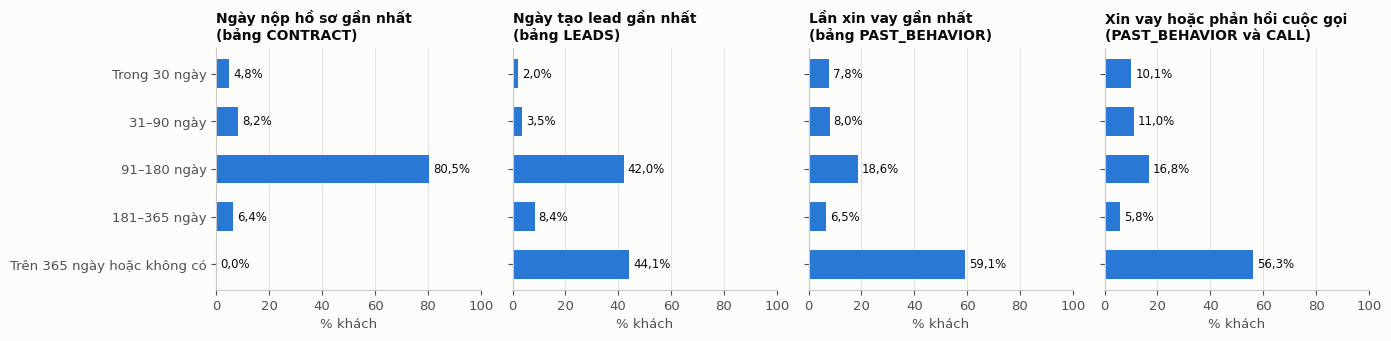

In [11]:
nguon = [('Ngày nộp hồ sơ gần nhất\n(bảng CONTRACT)', 'NGAY_HO_SO'), ('Ngày tạo lead gần nhất\n(bảng LEADS)', 'NGAY_LEAD'),
         ('Lần xin vay gần nhất\n(bảng PAST_BEHAVIOR)', 'NGAY_XIN_VAY'),
         ('Xin vay hoặc phản hồi cuộc gọi\n(PAST_BEHAVIOR và CALL)', 'NGAY_HOAT_DONG')]
fig, axs = plt.subplots(1, 4, figsize=(14, 3.5), sharey=True)
for ax, (ten, cot) in zip(axs, nguon):
    p = phan_bo(chot, cot, NGAY_BINS, NGAY_NHAN)['pct_khach']
    ax.barh(range(len(p)), p.values, color=MAU['xanh'], height=0.6)
    for i, v in enumerate(p.values):
        ax.text(v + 1.5, i, so(v) + '%', va='center', color=MAU['chu'], fontsize=8.5)
    ax.set_title(ten, fontsize=10); ax.set_xlim(0, 100); ax.grid(axis='y', visible=False); ax.set_xlabel('% khách')
axs[0].set_yticks(range(len(NGAY_NHAN))); axs[0].set_yticklabels(NGAY_NHAN); axs[0].invert_yaxis()
fig.tight_layout()
luu_hinh(fig, 'hinh02_ba_cach_do_recency')

*Hình 1. Phân bố khách theo thời gian từ lần gần nhất có hoạt động đến ngày chốt, theo bốn cách đo. Ngày nộp hồ sơ dồn 80,5% khách vào một khoảng và ngày lead dồn theo đợt chào bán, còn lần xin vay và lần xin vay hoặc phản hồi cuộc gọi trải đều hơn. Nguồn: dữ liệu của đề, nhóm tự tính.*

### 1.2. Frequency – khách được liên hệ hoặc tự hoạt động thường xuyên đến đâu

Có hai cách đo: số cuộc gọi với khách (CALL), và số tháng khác nhau khách có lần xin vay (PAST_BEHAVIOR), tính trong 6 tháng gần nhất hoặc trong toàn bộ lịch sử. Số cuộc gọi được đếm trong 90 ngày trước ngày chốt.

In [12]:
print('Số cuộc gọi')
display(phan_bo(chot, 'SO_CUOC_GOI', [-1, 0, 1, 2, 3, 5, 10, 10**6], ['0', '1', '2', '3', '4–5', '6–10', 'Trên 10']))
print('Số tháng có lần xin vay')
pd.concat({'Trong 6 tháng gần nhất': phan_bo(chot, 'SO_THANG_XIN_VAY_6T', [-1, 0, 1, 2, 3, 100], ['0', '1', '2', '3', 'Từ 4'])['pct_khach'],
           'Toàn bộ lịch sử': phan_bo(chot, 'SO_THANG_XIN_VAY', [-1, 0, 1, 2, 3, 100], ['0', '1', '2', '3', 'Từ 4'])['pct_khach']}, axis=1)

Số cuộc gọi


,so_khach,pct_khach
SO_CUOC_GOI,,
0,743061,74.3
1,103479,10.3
2,79761,8.0
3,46852,4.7
4–5,16128,1.6
6–10,9475,0.9
Trên 10,1772,0.2


Số tháng có lần xin vay


,Trong 6 tháng gần nhất,Toàn bộ lịch sử
0,65.6,52.7
1,21.6,20.1
2,6.7,8.5
3,2.9,5.2
Từ 4,3.3,13.5


- **Số cuộc gọi:** 74,3% khách không có cuộc gọi nào trong 90 ngày. Trong số còn lại, phần lớn chỉ có 1–3 cuộc (23,0% khách); chỉ 2,7% khách có từ 4 cuộc.
- **Số tháng có lần xin vay:** 65,6% khách không xin vay lần nào trong 6 tháng gần nhất, và 52,7% chưa từng xin vay trong toàn bộ bảng PAST_BEHAVIOR (từ 12/2022). Chỉ số này đi cùng recency: khách vừa xin vay gần đây thường cũng xin vay ở nhiều tháng.

Điều rút ra: trong 90 ngày, công ty chỉ gọi cho khoảng một phần tư số khách, và thường chỉ 1–3 lần.

### 1.3. Hành vi tương tác – khách phản hồi thế nào khi được liên hệ

Bảng CALL cho biết, trong 90 ngày trước ngày chốt, khách có nghe máy, có tự gọi đến, tổng thời gian nói chuyện (cộng thời lượng các cuộc khách nghe máy hoặc tự gọi đến, đơn vị giây) và có từ chối hay không. Khách phản hồi nghĩa là có nghe máy hoặc có tự gọi đến. Bảng CUSTOMER có số phiên dùng app mỗi tuần năm 2025. Các tỷ lệ về cuộc gọi tính trên khách có ít nhất một cuộc gọi.

In [13]:
co_goi = chot[chot.SO_CUOC_GOI > 0]
display(pd.DataFrame({'chi_so': ['Khách có ít nhất 1 cuộc gọi (trên toàn bộ khách)', 'Có nghe máy ít nhất 1 lần', 'Có tự gọi đến', 'Có nghe máy hoặc tự gọi đến', 'Có nói chuyện (thời gian > 0)',
                                 'Nói chuyện tổng cộng trên 60 giây', 'Nói chuyện tổng cộng trên 180 giây', 'Có ít nhất 1 lần từ chối'],
                      'so_khach': [len(co_goi), (co_goi.SO_CUOC_NGHE_MAY > 0).sum(), (co_goi.SO_CUOC_GOI_DEN > 0).sum(), (co_goi.SO_CUOC_PHAN_HOI > 0).sum(), (co_goi.GIAY_NOI_CHUYEN > 0).sum(),
                                   (co_goi.GIAY_NOI_CHUYEN > 60).sum(), (co_goi.GIAY_NOI_CHUYEN > 180).sum(), (co_goi.SO_CUOC_TU_CHOI > 0).sum()]})
        .assign(pct=lambda t: (t.so_khach / np.r_[len(chot), [len(co_goi)] * 7] * 100).round(1)))
print('Tổng thời gian nói chuyện, khách có cuộc gọi')
display(phan_bo(co_goi, 'GIAY_NOI_CHUYEN', [-1, 0, 30, 60, 120, 180, 300, 10**7], ['0', '1–30', '31–60', '61–120', '121–180', '181–300', 'Trên 300']))
print('Số phiên dùng app mỗi tuần năm 2025, toàn bộ khách')
phan_bo(chot, 'PHIEN_APP_TUAN', [-1, 0, 0.999, 10**6], ['Không dùng', 'Dưới 1 lần/tuần', 'Từ 1 lần/tuần'])

,chi_so,so_khach,pct
0,Khách có ít nhất 1 cuộc gọi (trên toàn bộ khách),257467,25.7
1,Có nghe máy ít nhất 1 lần,57641,22.4
2,Có tự gọi đến,15155,5.9
3,Có nghe máy hoặc tự gọi đến,70012,27.2
4,Có nói chuyện (thời gian > 0),50519,19.6
5,Nói chuyện tổng cộng trên 60 giây,6802,2.6
6,Nói chuyện tổng cộng trên 180 giây,2285,0.9
7,Có ít nhất 1 lần từ chối,23844,9.3


Tổng thời gian nói chuyện, khách có cuộc gọi


,so_khach,pct_khach
GIAY_NOI_CHUYEN,,
0,206948,80.4
1–30,35243,13.7
31–60,8474,3.3
61–120,3127,1.2
121–180,1390,0.5
181–300,1177,0.5
Trên 300,1108,0.4


Số phiên dùng app mỗi tuần năm 2025, toàn bộ khách


,so_khach,pct_khach
PHIEN_APP_TUAN,,
Không dùng,930051,93.0
Dưới 1 lần/tuần,50337,5.0
Từ 1 lần/tuần,20140,2.0


Trong 257 nghìn khách có cuộc gọi trong 90 ngày: 22,4% từng nghe máy, 5,9% từng tự gọi đến, gộp lại 27,2% có phản hồi; 19,6% có nói chuyện, nhưng chỉ 2,6% nói chuyện tổng cộng trên 60 giây và 0,9% trên 180 giây. 80,4% khách có cuộc gọi chưa nói chuyện giây nào. 9,3% từng từ chối, nhưng con số này thấp hơn thực tế vì 85% cuộc gọi không có mã kết quả (mục 0.1). Về app, 93,0% khách không dùng app trong năm 2025, chỉ 2,0% dùng từ 1 lần mỗi tuần.

Điều rút ra: được gọi không có nghĩa là khách tương tác. Gần ba phần tư số khách được gọi chưa phản hồi lần nào, và chỉ khoảng 7 nghìn khách, dưới 1% toàn bộ khách, nói chuyện với công ty quá 1 phút trong 90 ngày.

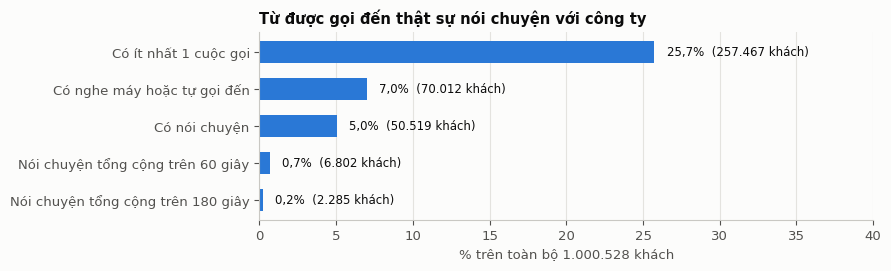

In [14]:
buoc = [('Có ít nhất 1 cuộc gọi', (chot.SO_CUOC_GOI > 0).sum()), ('Có nghe máy hoặc tự gọi đến', (chot.SO_CUOC_PHAN_HOI > 0).sum()),
        ('Có nói chuyện', (chot.GIAY_NOI_CHUYEN > 0).sum()), ('Nói chuyện tổng cộng trên 60 giây', (chot.GIAY_NOI_CHUYEN > 60).sum()),
        ('Nói chuyện tổng cộng trên 180 giây', (chot.GIAY_NOI_CHUYEN > 180).sum())]
fig, ax = plt.subplots(figsize=(9, 2.8))
pct = [v / len(chot) * 100 for _, v in buoc]
ax.barh(range(len(buoc)), pct, color=MAU['xanh'], height=0.6)
for i, ((ten, v), p) in enumerate(zip(buoc, pct)):
    ax.text(p + 0.8, i, f'{so(p)}%  ({so(v, 0)} khách)', va='center', color=MAU['chu'], fontsize=8.5)
ax.set_yticks(range(len(buoc))); ax.set_yticklabels([b for b, _ in buoc]); ax.invert_yaxis()
ax.set_xlim(0, 40); ax.set_xlabel('% trên toàn bộ 1.000.528 khách'); ax.grid(axis='y', visible=False)
ax.set_title('Từ được gọi đến thật sự nói chuyện với công ty')
fig.tight_layout()
luu_hinh(fig, 'hinh03_tu_cuoc_goi_den_noi_chuyen')

*Hình 2. Tỷ lệ khách qua từng bước tương tác qua điện thoại trong 90 ngày trước ngày chốt, tính trên toàn bộ khách. Phần lớn khách không được gọi, và rất ít khách nói chuyện quá 1 phút. Nguồn: dữ liệu của đề, nhóm tự tính.*

### 1.4. Hoạt động lead

Bảng LEADS cho biết khách có bao nhiêu lead, lead đến từ nguồn nào và kết quả ra sao. Có hai cách đếm mức độ khách có lead: đếm **số lead** (mỗi dòng trong bảng LEADS là một lead), và đếm **số tháng khác nhau có lead** (nhiều lead tạo trong cùng một tháng chỉ tính là 1). Ví dụ khách 45 ở trên có 5 lead nhưng chỉ ở 3 tháng, vì 3 lead được tạo cùng lúc ngày 18/01/2025. Hai bảng đầu là phân bố khách theo từng cách đếm; bảng thứ ba là số lead trung bình theo số tháng có lead; hai bảng cuối là cơ cấu lead theo nguồn và theo kết quả, tính trên toàn bộ bảng LEADS.

In [15]:
print('Khách theo số lead (mỗi lead là một dòng trong bảng LEADS)')
display(phan_bo(chot, 'SO_LEAD', [-1, 0, 1, 2, 3, 5, 7, 10**6], ['0 lead', '1 lead', '2 lead', '3 lead', '4–5 lead', '6–7 lead', 'Từ 8 lead']))
print('Khách theo số tháng khác nhau có lead (các lead tạo trong cùng một tháng chỉ tính là 1 tháng)')
display(phan_bo(chot, 'SO_THANG_CO_LEAD', [-1, 0, 1, 2, 3, 4, 5, 10**6], ['0 tháng', '1 tháng', '2 tháng', '3 tháng', '4 tháng', '5 tháng', 'Từ 6 tháng']))
print('Số lead trung bình của khách, theo số tháng có lead')
display(chot.groupby(chot.SO_THANG_CO_LEAD.clip(upper=5)).SO_LEAD.agg(so_khach='size', so_lead_tb='mean').round(2).T)
display(q("select LEAD_SOURCE nguon, count(*) so_lead, round(100.0 * count(*) / sum(count(*)) over (), 1) pct from EN_LEADS group by 1 order by 2 desc"))
q("select DESC_FIN_REASON ket_qua, count(*) so_lead, round(100.0 * count(*) / sum(count(*)) over (), 1) pct from EN_LEADS group by 1 order by 2 desc limit 8")

Khách theo số lead (mỗi lead là một dòng trong bảng LEADS)


,so_khach,pct_khach
SO_LEAD,,
0 lead,355184,35.5
1 lead,203260,20.3
2 lead,135279,13.5
3 lead,111258,11.1
4–5 lead,88334,8.8
6–7 lead,52447,5.2
Từ 8 lead,54766,5.5


Khách theo số tháng khác nhau có lead (các lead tạo trong cùng một tháng chỉ tính là 1 tháng)


,so_khach,pct_khach
SO_THANG_CO_LEAD,,
0 tháng,355184,35.5
1 tháng,391226,39.1
2 tháng,144223,14.4
3 tháng,63002,6.3
4 tháng,27488,2.7
5 tháng,11604,1.2
Từ 6 tháng,7801,0.8


Số lead trung bình của khách, theo số tháng có lead


SO_THANG_CO_LEAD,0,1,2,3,4,5
so_khach,355184.0,391226.00,144223.00,63002.00,27488.00,19405.00
so_lead_tb,0.0,1.77,3.89,6.12,8.39,12.23


,nguon,so_lead,pct
0,RA,1124219,53.4
1,SA,858825,40.8
2,TLS,42731,2.0
3,SOB,38423,1.8
4,GMA,25461,1.2
5,LANDING PAGE,9612,0.5
6,RTDM,5371,0.3


,ket_qua,so_lead,pct
0,Not Interest,1224074,58.2
1,Expire Lifetime,450126,21.4
2,Not Applicable,189679,9.0
3,Deal,57122,2.7
4,Existing Lead On LDS,54849,2.6
5,No Cluster,41677,2.0
6,None,36578,1.7
7,Rejected,22758,1.1


- 35,5% khách chưa có lead nào. Theo số lead: 20,3% có đúng 1 lead, 13,5% có 2 lead, 30,6% có từ 3 lead. Theo số tháng: 39,1% có lead ở đúng 1 tháng, 14,4% ở 2 tháng, và 11,0% ở từ 3 tháng.
- Số lead nhiều hơn số tháng có lead: khách có lead ở 1 tháng có trung bình 1,77 lead, khách có lead ở 5 tháng trở lên có 12,23 lead. Một đợt chào bán thường tạo nhiều lead cho cùng một khách.
- Hai nguồn RA (53,4%) và SA (40,8%) chiếm 94% số lead; nguồn TLS chỉ 2,0%. Bảng mô tả cột của đề (StructureTable) chỉ nêu ví dụ "GMA, SOB, Landing Page" cho cột LEAD_SOURCE, và mô tả GMA là ứng dụng online ở bảng CUSTOMER; các mã RA, SA, TLS không được giải thích. TLS nhiều khả năng là telesales, nhưng đây là suy đoán.
- 58,2% lead kết thúc ở "Not Interest" (khách không quan tâm), 21,4% hết hạn mà không có kết quả, chỉ 2,7% thành Deal.

Điều rút ra: công ty chào bán cho gần hai phần ba số khách, chủ yếu qua hai nguồn RA và SA, nhưng chưa đến 3% lead thành giao dịch.

### 1.5. Tương tác sản phẩm

Có hai loại thông tin về sản phẩm: sản phẩm khách được chào (nhóm sản phẩm của lead và của cuộc gọi) và sản phẩm khách đã ký (CONTRACT). Bảng thứ nhất đếm số nhóm sản phẩm của mỗi khách theo từng cách đo (% khách). Bảng thứ hai đặt số nhóm được chào cạnh số nhóm đã ký (% trên toàn bộ khách).

In [16]:
NHOM_BINS = [-1, 0, 1, 2, 3, 100]; NHOM_NHAN = ['0', '1', '2', '3', 'Từ 4']
display(pd.concat({ten: phan_bo(chot, cot, NHOM_BINS, NHOM_NHAN)['pct_khach']
                   for ten, cot in [('Được chào qua lead', 'SO_SP_CHAO_QUA_LEAD'), ('Được chào qua cuộc gọi', 'SO_SP_CHAO_QUA_GOI'),
                                    ('Được chào qua lead hoặc cuộc gọi', 'SO_SP_DUOC_CHAO'), ('Đã ký (CONTRACT)', 'SO_SP_DA_KY')]}, axis=1))
print('% khách theo số nhóm đã ký (hàng) và số nhóm được chào (cột)')
(pd.crosstab(chot.SO_SP_DA_KY.clip(upper=3), chot.SO_SP_DUOC_CHAO.clip(upper=3), normalize='all') * 100).round(1)

,Được chào qua lead,Được chào qua cuộc gọi,Được chào qua lead hoặc cuộc gọi,Đã ký (CONTRACT)
0,35.5,78.0,31.7,18.2
1,25.4,19.9,23.8,45.1
2,16.3,2.1,19.2,26.6
3,22.1,0.1,24.2,8.7
Từ 4,0.7,0.0,1.1,1.4


% khách theo số nhóm đã ký (hàng) và số nhóm được chào (cột)


SO_SP_DUOC_CHAO,0,1,2,3
SO_SP_DA_KY,,,,
0,16.3,1.6,0.2,0.1
1,10.3,12.2,9.2,13.3
2,4.0,7.3,6.7,8.7
3,1.1,2.6,3.1,3.3


- Qua lead, 64,5% khách được chào ít nhất 1 nhóm sản phẩm; qua cuộc gọi trong 90 ngày, 22,0%. Gộp hai kênh, 68,3% khách được chào ít nhất 1 nhóm và 25,3% được chào từ 3 nhóm.
- 81,8% khách đã ký ít nhất 1 nhóm sản phẩm, phần lớn chỉ 1 nhóm (45,1%).
- Bảng chéo: 16,3% khách chưa ký và cũng chưa được chào gì, nhưng chỉ 1,9% khách chưa từng ký mà đã được chào sản phẩm: công ty chủ yếu chào bán cho khách đã có hợp đồng. 13,3% khách đã ký 1 nhóm và được chào từ 3 nhóm, là nhóm đang được mời dùng thêm sản phẩm.

> **Tóm lại mục 1:** Khoảng 21% khách còn tự xin vay hoặc phản hồi cuộc gọi trong 90 ngày. Trong 90 ngày, công ty gọi cho 26% khách, nhưng chỉ 7% khách phản hồi và dưới 1% nói chuyện quá 1 phút. 64,5% khách có lead nhưng chỉ 2,7% lead thành Deal. Công ty chủ yếu chào sản phẩm cho khách đã có hợp đồng.

## 2. Chọn chỉ số đại diện cho mỗi khía cạnh (yêu cầu 1)

> **Câu hỏi của mục này:** Mỗi khía cạnh nên đo bằng chỉ số nào?
>
> **Cách làm:** liệt kê các chỉ số có thể dùng, loại chỉ số có dữ liệu không đáng tin hoặc trùng thông tin với chỉ số khác, và giữ mỗi khía cạnh đúng một chỉ số.

Mỗi khía cạnh cần đúng một chỉ số để điểm đơn giản và giải thích được. Một chỉ số được chọn khi thỏa ba điều kiện:

1. Đo đúng ý nghĩa của khía cạnh.
2. Dữ liệu đáng tin, dựa trên mục 0 và mục 1.
3. Không lặp lại thông tin của chỉ số đã chọn cho khía cạnh khác.

Điều kiện 3 được đo bằng tương quan thứ hạng giữa hai chỉ số: xếp khách theo từng chỉ số rồi xem hai thứ tự giống nhau đến đâu. Tương quan gần 1 nghĩa là hai chỉ số xếp khách gần như giống hệt nhau, dùng cả hai là tính một thông tin hai lần; gần 0 nghĩa là hai chỉ số mang thông tin khác nhau. Với các chỉ số đếm ngày (các chỉ số "gần đây"), số ngày được đổi dấu để giá trị lớn hơn nghĩa là hoạt động gần đây hơn, cùng chiều với các chỉ số khác.

Ô code dưới in hai bảng. Bảng thứ nhất chỉ gồm các cặp chỉ số được dùng để quyết định ở từng khía cạnh. Bảng thứ hai là bảng tương quan đầy đủ của 16 chỉ số ứng viên: mỗi ô là tương quan giữa chỉ số ở hàng và chỉ số ở cột, đường chéo luôn bằng 1, và bảng đối xứng qua đường chéo.

Các cặp chỉ số dùng để quyết định ở từng khía cạnh


,khia_canh,chi_so_1,chi_so_2,tuong_quan
0,Recency,Xin vay hoặc phản hồi cuộc gọi gần đây,Xin vay gần đây (PAST_BEHAVIOR),0.92
1,Recency,Xin vay hoặc phản hồi cuộc gọi gần đây,Phản hồi cuộc gọi gần đây (CALL),0.41
2,Recency,Được gọi gần đây (CALL),Số cuộc gọi (CALL),0.99
3,Frequency,Xin vay hoặc phản hồi cuộc gọi gần đây,Số tháng có xin vay trong 6 tháng (PAST_BEHAVIOR),0.85
4,Frequency,Xin vay hoặc phản hồi cuộc gọi gần đây,"Số tháng có xin vay, toàn bộ lịch sử (PAST_BEHAVIOR)",0.81
5,Frequency,Xin vay hoặc phản hồi cuộc gọi gần đây,Số cuộc gọi (CALL),0.37
6,Hành vi tương tác,Số lần phản hồi cuộc gọi (CALL),Thời gian nói chuyện (CALL),0.84
7,Hành vi tương tác,Số cuộc gọi (CALL),Số lần phản hồi cuộc gọi (CALL),0.47
8,Hành vi tương tác,Xin vay hoặc phản hồi cuộc gọi gần đây,Số lần phản hồi cuộc gọi (CALL),0.41
9,Hoạt động lead,Số lead (LEADS),Số tháng có lead (LEADS),0.94


Bảng tương quan đầy đủ của 16 chỉ số ứng viên


,Xin vay hoặc phản hồi cuộc gọi gần đây,Xin vay gần đây (PAST_BEHAVIOR),Phản hồi cuộc gọi gần đây (CALL),Được gọi gần đây (CALL),Số tháng có xin vay trong 6 tháng (PAST_BEHAVIOR),"Số tháng có xin vay, toàn bộ lịch sử (PAST_BEHAVIOR)",Số cuộc gọi (CALL),Số lần phản hồi cuộc gọi (CALL),Thời gian nói chuyện (CALL),Số lead (LEADS),Số tháng có lead (LEADS),Số nguồn lead (LEADS),Số nhóm sản phẩm chào qua lead (LEADS),Số nhóm sản phẩm chào qua cuộc gọi (CALL),Số nhóm sản phẩm được chào qua lead hoặc cuộc gọi,Số nhóm sản phẩm đã ký (CONTRACT)
Xin vay hoặc phản hồi cuộc gọi gần đây,1.00,0.92,0.41,0.37,0.85,0.81,0.37,0.41,0.34,0.11,0.16,0.12,0.08,0.30,0.13,0.40
Xin vay gần đây (PAST_BEHAVIOR),0.92,1.00,0.11,0.24,0.93,0.88,0.24,0.11,0.08,0.08,0.13,0.10,0.05,0.17,0.08,0.40
Phản hồi cuộc gọi gần đây (CALL),0.41,0.11,1.00,0.46,0.09,0.11,0.47,1.00,0.84,0.11,0.11,0.10,0.10,0.44,0.18,0.14
Được gọi gần đây (CALL),0.37,0.24,0.46,1.00,0.21,0.24,0.99,0.46,0.38,0.21,0.22,0.20,0.19,0.88,0.36,0.29
Số tháng có xin vay trong 6 tháng (PAST_BEHAVIOR),0.85,0.93,0.09,0.21,1.00,0.80,0.22,0.09,0.07,0.06,0.10,0.08,0.03,0.14,0.06,0.38
"Số tháng có xin vay, toàn bộ lịch sử (PAST_BEHAVIOR)",0.81,0.88,0.11,0.24,0.80,1.00,0.24,0.11,0.08,0.10,0.16,0.11,0.06,0.17,0.09,0.46
Số cuộc gọi (CALL),0.37,0.24,0.47,0.99,0.22,0.24,1.00,0.47,0.39,0.21,0.22,0.20,0.19,0.87,0.35,0.30
Số lần phản hồi cuộc gọi (CALL),0.41,0.11,1.00,0.46,0.09,0.11,0.47,1.00,0.84,0.11,0.11,0.10,0.10,0.44,0.18,0.14
Thời gian nói chuyện (CALL),0.34,0.08,0.84,0.38,0.07,0.08,0.39,0.84,1.00,0.09,0.10,0.09,0.09,0.40,0.16,0.11
Số lead (LEADS),0.11,0.08,0.11,0.21,0.06,0.10,0.21,0.11,0.09,1.00,0.94,0.94,0.97,0.22,0.93,0.46


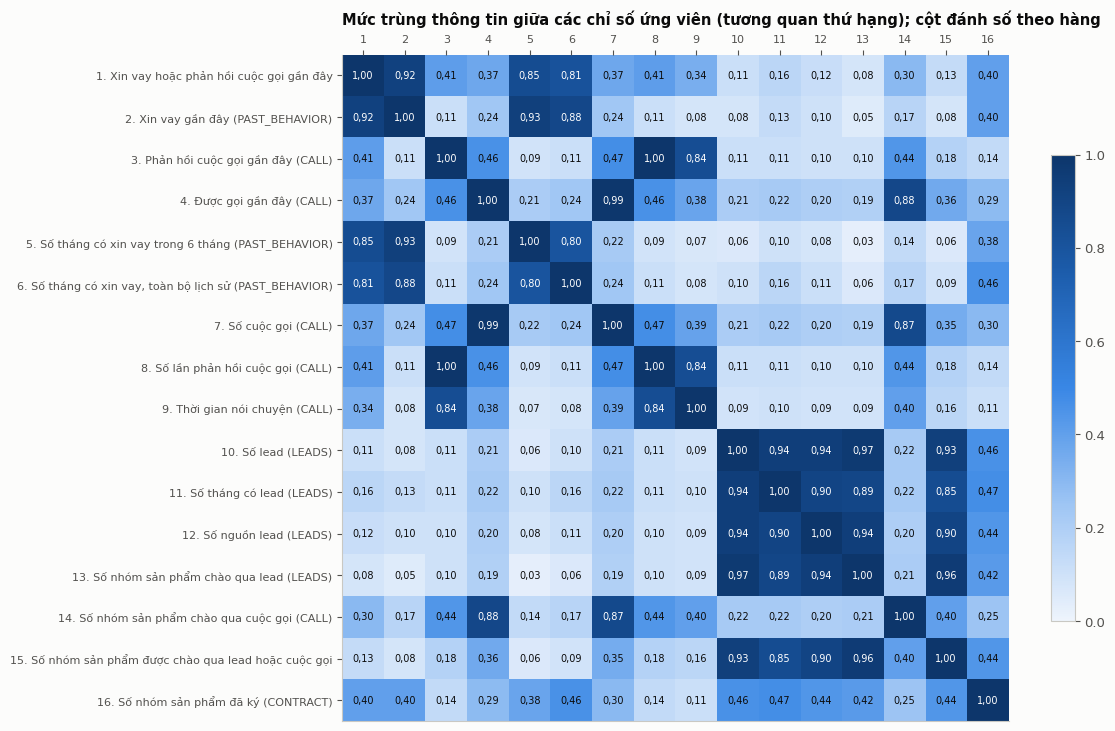

In [17]:
HD = 'Xin vay hoặc phản hồi cuộc gọi gần đây'
XV = 'Xin vay gần đây (PAST_BEHAVIOR)'
PHG = 'Phản hồi cuộc gọi gần đây (CALL)'
GG = 'Được gọi gần đây (CALL)'
XV6 = 'Số tháng có xin vay trong 6 tháng (PAST_BEHAVIOR)'
XVT = 'Số tháng có xin vay, toàn bộ lịch sử (PAST_BEHAVIOR)'
CG = 'Số cuộc gọi (CALL)'
NC = 'Thời gian nói chuyện (CALL)'
PH = 'Số lần phản hồi cuộc gọi (CALL)'
SL = 'Số lead (LEADS)'
TL = 'Số tháng có lead (LEADS)'
NL = 'Số nguồn lead (LEADS)'
SPL = 'Số nhóm sản phẩm chào qua lead (LEADS)'
SPG = 'Số nhóm sản phẩm chào qua cuộc gọi (CALL)'
SPC = 'Số nhóm sản phẩm được chào qua lead hoặc cuộc gọi'
SPK = 'Số nhóm sản phẩm đã ký (CONTRACT)'
ung_vien = pd.DataFrame({HD: -chot.NGAY_HOAT_DONG.clip(upper=400), XV: -chot.NGAY_XIN_VAY.clip(upper=400),
                         PHG: -chot.NGAY_PH_GOI.clip(upper=400), GG: -chot.NGAY_GOI.clip(upper=400), XV6: chot.SO_THANG_XIN_VAY_6T, XVT: chot.SO_THANG_XIN_VAY,
                         CG: chot.SO_CUOC_GOI, PH: chot.SO_CUOC_PHAN_HOI, NC: chot.GIAY_NOI_CHUYEN, SL: chot.SO_LEAD, TL: chot.SO_THANG_CO_LEAD, NL: chot.SO_NGUON_LEAD,
                         SPL: chot.SO_SP_CHAO_QUA_LEAD, SPG: chot.SO_SP_CHAO_QUA_GOI, SPC: chot.SO_SP_DUOC_CHAO, SPK: chot.SO_SP_DA_KY})
tuong_quan = ung_vien.rank().corr().round(2)
del ung_vien
print('Các cặp chỉ số dùng để quyết định ở từng khía cạnh')
display(pd.DataFrame([(k, a, b, tuong_quan.loc[a, b]) for k, a, b in [
    ('Recency', HD, XV), ('Recency', HD, PHG), ('Recency', GG, CG),
    ('Frequency', HD, XV6), ('Frequency', HD, XVT), ('Frequency', HD, CG),
    ('Hành vi tương tác', PH, NC), ('Hành vi tương tác', CG, PH), ('Hành vi tương tác', HD, PH),
    ('Hoạt động lead', SL, TL), ('Hoạt động lead', SL, NL), ('Hoạt động lead', TL, NL),
    ('Tương tác sản phẩm', SPL, TL), ('Tương tác sản phẩm', SPG, CG), ('Tương tác sản phẩm', SPC, TL), ('Tương tác sản phẩm', SPC, CG),
    ('Tương tác sản phẩm', SPK, HD), ('Tương tác sản phẩm', SPK, CG), ('Tương tác sản phẩm', SPK, PH), ('Tương tác sản phẩm', SPK, TL)]],
    columns=['khia_canh', 'chi_so_1', 'chi_so_2', 'tuong_quan']))
print('Bảng tương quan đầy đủ của 16 chỉ số ứng viên')
display(tuong_quan)
fig, ax = plt.subplots(figsize=(11, 7.4))
im = ax.imshow(tuong_quan.values, cmap=CMAP_XANH, vmin=0, vmax=1)
ax.set_xticks(range(len(tuong_quan))); ax.set_xticklabels(range(1, len(tuong_quan) + 1), fontsize=8)
ax.set_yticks(range(len(tuong_quan))); ax.set_yticklabels([f'{i}. {n}' for i, n in enumerate(tuong_quan.index, 1)], fontsize=8)
ax.xaxis.tick_top()
for i in range(len(tuong_quan)):
    for j in range(len(tuong_quan)):
        v = tuong_quan.values[i, j]
        ax.text(j, i, so(v, 2), ha='center', va='center', fontsize=7, color='white' if v > 0.6 else MAU['chu'])
ax.grid(False); ax.set_title('Mức trùng thông tin giữa các chỉ số ứng viên (tương quan thứ hạng); cột đánh số theo hàng', pad=22)
fig.colorbar(im, ax=ax, shrink=0.7)
fig.tight_layout()
luu_hinh(fig, 'hinh04_tuong_quan_chi_so')

*Hình 3. Tương quan thứ hạng giữa 16 chỉ số ứng viên; ô càng đậm thì hai chỉ số càng trùng thông tin. Nguồn: dữ liệu của đề, nhóm tự tính.*

**Recency – chọn số ngày từ lần gần nhất khách xin vay hoặc phản hồi cuộc gọi.**

Các cách đo bị loại:

- *Ngày nộp hồ sơ gần nhất (bảng CONTRACT).* 80,5% khách nộp hồ sơ lần cuối trong cùng một khoảng 91–180 ngày trước ngày chốt, và không khách nào quá 365 ngày (mục 1.1), vì danh sách khách được chọn từ đợt nộp hồ sơ 12/2024–01/2025. Chỉ số gần như giống nhau ở mọi khách nên không tách được khách đã lâu không quay lại. Ngoài ra, CONTRACT là bảng ghi việc ký hợp đồng, tức kết quả kinh doanh mà điểm cần dự báo được theo yêu cầu 6 của đề.
- *Ngày tạo lead gần nhất (bảng LEADS).* Lead do công ty tạo, không phải việc khách làm. 42,0% khách có lead cuối cùng 91–180 ngày trước ngày chốt, trùng với đợt chào bán 975 nghìn lead trong 12/2024–01/2025 (mục 1.1), nên chỉ số này phản ánh lịch chào bán của công ty.
- *Ngày được gọi gần nhất (bảng CALL).* Việc gọi do công ty quyết định, không phải việc khách làm. Chỉ số này còn tương quan 0,99 với số cuộc gọi: trong 90 ngày, khách được gọi gần đây cũng là khách được gọi nhiều lần.
- *Chỉ lần xin vay gần nhất (bảng PAST_BEHAVIOR).* Đây là việc khách chủ động làm, nhưng bỏ sót những khách không xin vay mà vẫn phản hồi khi công ty gọi.
- *Chỉ lần phản hồi cuộc gọi gần nhất (bảng CALL).* Chỉ 7,0% khách phản hồi cuộc gọi trong 90 ngày (mục 1.1), nên nếu đứng riêng, gần như mọi khách có cùng một giá trị.

Lý do chọn: chỉ số gộp hai việc khách tự làm. Nó trùng nhiều với lần xin vay (tương quan 0,92) vì phần lớn khách không phản hồi cuộc gọi, nhưng thêm được những khách vừa phản hồi cuộc gọi mà không xin vay: 21,1% khách có hoạt động trong 90 ngày, so với 15,8% nếu chỉ tính xin vay (mục 1.1).

**Frequency – chọn số cuộc gọi trong 90 ngày (bảng CALL, không tính cuộc gọi mã OWN).**

Các cách đo bị loại:

- *Số tháng có lần xin vay trong 6 tháng gần nhất (bảng PAST_BEHAVIOR).* Tương quan 0,85 với recency đã chọn, tức gần như lặp lại recency: khách vừa xin vay gần đây cũng là khách có lần xin vay trong nhiều tháng gần đây.
- *Số tháng có lần xin vay trong toàn bộ lịch sử.* Tương quan 0,81 với recency, cùng lý do.

Lý do chọn: số cuộc gọi chỉ tương quan 0,37 với recency, nên mang thông tin khác, cho biết công ty liên hệ khách thường xuyên đến đâu.

**Hành vi tương tác – chọn việc khách có phản hồi cuộc gọi hay không (bảng CALL).**

Chỉ số có ba giá trị: không có cuộc gọi trong 90 ngày, có cuộc gọi nhưng chưa lần nào phản hồi, và có ít nhất một lần nghe máy hoặc tự gọi đến.

Các cách đo bị loại:

- *Tổng thời gian nói chuyện.* Tương quan 0,84 với số lần phản hồi, tức gần như cùng một thông tin. Nhưng chỉ 50.519 khách, khoảng 5% toàn bộ khách, nói chuyện giây nào trong 90 ngày (mục 1.3), nên không chia nhỏ được thành nhiều mức mà mỗi mức có đủ khách.
- *Có từ chối hay không.* 85,3% cuộc gọi không có mã kết quả (mục 0.1), nên phần lớn các lần khách từ chối không được ghi lại.
- *Số phiên dùng app (bảng CUSTOMER).* Chỉ 7% khách có dùng app (mục 1.3). Đây là số trung bình của cả năm 2025, gồm cả các tháng sau ngày chốt (06–12/2025), nên chứa thông tin xảy ra sau ngày tính điểm. Và đây không phải cách khách phản hồi khi công ty liên hệ.

Lý do chọn: phản hồi cuộc gọi tương quan 0,47 với số cuộc gọi và 0,41 với recency. Hai chỉ số kia có liên quan vì khách phải được gọi mới phản hồi được, và lần phản hồi gần nhất cũng nằm trong recency, nhưng không trùng nhau.

**Hoạt động lead – chọn số tháng khác nhau có lead (bảng LEADS).**

Các cách đo bị loại:

- *Số lead.* Tương quan 0,94 với số tháng có lead, gần như cùng một thông tin. Nhưng số lead đếm lặp các lead trong cùng một đợt chào bán: khách có lead ở đúng 1 tháng có trung bình 1,77 lead (mục 1.4), như khách 45 có 3 lead tạo cùng ngày 18/01/2025.
- *Số nguồn lead.* Tương quan 0,90 với số tháng có lead và 0,94 với số lead, nên không thêm thông tin.
- *Kết quả lead (cột `DESC_FIN_REASON`, phản hồi của khách).* Bảng LEADS không ghi ngày khách phản hồi. Ở một ngày bất kỳ, không biết phản hồi đã có trước ngày đó hay chưa, nên dùng chỉ số này có thể đưa thông tin xảy ra sau ngày tính điểm vào điểm.

**Tương tác sản phẩm – chọn số nhóm sản phẩm khác nhau được chào qua lead hoặc cuộc gọi.**

Các cách đo bị loại:

- *Số nhóm sản phẩm chào qua lead.* Tương quan 0,89 với số tháng có lead, gần như lặp lại khía cạnh hoạt động lead.
- *Số nhóm sản phẩm chào qua cuộc gọi.* Tương quan 0,87 với số cuộc gọi, gần như lặp lại frequency.
- *Số nhóm sản phẩm đã ký (bảng CONTRACT), và các chỉ số khác tính từ hợp đồng như tỷ lệ hồ sơ được ký.* Số nhóm đã ký trùng ít với các chỉ số đã chọn (tương quan 0,14–0,47), nhưng bị loại vì hai lý do. Một, đây là kết quả của các lần vay trước, không phải cách khách tương tác với hoạt động chào bán. Hai, việc khách ký hợp đồng mới chính là kết quả kinh doanh mà điểm cần dự báo được (yêu cầu 6 của đề); nếu đưa số sản phẩm đã ký hay tỷ lệ ký vào điểm, khách có điểm cao chủ yếu vì đã ký nhiều, rồi điểm lại được "chứng minh" bằng việc chính những khách đó ký tiếp.

Lý do chọn: gộp hai kênh làm giảm mức trùng, còn 0,85 với số tháng có lead và 0,35 với số cuộc gọi. Mức trùng với lead vẫn cao vì sản phẩm chủ yếu được chào qua lead.

> **Tóm lại mục 2:** Năm chỉ số được chọn: số ngày từ lần gần nhất khách xin vay hoặc phản hồi cuộc gọi (recency), số cuộc gọi trong 90 ngày (frequency), việc khách có phản hồi cuộc gọi hay không (hành vi tương tác), số tháng có lead (hoạt động lead), và số nhóm sản phẩm được chào qua lead hoặc cuộc gọi (tương tác sản phẩm).

## 3. Xây điểm Engagement (yêu cầu 3)

> **Câu hỏi của mục này:** Điểm Engagement của một khách được tính thế nào?
>
> **Cách làm:** mỗi chỉ số ở mục 2 được chia thành 3–4 mức, mức thấp nhất 0 điểm, cao nhất 20 điểm; cộng 5 chỉ số được điểm từ 0 đến 100. Ngưỡng giữa các mức được chọn sao cho mức cao hơn có tỷ lệ ký hợp đồng mới cao hơn. Tổng điểm được tách thành hai phần: Tiếp cận (công ty liên hệ khách nhiều hay ít) và Phản hồi (khách có tự chủ động không).

Điểm Engagement được xây theo kiểu **bảng điểm cộng dồn**, không phải mô hình học máy. Mỗi chỉ số ở mục 2 được chia thành 3–4 mức, mỗi mức có một số điểm cố định, và điểm của khách là tổng điểm của 5 mức mà khách rơi vào, từ 0 đến 100. Ví dụ, một khách được gọi 2 cuộc trong 90 ngày sẽ nhận đúng số điểm của mức đó, ai tính lại cũng ra cùng kết quả.

Lý do không dùng mô hình học máy:

- Đề yêu cầu điểm dễ giải thích. Với bảng điểm, người dùng nhìn một khách là biết khách được bao nhiêu điểm ở từng khía cạnh và mất điểm ở đâu, không cần chạy lại mô hình.
- Mô hình học máy cần một cột đáp án để học, nhưng dữ liệu không có cột nào cho biết khách có gắn kết hay không. Nếu lấy việc ký hợp đồng làm đáp án, mô hình cho ra điểm "khả năng ký", không phải điểm tương tác.

Việc ký hợp đồng chỉ được dùng để chọn chỗ đặt ngưỡng giữa các mức, sao cho mức cao hơn có tỷ lệ ký mới cao hơn. Số điểm của mỗi mức được chia đều, không do dữ liệu quyết định.

**Toàn bộ quá trình gồm ba giai đoạn, mỗi giai đoạn dùng dữ liệu ở một khoảng thời gian khác nhau:**

| Giai đoạn | Chỉ số của khách tính từ dữ liệu | Kết quả dùng để đánh giá | Làm gì |
|---|---|---|---|
| **1. Xây điểm** | trước 01/05/2025 | khách nào ký hợp đồng mới trong tháng 05/2025 | chọn ngưỡng chia mức; đây là bản điểm dùng thật |
| **2. Kiểm tra cách xây** | xây lại: trước 01/04/2025 | xây lại: khách nào ký mới trong tháng 04/2025 | làm lại giai đoạn 1 bằng dữ liệu cũ hơn một tháng |
| | kiểm tra: trước 01/05/2025 | kiểm tra: khách nào ký mới trong tháng 05/2025 | đo bản xây lại trên tháng 05, tháng nằm sau toàn bộ dữ liệu đã dùng để xây lại |
| **3. Chấm điểm thật** | trước ngày chốt 05/06/2025 | chưa có, vì chưa xảy ra | tính điểm cho toàn bộ 1.000.528 khách bằng bản ở giai đoạn 1 |

Giai đoạn 1 tương tự bước huấn luyện, giai đoạn 2 tương tự bước kiểm tra trên dữ liệu tương lai, và giai đoạn 3 là đem cách chấm ra dùng. Khác ở chỗ thứ được "huấn luyện" chỉ là vị trí các ngưỡng, không phải một mô hình.

Giai đoạn 2 không kiểm tra thẳng bản ở giai đoạn 1, vì không còn tháng kết quả nào sau 05/2025. Thay vào đó, nó kiểm tra **cách xây**: nếu cùng một cách xây, làm trên dữ liệu đến hết tháng 04, dự báo đúng tháng 05 mà nó chưa thấy, thì bản xây trên dữ liệu mới nhất cũng đáng tin. Cách làm này tránh rò rỉ dữ liệu: bản xây lại không dùng bất kỳ thông tin nào của tháng 05.

Mục 3 làm giai đoạn 1, theo thứ tự:

- **3.1.** Chọn kết quả kinh doanh dùng để đánh giá: vì sao là ký hợp đồng mới.
- **3.2.** Chọn mốc thời gian: vì sao xây trên mốc 01/05/2025.
- **3.3.** Chọn ngưỡng chia mức cho từng chỉ số.
- **3.4.** Đổi mức thành điểm.
- **3.5.** Tách tổng điểm thành hai điểm con.

Mục 4 chia điểm thành nhóm khách. Giai đoạn 2 là mục 6, giai đoạn 3 là mục 7.

### 3.1. Kết quả kinh doanh dùng làm thước đo

Dữ liệu không có cột nào cho biết khách có gắn kết hay không, nên không thể so điểm với một đáp án có sẵn. Cách kiểm tra là dựa vào ý nghĩa của engagement: khách gắn kết hơn thì sau đó phải có khả năng quay lại làm điều có giá trị cho công ty cao hơn. Một kết quả dùng được làm thước đo cần năm điều kiện:

1. là việc khách chủ động làm, không phải việc công ty làm;
2. có ngày đáng tin, để biết nó xảy ra sau ngày tính điểm;
3. có giá trị kinh doanh;
4. đủ nhiều trường hợp để tỷ lệ của từng nhóm khách ổn định;
5. áp dụng được cho mọi khách.

Trong các bảng của đề, chỉ có ba việc khách làm sau ngày tính điểm mà có ngày ghi lại và có giá trị kinh doanh: ký hợp đồng mới và nộp hồ sơ mới (bảng CONTRACT), và lead thành Deal (bảng LEADS). Các nguồn khác không dùng được: cuộc gọi phần lớn do công ty chủ động, còn việc khách phản hồi cuộc gọi đã nằm trong các chỉ số của điểm (mục 2); số phiên dùng app trong bảng CUSTOMER là số trung bình của cả năm 2025, không có ngày; lần xin vay trong bảng PAST_BEHAVIOR đã nằm trong chỉ số recency của điểm (mục 2), nên không thể vừa làm chỉ số vừa làm thước đo.

Bảng dưới đếm ba kết quả này ở hai tháng 04/2025 và 05/2025. Nộp hồ sơ mới tính cả hồ sơ bị từ chối.

In [18]:
def tinh_ket_qua(tu, den, ten_bang):
    con.execute(f"""
    CREATE OR REPLACE TABLE {ten_bang} AS
    SELECT k.SKP_CLIENT,
           coalesce(max(c.IS_SIGNED), 0) AS KY_MOI,
           (count(c.SKP_CLIENT) > 0)::INT AS NOP_MOI,
           coalesce(sum(c.AMT_CREDIT_ADJ) FILTER (WHERE c.IS_SIGNED = 1), 0) AS TIEN_KY_MOI
    FROM EN_CUSTOMER k
    LEFT JOIN EN_CONTRACT c ON c.SKP_CLIENT = k.SKP_CLIENT
         AND c.APPLY_CONTRACT_TIME >= TIMESTAMP '{tu}' AND c.APPLY_CONTRACT_TIME < TIMESTAMP '{den}'
    GROUP BY 1""")

tinh_ket_qua('2025-05-01', '2025-06-01', 'KQ_CHINH')
tinh_ket_qua('2025-04-01', '2025-05-01', 'KQ_KIEM_TRA')
q("""
select 'Tháng 05/2025' thang, count(*) so_khach, sum(KY_MOI) so_khach_ky_moi, round(100 * avg(KY_MOI), 2) pct_ky_moi,
       sum(NOP_MOI) so_khach_nop_moi, round(100 * avg(NOP_MOI), 2) pct_nop_moi,
       (select count(distinct SKP_CLIENT) from EN_LEADS where DESC_FIN_REASON = 'Deal' and DTIME_CREATED >= '2025-05-01' and DTIME_CREATED < '2025-06-01') so_khach_co_deal
from KQ_CHINH
union all
select 'Tháng 04/2025', count(*), sum(KY_MOI), round(100 * avg(KY_MOI), 2), sum(NOP_MOI), round(100 * avg(NOP_MOI), 2),
       (select count(distinct SKP_CLIENT) from EN_LEADS where DESC_FIN_REASON = 'Deal' and DTIME_CREATED >= '2025-04-01' and DTIME_CREATED < '2025-05-01')
from KQ_KIEM_TRA
""")

,thang,so_khach,so_khach_ky_moi,pct_ky_moi,so_khach_nop_moi,pct_nop_moi,so_khach_co_deal
0,Tháng 05/2025,1000528,33955.0,3.39,50433.0,5.04,867
1,Tháng 04/2025,1000528,33226.0,3.32,50572.0,5.05,763


Ô code dưới tính thêm hai con số ở tháng 05/2025: trong số khách nộp hồ sơ mới có bao nhiêu % được ký, và khách có lead thành Deal có nằm sẵn trong nhóm ký mới hay không.

In [19]:
# (1) trong số khách nộp hồ sơ mới, bao nhiêu % được ký (phần phụ thuộc việc công ty duyệt)
# (2) khách có lead thành Deal có nằm sẵn trong nhóm ký mới hay không
q("""
with hs as (select SKP_CLIENT, max(IS_SIGNED) ky from EN_CONTRACT
            where APPLY_CONTRACT_TIME >= '2025-05-01' and APPLY_CONTRACT_TIME < '2025-06-01' group by 1),
     deal as (select distinct SKP_CLIENT from EN_LEADS
              where DESC_FIN_REASON = 'Deal' and DTIME_CREATED >= '2025-05-01' and DTIME_CREATED < '2025-06-01')
select (select count(*) from hs) so_khach_nop_moi,
       (select sum(ky) from hs) so_khach_ky_moi,
       (select round(100.0 * sum(ky) / count(*), 1) from hs) pct_nop_duoc_ky,
       (select count(*) from deal) so_khach_deal,
       (select count(*) from deal join hs using (SKP_CLIENT)) deal_co_nop_moi,
       (select sum(ky) from deal join hs using (SKP_CLIENT)) deal_co_ky_moi
""")

,so_khach_nop_moi,so_khach_ky_moi,pct_nop_duoc_ky,so_khach_deal,deal_co_nop_moi,deal_co_ky_moi
0,50433,33955.0,67.3,867,864,863.0


Đối chiếu ba kết quả với năm điều kiện:

- **Ký hợp đồng mới** đạt cả năm điều kiện: khoảng 33 nghìn khách mỗi tháng (3,3–3,4%), ngày nộp hồ sơ đáng tin (mục 0), và là khoản vay thật mang lại doanh thu. Điểm yếu là kết quả còn phụ thuộc việc công ty duyệt: chỉ 67,3% khách nộp hồ sơ tháng 05/2025 được ký. Đây là thước đo chính.
- **Nộp hồ sơ mới** (khoảng 50 nghìn khách, 5,0%) đo ý định vay của khách bất kể hồ sơ có được duyệt hay không, nên bù cho điểm yếu trên. Đây là thước đo phụ.
- **Lead thành Deal** bị loại vì ba lý do. Chỉ 763–867 khách mỗi tháng, nên tỷ lệ của một nhóm nhỏ dao động mạnh. Bảng LEADS chỉ có ngày tạo lead, không có ngày ra kết quả Deal. Và Deal gần như nằm sẵn trong nhóm ký mới: 863 trong 867 khách có Deal tháng 05/2025 cũng ký hợp đồng mới trong tháng đó.

Ký hợp đồng mới không phải là sự gắn kết, mà là một việc thường xảy ra khi khách gắn kết. Có khách tương tác nhiều nhưng không ký vì tháng đó không cần vay hoặc bị từ chối, và có khách ít tương tác nhưng vẫn ký. Vì vậy điểm không thể khớp hoàn toàn với việc ký.

Nếu khách điểm cao ký mới nhiều hơn, điều đó cho thấy điểm giúp chọn đúng khách cần ưu tiên. Nhưng điều đó chưa cho thấy tăng tương tác sẽ làm khách ký. Ví dụ, khách nhiều cuộc gọi ký nhiều hơn có thể vì cuộc gọi thuyết phục được khách, cũng có thể vì công ty gọi nhiều hơn cho những khách vốn đã sắp vay.

### 3.2. Chọn mốc thời gian để tính chỉ số và kết quả

**Cách làm:** đứng ở một ngày trong quá khứ (gọi là mốc), chấm điểm khách bằng những gì đã biết đến ngày đó, rồi xem tháng tiếp theo khách nào ký hợp đồng mới. Với mốc 01/05/2025:

| | Lấy dữ liệu trong khoảng | Dùng để |
|---|---|---|
| **Chỉ số** | trước 01/05/2025 | chấm điểm khách |
| **Kết quả** | 01/05/2025 – 31/05/2025 | xem khách nào ký hợp đồng mới |

**Vì sao phải tách hai khoảng:** nếu chỉ số tính cả tháng 05, việc ký có thể tự đẩy chỉ số lên. Ví dụ, khách ký hợp đồng ngày 10/05 thì cũng vừa nộp hồ sơ, và lần nộp đó thường đi kèm một lần xin vay trong bảng PAST_BEHAVIOR, làm chỉ số "xin vay gần đây" tăng. Khi đó chỉ số chỉ đang ghi lại việc ký, không phải dự báo việc ký.

**Mốc cần thỏa hai điều kiện:**

- *Còn đủ một tháng kết quả sau mốc.* Dữ liệu hợp đồng kết thúc ngày 04/06/2025 (mục 0), nên tháng cuối cùng còn đủ dữ liệu là 05/2025 và mốc muộn nhất là 01/05/2025.
- *Khách ở mốc giống khách ở ngày chốt.* Ngày chốt (05/06/2025, mục 0) là ngày tính điểm cuối cùng cho mọi khách, và ngưỡng chọn ở mốc sẽ được dùng để chấm điểm ở ngày đó. Nếu ở mốc gần như ai cũng vừa nộp hồ sơ, còn ở ngày chốt thì không, ngưỡng chọn ở mốc sẽ không hợp với ngày chốt.

Bảng dưới so sánh ba mốc gần nhất (01/03, 01/04 và 01/05/2025) với ngày chốt để kiểm tra điều kiện thứ hai.

In [20]:
dong = []
for ngay, bang in [('01/03/2025', 'CS90_2025_03'), ('01/04/2025', 'CS90_KIEM_TRA'), ('01/05/2025', 'CS90_CHINH'), ('Ngày chốt 05/06/2025', 'CS90_CHOT')]:
    dong.append(q(f"""select '{ngay}' ngay,
        round(100.0 * count(*) filter (where SO_NGAY_TU_LAN_NOP_HO_SO <= 90) / count(*), 1) pct_nop_ho_so_trong_90_ngay,
        round(100.0 * count(*) filter (where SO_NGAY_TU_LAN_XIN_VAY <= 30) / count(*), 1) pct_xin_vay_trong_30_ngay,
        round(100.0 * count(*) filter (where SO_NGAY_TU_LAN_XIN_VAY <= 90) / count(*), 1) pct_xin_vay_trong_90_ngay,
        round(100.0 * count(*) filter (where SO_THANG_CO_LEAD > 0) / count(*), 1) pct_co_lead,
        round(avg(SO_THANG_CO_LEAD), 2) so_thang_co_lead_tb
        from {bang}"""))
pd.concat(dong, ignore_index=True)

,ngay,pct_nop_ho_so_trong_90_ngay,pct_xin_vay_trong_30_ngay,pct_xin_vay_trong_90_ngay,pct_co_lead,so_thang_co_lead_tb
0,01/03/2025,100.0,5.8,30.1,63.3,1.03
1,01/04/2025,59.0,7.1,21.9,63.6,1.04
2,01/05/2025,11.9,7.8,14.5,64.0,1.06
3,Ngày chốt 05/06/2025,13.1,7.8,15.8,64.5,1.09


- **Mốc 01/03/2025:** 100% khách đã nộp hồ sơ trong 90 ngày trước mốc, vì danh sách khách được chọn từ đợt nộp hồ sơ 12/2024–01/2025 (mục 1.1). Ở ngày chốt tỷ lệ này chỉ còn 13,1%. Chọn ngưỡng ở mốc này nghĩa là chọn trên một nhóm khách ai cũng vừa hoạt động, rồi đem áp cho ngày chốt, nơi phần lớn khách đã lâu không hoạt động. Không dùng.
- **Mốc 01/04/2025:** 59,0% khách nộp hồ sơ trong 90 ngày, vẫn khác xa ngày chốt.
- **Mốc 01/05/2025:** 11,9% nộp hồ sơ và 14,5% xin vay trong 90 ngày, gần ngày chốt nhất (13,1% và 15,8%). Các chỉ số lead gần như không đổi giữa các mốc.

Kết luận:

- **Mốc 01/05/2025, kết quả tháng 05/2025:** dùng để xây bản điểm dùng thật. Mọi ngưỡng đều được chọn trên mốc này.
- **Mốc 01/04/2025, kết quả tháng 04/2025:** không dùng khi xây bản dùng thật. Mốc này chỉ dùng ở giai đoạn 2 để xây lại một bản kiểm tra, rồi bản kiểm tra được đo trên tháng 05/2025, tháng nằm sau toàn bộ dữ liệu của bản kiểm tra.

In [21]:
def bang_mau(kq, cs):
    return q(f"select y.SKP_CLIENT, y.KY_MOI, y.NOP_MOI, y.TIEN_KY_MOI, {COT} from {kq} y join {cs} f using (SKP_CLIENT) order by SKP_CLIENT")

chinh = bang_mau('KQ_CHINH', 'CS90_CHINH')
print('Mốc 01/05/2025:', len(chinh), 'khách, tỷ lệ ký mới tháng 05/2025 =', round(chinh.KY_MOI.mean() * 100, 2), '%')

Mốc 01/05/2025: 1000528 khách, tỷ lệ ký mới tháng 05/2025 = 3.39 %


### 3.3. Quy tắc chọn ngưỡng chia mức

Cùng một quy tắc được áp dụng cho cả 5 chỉ số, và chỉ dùng dữ liệu của mốc chính 01/05/2025:

1. Chia chỉ số thành các khoảng nhỏ theo đơn vị tự nhiên: 15 ngày, 1 cuộc gọi, 1 tháng, 1 nhóm sản phẩm. Riêng phản hồi cuộc gọi có sẵn ba giá trị.
2. Thử mọi cách gộp các khoảng nhỏ liền nhau thành 4 mức. Chỉ giữ cách gộp thỏa hai điều kiện:
   - mỗi mức có ít nhất 5% khách (khoảng 50 nghìn người), để mỗi mức là một nhóm khách đủ lớn cho công ty hành động riêng;
   - tỷ lệ ký mới tăng dần từ mức thấp đến mức cao, để mức cao hơn luôn nghĩa là tốt hơn.
3. Nếu không có cách chia 4 mức nào hợp lệ thì thử 3 mức.
4. Trong các cách hợp lệ, chọn cách có AUC cao nhất. AUC là xác suất một khách có ký mới được xếp ở mức cao hơn một khách không ký mới, chọn ngẫu nhiên mỗi bên một người, tính cả trường hợp hai người cùng mức là một nửa. AUC = 0,5 nghĩa là không phân biệt được, càng gần 1 càng tốt.

Mỗi bảng dưới in số cách chia hợp lệ và 5 cách có AUC cao nhất, kèm % khách và tỷ lệ ký mới của từng mức. Nếu 5 cách đầu có AUC gần như bằng nhau, chỗ đặt ngưỡng chính xác không ảnh hưởng đến kết quả. Tháng 04/2025 không được dùng ở bước này (mục 3.2).

In [22]:
# Các khoảng nhỏ của từng chỉ số; số khoảng lớn hơn nghĩa là tương tác nhiều hơn
def k_recency(d, cot='NGAY_HOAT_DONG'):
    x = d[cot].clip(lower=1).values
    return np.where(x > 365, 0, 25 - (x - 1) // 15).astype(int)
def n_recency(a, b):
    if b == 0:
        return 'Trên 365 ngày hoặc chưa có'
    lo, hi = (25 - b) * 15 + 1, min((26 - max(a, 1)) * 15, 365)
    return f'{lo}–{hi} ngày' + (', hoặc lâu hơn, hoặc chưa có' if a == 0 else '')

def k_frequency(d, cot='SO_CUOC_GOI'):
    return d[cot].clip(upper=41).values.astype(int)
def n_frequency(a, b):
    if b == 0:
        return 'Không có cuộc gọi'
    if b == 41:
        return f'Từ {a} cuộc gọi'
    return f'{a} cuộc gọi' if a == b else f'{a}–{b} cuộc gọi'

def k_tuong_tac(d, cot_goi='SO_CUOC_GOI', cot_phan_hoi='SO_CUOC_PHAN_HOI'):
    # 0 = không có cuộc gọi, 1 = có cuộc gọi nhưng chưa lần nào phản hồi, 2 = có ít nhất 1 lần nghe máy hoặc tự gọi đến
    return np.where(d[cot_goi].values == 0, 0, np.where(d[cot_phan_hoi].values == 0, 1, 2)).astype(int)
def n_tuong_tac(a, b):
    ten = ['Không có cuộc gọi', 'Có cuộc gọi, chưa lần nào phản hồi', 'Có nghe máy hoặc tự gọi đến']
    return ten[a] if a == b else f'{ten[a]} hoặc {ten[b].lower()}'

def k_lead(d, cot='SO_THANG_CO_LEAD'):
    return d[cot].clip(upper=8).values.astype(int)
def n_lead(a, b):
    if b == 0:
        return 'Không có lead'
    if b == 8:
        return f'Có lead ở từ {a} tháng'
    return f'Có lead ở {a} tháng' if a == b else f'Có lead ở {a}–{b} tháng'

def k_san_pham(d, cot='SO_SP_DUOC_CHAO'):
    return d[cot].clip(upper=6).values.astype(int)
def n_san_pham(a, b):
    if b == 0:
        return 'Chưa được chào nhóm nào'
    if b == 6:
        return f'Được chào từ {a} nhóm'
    return f'Được chào {a} nhóm' if a == b else f'Được chào {a}–{b} nhóm'

def auc_nhom(n, p):
    # AUC khi khách chỉ được xếp theo mức: n = số khách, p = số khách ký mới của từng mức, từ thấp đến cao
    n = np.asarray(n, float); p = np.asarray(p, float); am = n - p
    tren = np.concatenate([np.cumsum(p[::-1])[::-1][1:], [0]])
    return float((am * (tren + 0.5 * p)).sum() / (p.sum() * am.sum()))

CAU_HINH = {}
def tim_nguong(ten, khoang, nhan, k_max=4, ti_le_toi_thieu=0.05, giu_muc_0=False, hien=5, in_ra=True):
    t = pd.DataFrame({'k': khoang(chinh), 'y': chinh.KY_MOI.values}).groupby('k').y.agg(['size', 'sum'])
    idx = list(t.index)
    cn = np.concatenate([[0], t['size'].cumsum().values]); cp = np.concatenate([[0], t['sum'].cumsum().values]); tong = cn[-1]
    for k in range(k_max, 1, -1):
        hop_le = []
        for cuts in itertools.combinations(range(1, len(idx)), k - 1):
            if giu_muc_0 and cuts[0] != 1:
                continue
            b = [0, *cuts, len(idx)]
            n = [cn[b[i + 1]] - cn[b[i]] for i in range(k)]
            if min(n) < ti_le_toi_thieu * tong:
                continue
            p = [cp[b[i + 1]] - cp[b[i]] for i in range(k)]
            r = [p[i] / n[i] for i in range(k)]
            if any(r[i] >= r[i + 1] for i in range(k - 1)):
                continue
            hop_le.append((auc_nhom(n, p), [(idx[b[i]], idx[b[i + 1] - 1]) for i in range(k)], n, r))
        if hop_le:
            break
        if in_ra:
            print(f'{ten}: không có cách chia {k} mức nào thỏa điều kiện, thử {k - 1} mức')
    hop_le.sort(key=lambda x: -x[0])
    if in_ra:
        print(f'{ten}: {len(hop_le)} cách chia {k} mức thỏa điều kiện; {hien} cách có AUC cao nhất (hàng 1 được chọn):')
        display(pd.DataFrame([{'hang': j + 1, 'cac_muc': ' | '.join(nhan(a, b) for a, b in m),
                               'pct_khach': ' | '.join(f'{x / tong * 100:.1f}' for x in n),
                               'pct_ky_moi': ' | '.join(f'{x * 100:.2f}' for x in r), 'AUC': round(a, 4)}
                              for j, (a, m, n, r) in enumerate(hop_le[:hien])]))
    CAU_HINH[ten] = {'khoang': khoang, 'nhan': nhan, 'cuts': hop_le[0][1]}

**Recency – số ngày từ lần gần nhất khách xin vay hoặc phản hồi cuộc gọi.** Khoảng nhỏ là 15 ngày, từ 1 đến 365 ngày, cộng một khoảng cho trên 365 ngày hoặc chưa có.

In [23]:
tim_nguong('RECENCY', k_recency, n_recency)

RECENCY: 322 cách chia 4 mức thỏa điều kiện; 5 cách có AUC cao nhất (hàng 1 được chọn):


,hang,cac_muc,pct_khach,pct_ky_moi,AUC
0,1,Trên 365 ngày hoặc chưa có | 91–365 ngày | 31–90 ngày | 1–30 ngày,57.1 | 23.0 | 9.8 | 10.1,2.42 | 3.56 | 5.48 | 6.47,0.6031
1,2,"361–365 ngày, hoặc lâu hơn, hoặc chưa có | 91–360 ngày | 31–90 ngày | 1–30 ngày",57.2 | 22.9 | 9.8 | 10.1,2.42 | 3.56 | 5.48 | 6.47,0.6031
2,3,Trên 365 ngày hoặc chưa có | 91–365 ngày | 46–90 ngày | 1–45 ngày,57.1 | 23.0 | 6.7 | 13.2,2.42 | 3.56 | 5.28 | 6.34,0.6031
3,4,Trên 365 ngày hoặc chưa có | 91–365 ngày | 16–90 ngày | 1–15 ngày,57.1 | 23.0 | 14.2 | 5.8,2.42 | 3.56 | 5.66 | 6.78,0.6030
4,5,"361–365 ngày, hoặc lâu hơn, hoặc chưa có | 91–360 ngày | 46–90 ngày | 1–45 ngày",57.2 | 22.9 | 6.7 | 13.2,2.42 | 3.56 | 5.28 | 6.34,0.6030


322 cách chia thỏa điều kiện. Cách được chọn là trên 365 ngày hoặc chưa có / 91–365 / 31–90 / 1–30 ngày, với tỷ lệ ký mới tăng từ 2,42% lên 6,47%. Bốn cách tiếp theo chỉ dời ngưỡng 365 ngày thành 360 ngày, hoặc ngưỡng 30 ngày thành 15 hay 45 ngày, và có AUC 0,6030–0,6031, gần như bằng nhau. Đặt ngưỡng ở đâu trong khoảng này cũng cho kết quả như nhau. Ngưỡng 30, 90, 365 ngày tương ứng một tháng, một quý, một năm nên dễ diễn đạt.

**Frequency – số cuộc gọi.** Khoảng nhỏ là từng cuộc gọi, từ 0 đến 40, cộng một khoảng cho trên 40 cuộc.

In [24]:
tim_nguong('FREQUENCY', k_frequency, n_frequency)

FREQUENCY: 1 cách chia 4 mức thỏa điều kiện; 5 cách có AUC cao nhất (hàng 1 được chọn):


,hang,cac_muc,pct_khach,pct_ky_moi,AUC
0,1,Không có cuộc gọi | 1 cuộc gọi | 2 cuộc gọi | Từ 3 cuộc gọi,74.1 | 10.3 | 7.9 | 7.7,2.56 | 5.38 | 5.41 | 6.70,0.5971


Chỉ một cách chia 4 mức thỏa điều kiện: không có cuộc gọi / 1 / 2 / từ 3 cuộc gọi. Khác biệt lớn nhất nằm giữa có và không có cuộc gọi (2,56% so với 5,38%); 1 cuộc và 2 cuộc gần như bằng nhau (5,38% và 5,41%), rồi tăng ở từ 3 cuộc (6,70%). Các cách chia 4 mức khác đều có một mức dưới 5% khách, vì rất ít khách có từ 3 cuộc trở lên: ở ngày chốt chỉ 4,7% khách có đúng 3 cuộc và 2,7% có từ 4 cuộc (mục 1.2).

**Hành vi tương tác – phản hồi cuộc gọi.** Chỉ số có sẵn ba giá trị: không có cuộc gọi, có cuộc gọi nhưng chưa lần nào phản hồi, có nghe máy hoặc tự gọi đến. Khách không có cuộc gọi luôn là mức thấp nhất riêng, vì không có thông tin gì về cách họ phản hồi.

In [25]:
tim_nguong('TUONG_TAC', k_tuong_tac, n_tuong_tac, giu_muc_0=True)

TUONG_TAC: không có cách chia 4 mức nào thỏa điều kiện, thử 3 mức
TUONG_TAC: 1 cách chia 3 mức thỏa điều kiện; 5 cách có AUC cao nhất (hàng 1 được chọn):


,hang,cac_muc,pct_khach,pct_ky_moi,AUC
0,1,"Không có cuộc gọi | Có cuộc gọi, chưa lần nào phản hồi | Có nghe máy hoặc tự gọi đến",74.1 | 18.9 | 7.0,2.56 | 5.67 | 6.09,0.5951


Không chia được 4 mức vì chỉ số chỉ có ba giá trị; với 3 mức chỉ có một cách. Tỷ lệ ký mới tăng 2,56% → 5,67% → 6,09%. Khác biệt chủ yếu nằm giữa có và không có cuộc gọi; trong những khách được gọi, khách có phản hồi chỉ ký mới nhiều hơn khách chưa phản hồi 0,42 điểm phần trăm. Khía cạnh này có 3 mức nên được chấm 0, 10 và 20 điểm.

**Hoạt động lead – số tháng có lead.** Khoảng nhỏ là từng tháng, từ 0 đến 7, cộng một khoảng cho từ 8 tháng.

In [26]:
tim_nguong('LEAD', k_lead, n_lead)

LEAD: 1 cách chia 4 mức thỏa điều kiện; 5 cách có AUC cao nhất (hàng 1 được chọn):


,hang,cac_muc,pct_khach,pct_ky_moi,AUC
0,1,Không có lead | Có lead ở 1 tháng | Có lead ở 2 tháng | Có lead ở từ 3 tháng,36.0 | 39.6 | 14.0 | 10.5,1.96 | 3.31 | 4.95 | 6.57,0.6167


Số tháng có lead chỉ có vài giá trị, và các mức từ 4 tháng trở lên có dưới 5% khách (mục 1.4: 4,7% ở ngày chốt), nên chỉ một cách chia thỏa điều kiện: không có lead / 1 / 2 / từ 3 tháng. Tỷ lệ ký mới tăng đều 1,96% → 3,31% → 4,95% → 6,57%.

**Tương tác sản phẩm – số nhóm sản phẩm được chào.** Khoảng nhỏ là từng nhóm, từ 0 đến 5, cộng một khoảng cho từ 6 nhóm.

In [27]:
tim_nguong('SAN_PHAM', k_san_pham, n_san_pham)

SAN_PHAM: 1 cách chia 4 mức thỏa điều kiện; 5 cách có AUC cao nhất (hàng 1 được chọn):


,hang,cac_muc,pct_khach,pct_ky_moi,AUC
0,1,Chưa được chào nhóm nào | Được chào 1 nhóm | Được chào 2 nhóm | Được chào 3–5 nhóm,32.0 | 23.8 | 19.2 | 25.0,1.52 | 3.65 | 4.38 | 4.80,0.6103


Tương tự, chỉ một cách chia thỏa điều kiện: chưa được chào / 1 / 2 / 3–5 nhóm (không khách nào được chào 6 nhóm ở mốc này). Tỷ lệ ký mới tăng 1,52% → 3,65% → 4,38% → 4,80%.

### 3.4. Đổi mức thành điểm

Mỗi khía cạnh tối đa 20 điểm, tổng 5 khía cạnh là 100 điểm. Trong mỗi khía cạnh, các mức được chia điểm đều: mức thấp nhất 0 điểm, mức cao nhất 20 điểm. Để biết cách chia đều đơn giản này có làm mất nhiều độ chính xác hay không, bảng dưới so sánh nó với hai cách để dữ liệu quyết định số điểm, trên mốc chính:

- **Điểm theo tỷ lệ ký mới:** mức có tỷ lệ ký mới thấp nhất được 0, cao nhất được 20, các mức giữa theo tỷ lệ của chúng.
- **Hồi quy logistic:** mô hình tự ước lượng trọng số của từng mức.

In [28]:
KHIA_CANH = ['RECENCY', 'FREQUENCY', 'TUONG_TAC', 'LEAD', 'SAN_PHAM']
TEN_KHIA_CANH = {'RECENCY': 'Lần gần nhất khách xin vay hoặc phản hồi cuộc gọi', 'FREQUENCY': 'Số cuộc gọi', 'TUONG_TAC': 'Phản hồi cuộc gọi',
                 'LEAD': 'Số tháng có lead', 'SAN_PHAM': 'Số nhóm sản phẩm được chào'}
TIEP_CAN = ['FREQUENCY', 'LEAD', 'SAN_PHAM']
PHAN_HOI = ['RECENCY', 'TUONG_TAC']
def gan_muc(d, ten):
    ch = CAU_HINH[ten]
    k = ch['khoang'](d)
    return np.searchsorted(np.array([a for a, b in ch['cuts']]), k, side='right') - 1

def diem_cua_muc(muc, ten):
    return muc / (len(CAU_HINH[ten]['cuts']) - 1) * 20

def nhan_muc(ten, i):
    a, b = CAU_HINH[ten]['cuts'][i]
    return f"{i}. {CAU_HINH[ten]['nhan'](a, b)}"

def cham_diem(d):
    for ten in KHIA_CANH:
        d[ten] = gan_muc(d, ten)
        d[ten + '_DIEM'] = diem_cua_muc(d[ten], ten)
    d['TIEP_CAN'] = d[[f + '_DIEM' for f in TIEP_CAN]].sum(axis=1).round(1)
    d['PHAN_HOI'] = d[[f + '_DIEM' for f in PHAN_HOI]].sum(axis=1).round(1)
    d['ENG_SCORE'] = d[[f + '_DIEM' for f in KHIA_CANH]].sum(axis=1).round(1)

def auc(d, s):
    return roc_auc_score(d.KY_MOI, s)

cham_diem(chinh)

TY_LE_MUC = {f: chinh.groupby(f).KY_MOI.mean() for f in KHIA_CANH}
def diem_theo_ty_le(d):
    return sum(d[f].map((TY_LE_MUC[f] - TY_LE_MUC[f].min()) / (TY_LE_MUC[f].max() - TY_LE_MUC[f].min()) * 20) for f in KHIA_CANH)
def ma_hoa(d):
    return pd.get_dummies(d[KHIA_CANH].astype(str))
X = ma_hoa(chinh)
lr = LogisticRegression(max_iter=3000).fit(X, chinh.KY_MOI)
display(pd.DataFrame([('Điểm đều', auc(chinh, chinh.ENG_SCORE)), ('Điểm theo tỷ lệ ký mới', auc(chinh, diem_theo_ty_le(chinh))),
                      ('Hồi quy logistic', auc(chinh, lr.predict_proba(X)[:, 1]))], columns=['cach_doi_diem', 'AUC_moc_chinh']).round(4))
del X
bang_diem = pd.DataFrame([{'phan': 'Tiếp cận' if f in TIEP_CAN else 'Phản hồi', 'khia_canh': TEN_KHIA_CANH[f], 'muc': nhan_muc(f, i),
                           'diem': round(diem_cua_muc(i, f), 1)} for f in KHIA_CANH for i in range(len(CAU_HINH[f]['cuts']))])
bang_diem

,cach_doi_diem,AUC_moc_chinh
0,Điểm đều,0.6704
1,Điểm theo tỷ lệ ký mới,0.6715
2,Hồi quy logistic,0.6780


,phan,khia_canh,muc,diem
0,Phản hồi,Lần gần nhất khách xin vay hoặc phản hồi cuộc gọi,0. Trên 365 ngày hoặc chưa có,0.0
1,Phản hồi,Lần gần nhất khách xin vay hoặc phản hồi cuộc gọi,1. 91–365 ngày,6.7
2,Phản hồi,Lần gần nhất khách xin vay hoặc phản hồi cuộc gọi,2. 31–90 ngày,13.3
3,Phản hồi,Lần gần nhất khách xin vay hoặc phản hồi cuộc gọi,3. 1–30 ngày,20.0
4,Tiếp cận,Số cuộc gọi,0. Không có cuộc gọi,0.0
5,Tiếp cận,Số cuộc gọi,1. 1 cuộc gọi,6.7
6,Tiếp cận,Số cuộc gọi,2. 2 cuộc gọi,13.3
7,Tiếp cận,Số cuộc gọi,3. Từ 3 cuộc gọi,20.0
8,Phản hồi,Phản hồi cuộc gọi,0. Không có cuộc gọi,0.0
9,Phản hồi,Phản hồi cuộc gọi,"1. Có cuộc gọi, chưa lần nào phản hồi",10.0


Điểm đều đạt AUC 0,670; điểm theo tỷ lệ ký mới 0,672; hồi quy logistic 0,678. Hai cách phức tạp hơn chỉ tăng AUC thêm 0,001–0,008, trong khi trọng số của chúng do dữ liệu một tháng quyết định và người dùng không tự tính lại được. Kết luận: dùng điểm đều. Điểm của một khách là tổng điểm của 5 mức khách rơi vào trong bảng trên.

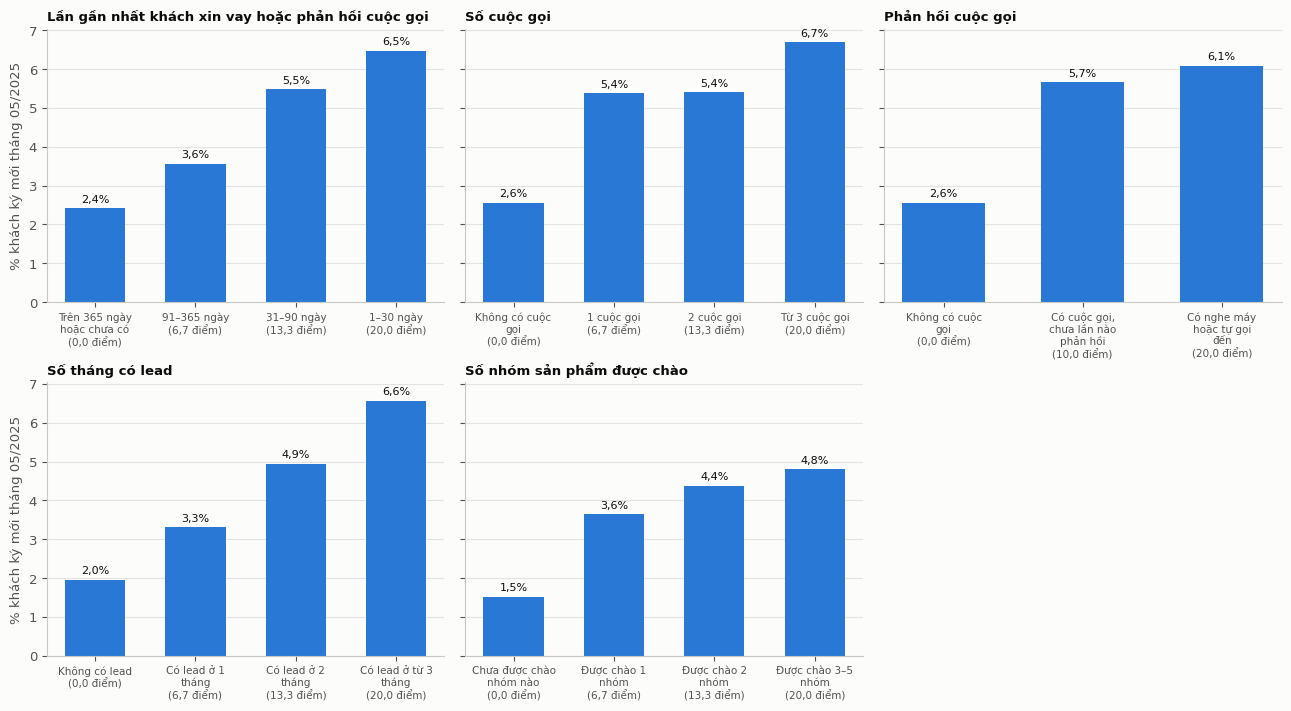

In [29]:
import textwrap
fig, axs = plt.subplots(2, 3, figsize=(13, 7.2), sharey=True)
axs = axs.ravel(); axs[5].axis('off')
for ax, f in zip(axs, KHIA_CANH):
    t = chinh.groupby(f).KY_MOI.mean() * 100
    nhan = [nhan_muc(f, int(i)).split('. ', 1)[1] for i in t.index]
    ax.bar(range(len(t)), t.values, color=MAU['xanh'], width=0.6)
    for i, v in enumerate(t.values):
        ax.text(i, v + 0.15, so(v, 1) + '%', ha='center', color=MAU['chu'], fontsize=8)
    diem = [so(diem_cua_muc(int(i), f), 1) for i in t.index]
    ax.set_xticks(range(len(t))); ax.set_xticklabels([textwrap.fill(n, 14) + f'\n({d} điểm)' for n, d in zip(nhan, diem)], fontsize=7.5)
    ax.set_title(TEN_KHIA_CANH[f], fontsize=9.5); ax.grid(axis='x', visible=False)
axs[0].set_ylabel('% khách ký mới tháng 05/2025'); axs[3].set_ylabel('% khách ký mới tháng 05/2025')
fig.tight_layout()
luu_hinh(fig, 'hinh05_ty_le_ky_moi_theo_muc')

*Hình 4. Tỷ lệ ký hợp đồng mới tháng 05/2025 theo mức của từng chỉ số, kèm số điểm của mức đó. Ở cả 5 chỉ số, mức càng cao thì tỷ lệ ký mới càng cao. Nguồn: dữ liệu của đề, nhóm tự tính.*

### 3.5. Hai điểm con: Tiếp cận và Phản hồi

Ba khía cạnh (số cuộc gọi, số tháng có lead, số nhóm sản phẩm được chào) phụ thuộc phần lớn vào việc công ty chọn liên hệ với ai. Hai khía cạnh còn lại (lần gần nhất khách xin vay hoặc phản hồi cuộc gọi, việc khách có phản hồi cuộc gọi) là hành động của chính khách. Điểm Engagement vì vậy được tách thành hai điểm con, cộng lại bằng tổng điểm:

- **Tiếp cận:** tổng điểm của số cuộc gọi, số tháng có lead, số nhóm sản phẩm được chào; tối đa 60 điểm.
- **Phản hồi:** tổng điểm của recency và phản hồi cuộc gọi; tối đa 40 điểm.

Bảng dưới đo AUC của từng điểm con và của tổng điểm trên mốc chính.

In [30]:
pd.DataFrame([('Tiếp cận (tối đa 60)', auc(chinh, chinh.TIEP_CAN)), ('Phản hồi (tối đa 40)', auc(chinh, chinh.PHAN_HOI)),
              ('Tổng điểm Engagement (tối đa 100)', auc(chinh, chinh.ENG_SCORE))], columns=['diem', 'AUC_moc_chinh']).round(4)

,diem,AUC_moc_chinh
0,Tiếp cận (tối đa 60),0.6466
1,Phản hồi (tối đa 40),0.6357
2,Tổng điểm Engagement (tối đa 100),0.6704


Tiếp cận đạt AUC 0,647, Phản hồi đạt 0,636, và gộp lại cho AUC cao hơn hẳn từng phần (0,670). Nghĩa là mức độ công ty tiếp cận khách và mức độ khách tự phản hồi là hai thông tin khác nhau, và cả hai đều có giá trị.

> **Tóm lại mục 3:** Mỗi khách nhận 0–20 điểm ở mỗi chỉ số theo bảng điểm ở mục 3.4, tổng 0–100, gồm Tiếp cận (tối đa 60) và Phản hồi (tối đa 40). Trên tháng dùng để xây, tổng điểm có AUC 0,670, cao hơn từng điểm con (0,647 và 0,636).

## 4. Chia nhóm theo mức tương tác (yêu cầu 4)

> **Câu hỏi của mục này:** Dùng điểm để chia khách thành những nhóm nào?
>
> **Cách làm:** thử nhiều bộ ngưỡng, chọn cắt ở 20, 40 và 60 điểm thành 4 nhóm: Ngủ yên, Tương tác thấp, Tương tác trung bình, Tương tác cao; rồi mô tả từng nhóm tại ngày chốt.

Điểm cần được chia thành vài nhóm để công ty có cách tiếp cận riêng cho từng nhóm. Bảng dưới thử nhiều bộ ngưỡng trên mốc chính, kể cả cách chia theo tỷ lệ khách (35%, 30%, 25%, 10% khách từ thấp đến cao), và cho % khách cùng tỷ lệ ký mới tháng 05/2025 của bốn nhóm từ thấp đến cao.

In [31]:
def chia_nhom(s, nguong):
    if nguong == 'theo tỷ lệ khách':
        return pd.qcut(s.rank(method='first'), [0, .35, .65, .90, 1], labels=False)
    return pd.cut(s, [-1, *nguong, 101], right=False, labels=False)
dong = []
for nguong in [(20, 40, 60), (15, 35, 55), (25, 45, 65), (10, 30, 50), (20, 35, 50), 'theo tỷ lệ khách']:
    t = chinh.groupby(chia_nhom(chinh.ENG_SCORE, nguong)).KY_MOI.agg(['size', 'mean'])
    dong.append({'nguong': str(nguong), 'pct_khach': ' | '.join(f'{x:.1f}' for x in t['size'] / len(chinh) * 100),
                 'pct_ky_moi': ' | '.join(f'{x:.2f}' for x in t['mean'] * 100), 'nhom_cao_gap_nhom_thap': round(t['mean'].iloc[-1] / t['mean'].iloc[0], 1)})
pd.DataFrame(dong)

,nguong,pct_khach,pct_ky_moi,nhom_cao_gap_nhom_thap
0,"(20, 40, 60)",38.6 | 31.2 | 18.6 | 11.6,1.44 | 3.36 | 5.50 | 6.63,4.6
1,"(15, 35, 55)",38.6 | 29.1 | 17.6 | 14.7,1.43 | 3.25 | 5.42 | 6.40,4.5
2,"(25, 45, 65)",50.6 | 27.7 | 13.8 | 7.8,1.73 | 4.19 | 5.99 | 6.75,3.9
3,"(10, 30, 50)",27.8 | 31.5 | 21.3 | 19.4,1.10 | 2.66 | 4.87 | 6.25,5.7
4,"(20, 35, 50)",38.6 | 29.1 | 12.9 | 19.4,1.44 | 3.25 | 5.29 | 6.25,4.4
5,theo tỷ lệ khách,35.0 | 30.0 | 25.0 | 10.0,1.43 | 2.99 | 5.30 | 6.70,4.7


- Bộ ngưỡng nào cũng cho tỷ lệ ký mới tăng đều qua 4 nhóm, và nhóm cao nhất ký mới gấp 3,9–5,7 lần nhóm thấp nhất. Kết luận "điểm càng cao càng ký nhiều" không phụ thuộc chỗ đặt ngưỡng.
- Bộ 20/40/60 chia khách thành 38,6 / 31,2 / 18,6 / 11,6%, gần giống cách chia theo tỷ lệ khách 35 / 30 / 25 / 10%, và cho tỷ lệ ký mới gần như giống nhau (1,44% → 6,63% so với 1,43% → 6,70%).
- Bộ 20/40/60 được chọn thay vì chia theo tỷ lệ khách vì hai lý do: mỗi bước 20 điểm bằng đúng điểm tối đa của một khía cạnh nên dễ giải thích; và ngưỡng cố định giúp nhóm của một khách chỉ phụ thuộc hành vi của chính khách đó, không thay đổi khi các khách khác thay đổi.

Bốn nhóm: Ngủ yên dưới 20 điểm, Tương tác thấp từ 20 đến dưới 40, Tương tác trung bình từ 40 đến dưới 60, Tương tác cao từ 60 điểm. Bảng dưới mô tả từng nhóm tại ngày chốt.

In [32]:
NGUONG = (20, 40, 60)
TEN_NHOM = ['4. Ngủ yên', '3. Tương tác thấp', '2. Tương tác trung bình', '1. Tương tác cao']
def gan_nhom(d):
    return pd.cut(d.ENG_SCORE, [-1, *NGUONG, 101], right=False, labels=TEN_NHOM).astype(str)
chinh['ENG_GROUP'] = gan_nhom(chinh)
cham_diem(chot)
chot['ENG_GROUP'] = gan_nhom(chot)
ho_so = chot.groupby('ENG_GROUP').agg(so_khach=('SKP_CLIENT', 'size'), diem_tb=('ENG_SCORE', 'mean'), tiep_can_tb=('TIEP_CAN', 'mean'),
    phan_hoi_tb=('PHAN_HOI', 'mean'), pct_xin_vay_trong_90_ngay=('NGAY_XIN_VAY', lambda s: (s <= 90).mean() * 100),
    pct_co_cuoc_goi=('SO_CUOC_GOI', lambda s: (s > 0).mean() * 100), so_cuoc_goi_tb=('SO_CUOC_GOI', 'mean'),
    pct_phan_hoi_goi=('SO_CUOC_PHAN_HOI', lambda s: (s > 0).mean() * 100),
    so_thang_co_lead_tb=('SO_THANG_CO_LEAD', 'mean'), so_nhom_duoc_chao_tb=('SO_SP_DUOC_CHAO', 'mean'),
    so_nhom_da_ky_tb=('SO_SP_DA_KY', 'mean'), pct_dang_tra_gop=('SO_HD_DANG_TRA', lambda s: (s > 0).mean() * 100),
    pct_dung_app=('PHIEN_APP_TUAN', lambda s: (s > 0).mean() * 100))
ho_so.insert(1, 'pct_khach', ho_so.so_khach / len(chot) * 100)
print('Hồ sơ từng nhóm tại ngày chốt')
ho_so.round(1)

Hồ sơ từng nhóm tại ngày chốt


,so_khach,pct_khach,diem_tb,tiep_can_tb,phan_hoi_tb,pct_xin_vay_trong_90_ngay,pct_co_cuoc_goi,so_cuoc_goi_tb,pct_phan_hoi_goi,so_thang_co_lead_tb,so_nhom_duoc_chao_tb,so_nhom_da_ky_tb,pct_dang_tra_gop,pct_dung_app
ENG_GROUP,,,,,,,,,,,,,,
1. Tương tác cao,118123,11.8,72.3,43.3,29.0,38.7,96.9,2.5,52.2,2.2,2.5,2.0,78.5,9.9
2. Tương tác trung bình,188515,18.8,46.9,34.0,12.9,25.8,55.8,1.1,4.4,2.0,2.3,1.8,74.0,9.6
3. Tương tác thấp,311060,31.1,26.6,20.8,5.8,15.4,12.0,0.2,0.0,1.1,1.8,1.4,62.8,8.5
4. Ngủ yên,382830,38.3,4.7,3.1,1.6,4.2,0.1,0.0,0.0,0.2,0.2,0.8,24.2,3.7


- **Tương tác cao (118.123 khách, 11,8%, điểm trung bình 72,3).** 38,7% xin vay trong 90 ngày gần nhất và 52,2% phản hồi cuộc gọi trong 90 ngày. 96,9% có cuộc gọi, trung bình 2,5 cuộc. Có lead ở 2,2 tháng, được chào 2,5 nhóm sản phẩm. 78,5% đang có khoản trả góp, 9,9% có dùng app.
- **Tương tác trung bình (188.515 khách, 18,8%, điểm trung bình 46,9).** 55,8% có cuộc gọi, trung bình 1,1 cuộc, nhưng chỉ 4,4% phản hồi và 25,8% xin vay trong 90 ngày. Điểm Tiếp cận 34,0 trên 60, Phản hồi chỉ 12,9 trên 40: được liên hệ khá nhiều nhưng ít phản hồi.
- **Tương tác thấp (311.060 khách, 31,1%, điểm trung bình 26,6).** Chỉ 12,0% có cuộc gọi; điểm chủ yếu đến từ lead (1,1 tháng) và sản phẩm được chào (1,8 nhóm). 62,8% vẫn đang có khoản trả góp: họ vẫn là khách của công ty nhưng hầu như không được gọi.
- **Ngủ yên (382.830 khách, 38,3%, điểm trung bình 4,7).** Gần như không có cuộc gọi (0,1%) và không có lead (trung bình 0,2 tháng), chỉ 4,2% xin vay trong 90 ngày. 24,2% đang trả góp, 3,7% có dùng app.

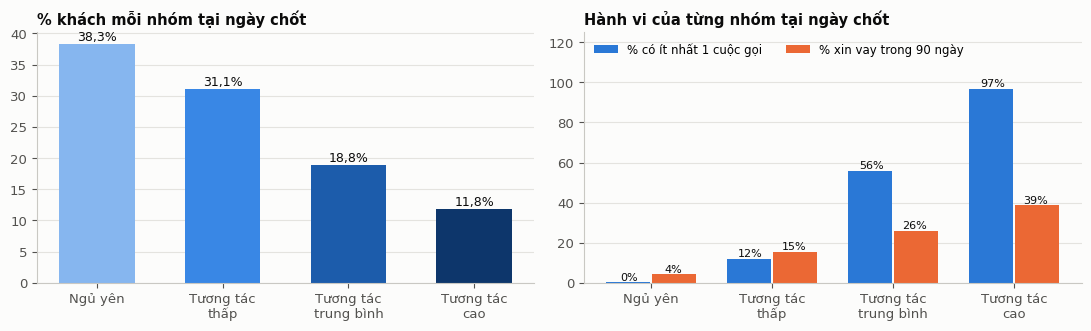

In [33]:
thu_tu = ['4. Ngủ yên', '3. Tương tác thấp', '2. Tương tác trung bình', '1. Tương tác cao']
ten_gon = [n.split('. ', 1)[1].replace('Tương tác ', 'Tương tác\n') for n in thu_tu]
ty_trong = chot.ENG_GROUP.value_counts(normalize=True).reindex(thu_tu) * 100
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.4))
a1.bar(ten_gon, ty_trong.values, color=[MAU_NHOM[n] for n in thu_tu], width=0.6)
for i, v in enumerate(ty_trong.values):
    a1.text(i, v + 0.6, so(v) + '%', ha='center', color=MAU['chu'], fontsize=9)
a1.set_title('% khách mỗi nhóm tại ngày chốt'); a1.grid(axis='x', visible=False)
h = ho_so.reindex(thu_tu)
x = np.arange(len(thu_tu)); w = 0.36
a2.bar(x - w / 2 - 0.01, h.pct_co_cuoc_goi, w, color=MAU['xanh'], label='% có ít nhất 1 cuộc gọi')
a2.bar(x + w / 2 + 0.01, h.pct_xin_vay_trong_90_ngay, w, color=MAU['cam'], label='% xin vay trong 90 ngày')
for i in range(len(x)):
    a2.text(x[i] - w / 2, h.pct_co_cuoc_goi.iloc[i] + 1, so(h.pct_co_cuoc_goi.iloc[i], 0) + '%', ha='center', fontsize=8, color=MAU['chu'])
    a2.text(x[i] + w / 2, h.pct_xin_vay_trong_90_ngay.iloc[i] + 1, so(h.pct_xin_vay_trong_90_ngay.iloc[i], 0) + '%', ha='center', fontsize=8, color=MAU['chu'])
a2.set_xticks(x); a2.set_xticklabels(ten_gon); a2.set_ylim(0, 125); a2.grid(axis='x', visible=False)
a2.set_title('Hành vi của từng nhóm tại ngày chốt'); a2.legend(loc='upper left', ncol=2, fontsize=8.5)
fig.tight_layout()
luu_hinh(fig, 'hinh06_bon_nhom')

*Hình 5. Tỷ trọng và hành vi của bốn nhóm khách tại ngày chốt. Nhóm Ngủ yên gần như không được gọi và hiếm khi xin vay; nhóm Tương tác cao hầu hết đã được gọi và khoảng 39% vừa xin vay trong 90 ngày. Nguồn: dữ liệu của đề, nhóm tự tính.*

> **Tóm lại mục 4:** Tại ngày chốt: Ngủ yên 38,3% khách, Tương tác thấp 31,1%, Tương tác trung bình 18,8%, Tương tác cao 11,8%. Mọi bộ ngưỡng đã thử đều cho tỷ lệ ký mới tăng đều qua 4 nhóm, nên kết luận không phụ thuộc chỗ cắt.

## 5. Yếu tố làm tăng hoặc giảm tương tác (yêu cầu 5)

> **Câu hỏi của mục này:** Khách tương tác nhiều hay ít đi kèm với những đặc điểm nào?
>
> **Cách làm:** so điểm giữa các nhóm khách chia theo các yếu tố nằm ngoài điểm (nguồn lead, sản phẩm đang vay, số sản phẩm đã ký, kênh xin vay, mức dùng app, tuổi), rồi đặt Tiếp cận cạnh Phản hồi để tìm những nhóm khách cần cách tiếp cận khác nhau.

Các khía cạnh trong điểm là thước đo của tương tác, nên không thể dùng chúng để giải thích vì sao khách tương tác nhiều hay ít. Mục này xét các yếu tố nằm ngoài điểm: nguồn của lead gần nhất, sản phẩm của hợp đồng ký gần nhất, số nhóm sản phẩm đã ký, kênh của lần xin vay gần nhất, mức dùng app năm 2025, và tuổi. Mỗi bảng cho điểm Engagement trung bình, hai điểm con và tỷ lệ khách thuộc nhóm Tương tác cao tại ngày chốt. Các bảng chỉ mô tả sự khác nhau giữa các nhóm khách, không cho biết nguyên nhân.

In [34]:
def theo(cot):
    t = chot.groupby(cot, dropna=False, observed=True).agg(so_khach=('SKP_CLIENT', 'size'), diem_tb=('ENG_SCORE', 'mean'),
            tiep_can_tb=('TIEP_CAN', 'mean'), phan_hoi_tb=('PHAN_HOI', 'mean'),
            pct_tuong_tac_cao=('ENG_GROUP', lambda s: (s == '1. Tương tác cao').mean() * 100))
    return t.round(1).sort_values('so_khach', ascending=False)
print('Theo nguồn của lead gần nhất')
display(theo('NGUON_LEAD_GAN_NHAT'))
print('Theo sản phẩm của hợp đồng ký gần nhất')
display(theo('SAN_PHAM_GAN_NHAT'))
print('Theo số nhóm sản phẩm đã ký')
display(theo(chot.SO_SP_DA_KY.clip(upper=3).rename('SO_NHOM_DA_KY')).sort_index())
print('Theo kênh của lần xin vay gần nhất')
display(theo('KENH_XIN_VAY_GAN_NHAT'))
print('Theo mức dùng app năm 2025')
display(theo(pd.cut(chot.PHIEN_APP_TUAN.fillna(0), [-1, 0, 0.999, 10**6], labels=['Không dùng', 'Dưới 1 lần/tuần', 'Từ 1 lần/tuần']).rename('DUNG_APP')))
print('Theo nhóm tuổi')
theo(pd.cut(chot.TUOI, [0, 25, 35, 45, 200], right=False, labels=['Dưới 25', '25–34', '35–44', 'Từ 45']).rename('NHOM_TUOI'))

Theo nguồn của lead gần nhất


,so_khach,diem_tb,tiep_can_tb,phan_hoi_tb,pct_tuong_tac_cao
NGUON_LEAD_GAN_NHAT,,,,,
NaN,355184,8.0,2.5,5.5,1.5
RA,346176,35.0,27.5,7.5,14.1
SA,249638,41.8,30.0,11.8,21.2
TLS,19554,46.5,28.9,17.5,28.4
GMA,15374,40.2,24.4,15.9,20.8
SOB,10759,35.7,22.7,13.0,16.1
LANDING PAGE,3523,37.4,21.7,15.8,15.1
RTDM,320,38.9,24.4,14.4,19.1


Theo sản phẩm của hợp đồng ký gần nhất


,so_khach,diem_tb,tiep_can_tb,phan_hoi_tb,pct_tuong_tac_cao
SAN_PHAM_GAN_NHAT,,,,,
CD,502684,29.7,22.7,7.0,11.1
NaN,182505,4.7,1.8,2.9,0.5
BNPL,139905,30.9,21.7,9.2,12.5
CL,107557,44.2,26.2,18.1,27.9
CC,31582,46.4,28.8,17.6,29.3
TW,30193,30.9,18.6,12.3,13.5
CW,6102,25.4,11.8,13.6,7.2


Theo số nhóm sản phẩm đã ký


...

,so_khach,diem_tb,tiep_can_tb,phan_hoi_tb,pct_tuong_tac_cao
KENH_XIN_VAY_GAN_NHAT,,,,,
NaN,527442,19.2,16.4,2.8,4.9
APP SCORING,135068,35.6,19.9,15.7,17.9
SA SCORING,118819,40.7,26.2,14.4,23.8
TLS SCORING,83568,43.5,28.4,15.1,26.6
WEB SCORING,72364,27.6,15.8,11.8,12.9
Partner Site SCORING,48167,34.2,19.4,14.8,14.5
SOB_CD_QR,12362,26.0,16.9,9.1,5.2
SOB_TW_LINK,2028,31.1,19.2,12.0,11.9
SOB_TW_QR,494,32.3,22.1,10.2,12.1


Theo mức dùng app năm 2025


,so_khach,diem_tb,tiep_can_tb,phan_hoi_tb,pct_tuong_tac_cao
DUNG_APP,,,,,
Không dùng,930051,26.8,18.7,8.1,11.4
Dưới 1 lần/tuần,50337,33.3,24.7,8.6,14.1
Từ 1 lần/tuần,20140,41.6,26.7,14.9,23.0


Theo nhóm tuổi


,so_khach,diem_tb,tiep_can_tb,phan_hoi_tb,pct_tuong_tac_cao
NHOM_TUOI,,,,,
35–44,313896,28.9,20.9,8.0,12.8
25–34,308363,29.9,20.5,9.5,13.6
Từ 45,217157,25.8,18.9,6.8,10.8
Dưới 25,161080,22.1,13.7,8.4,7.7
NaN,32,7.4,5.4,2.0,0.0


- **Nguồn lead gần nhất:** khách có lead gần nhất từ nguồn TLS (nhiều khả năng là telesales) có điểm cao nhất (46,5; 28,4% thuộc nhóm Tương tác cao) và Phản hồi cao nhất (17,5). RA có nhiều khách nhất (346 nghìn) và điểm Tiếp cận gần bằng SA (27,5 so với 30,0), nhưng Phản hồi chỉ 7,5 so với 11,8: khách từ nguồn RA được liên hệ nhiều nhưng ít phản hồi. 355 nghìn khách chưa có lead nào có điểm trung bình 8,0.
- **Sản phẩm của hợp đồng ký gần nhất:** khách có hợp đồng gần nhất là thẻ tín dụng (CC) hoặc vay tiền mặt (CL) có điểm 46,4 và 44,2, khoảng 28–29% thuộc nhóm Tương tác cao, và Phản hồi khoảng 18. Khách vay mua hàng (CD 29,7; BNPL 30,9; TW 30,9) có Phản hồi chỉ 7,0–12,3. CD là sản phẩm gần nhất của 503 nghìn khách, nhưng chỉ 11,1% trong số đó thuộc nhóm Tương tác cao.
- **Số nhóm sản phẩm đã ký:** điểm tăng từ 4,7 ở khách chưa ký lên 46,5 ở khách ký từ 3 nhóm (29,8% thuộc nhóm Tương tác cao), tăng ở cả Tiếp cận lẫn Phản hồi. Công ty liên hệ nhiều hơn với khách đã vay nhiều, và những khách này cũng tự phản hồi nhiều hơn.
- **Kênh của lần xin vay gần nhất:** 527 nghìn khách không có lần xin vay nào trong bảng PAST_BEHAVIOR có điểm 19,2 và Phản hồi chỉ 2,8. Trong 5 kênh có từ 40 nghìn khách: khách xin vay gần nhất qua TLS (43,5 điểm) và SA (40,7) có điểm cao nhất, chủ yếu nhờ Tiếp cận (28,4 và 26,2); khách xin vay qua app có Phản hồi cao nhất (15,7) nhưng Tiếp cận chỉ 19,9, tức tự tìm đến nhưng ít được công ty liên hệ; khách qua web có điểm thấp nhất (27,6).
- **Mức dùng app năm 2025:** khách dùng app từ 1 lần mỗi tuần có điểm 41,6 và Phản hồi 14,9, so với 26,8 và 8,1 ở khách không dùng app. Số phiên app là trung bình của cả năm 2025, gồm cả các tháng sau ngày chốt, nên chỉ dùng để mô tả ở đây, không dùng trong điểm (mục 2).
- **Tuổi:** chênh lệch nhỏ. Khách dưới 25 tuổi có điểm thấp nhất (22,1), chủ yếu vì được tiếp cận ít (Tiếp cận 13,7); khách 25–34 tuổi cao nhất (29,9). Tuổi không được dùng trong điểm.

Các chênh lệch trên là tương quan. Ví dụ, khách vay tiền mặt tương tác nhiều hơn không có nghĩa là bán khoản vay tiền mặt sẽ làm khách tương tác nhiều hơn.

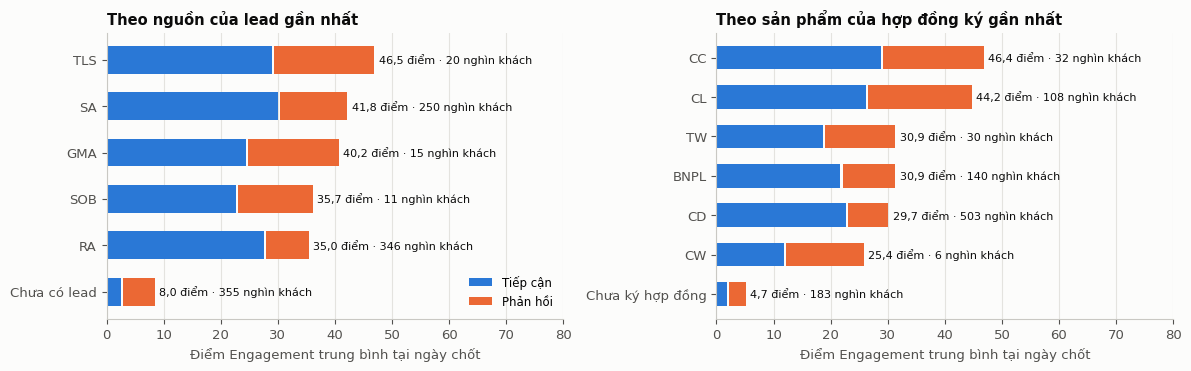

In [35]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, (cot, tieu_de, thieu) in zip(axs, [('NGUON_LEAD_GAN_NHAT', 'Theo nguồn của lead gần nhất', 'Chưa có lead'),
                                           ('SAN_PHAM_GAN_NHAT', 'Theo sản phẩm của hợp đồng ký gần nhất', 'Chưa ký hợp đồng')]):
    t = theo(cot)
    t = t[t.so_khach >= 5000].copy()
    t.index = [thieu if pd.isna(i) else str(i) for i in t.index]
    t = t.sort_values('diem_tb')
    y = np.arange(len(t))
    ax.barh(y, t.tiep_can_tb, color=MAU['xanh'], height=0.6, label='Tiếp cận')
    ax.barh(y, t.phan_hoi_tb, left=t.tiep_can_tb + 0.4, color=MAU['cam'], height=0.6, label='Phản hồi')
    for i, (d, n) in enumerate(zip(t.diem_tb, t.so_khach)):
        ax.text(d + 1.2, i, f'{so(d)} điểm · {so(n / 1000, 0)} nghìn khách', va='center', fontsize=8, color=MAU['chu'])
    ax.set_yticks(y); ax.set_yticklabels(t.index); ax.set_xlim(0, 80); ax.grid(axis='y', visible=False)
    ax.set_title(tieu_de); ax.set_xlabel('Điểm Engagement trung bình tại ngày chốt')
axs[0].legend(loc='lower right', fontsize=8.5)
fig.tight_layout()
luu_hinh(fig, 'hinh07_diem_theo_nguon_lead_va_san_pham')

*Hình 6. Điểm Engagement trung bình tại ngày chốt, tách thành Tiếp cận và Phản hồi, theo nguồn của lead gần nhất và theo sản phẩm của hợp đồng ký gần nhất (chỉ các nhóm có từ 5 nghìn khách). Nguồn: dữ liệu của đề, nhóm tự tính.*

### 5.1. Tiếp cận và Phản hồi

Hai điểm con cho phép tách khách theo hai câu hỏi: công ty đã liên hệ khách nhiều chưa, và khách có tự chủ động không. Mỗi điểm con được chia làm ba bậc bằng nhau theo thang điểm của nó: Tiếp cận dưới 20, từ 20 đến dưới 40, từ 40 điểm; Phản hồi dưới 13,3, từ 13,3 đến dưới 26,7, từ 26,7 điểm. Bảng thứ nhất là số khách ở ngày chốt; bảng thứ hai là tỷ lệ ký mới tháng 05/2025 trên mốc chính.

In [36]:
def bac_tiep_can(d):
    return pd.cut(d.TIEP_CAN, [-1, 20, 40, 61], right=False, labels=['Tiếp cận thấp', 'Tiếp cận vừa', 'Tiếp cận cao'])
def bac_phan_hoi(d):
    return pd.cut(d.PHAN_HOI, [-1, 13.3, 26.7, 41], right=False, labels=['Phản hồi thấp', 'Phản hồi vừa', 'Phản hồi cao'])
print('Số khách tại ngày chốt')
display(pd.crosstab(bac_phan_hoi(chot), bac_tiep_can(chot)))
print('% khách có dùng app năm 2025, ngày chốt')
display((chot.groupby([bac_phan_hoi(chot), bac_tiep_can(chot)], observed=True).PHIEN_APP_TUAN.apply(lambda s: (s > 0).mean()).unstack() * 100).round(1))
print('Tỷ lệ ký mới tháng 05/2025 (%), mốc chính')
(chinh.groupby([bac_phan_hoi(chinh), bac_tiep_can(chinh)], observed=True).KY_MOI.mean().unstack() * 100).round(2)

Số khách tại ngày chốt


TIEP_CAN,Tiếp cận thấp,Tiếp cận vừa,Tiếp cận cao
PHAN_HOI,,,
Phản hồi thấp,417741,227527,76451
Phản hồi vừa,63315,72024,50748
Phản hồi cao,7216,39344,46162


% khách có dùng app năm 2025, ngày chốt


TIEP_CAN,Tiếp cận thấp,Tiếp cận vừa,Tiếp cận cao
PHAN_HOI,,,
Phản hồi thấp,4.1,9.0,9.8
Phản hồi vừa,7.0,9.3,10.6
Phản hồi cao,7.8,9.1,10.0


Tỷ lệ ký mới tháng 05/2025 (%), mốc chính


TIEP_CAN,Tiếp cận thấp,Tiếp cận vừa,Tiếp cận cao
PHAN_HOI,,,
Phản hồi thấp,1.54,3.38,5.54
Phản hồi vừa,4.12,5.47,6.26
Phản hồi cao,6.06,6.09,7.15


- **Số khách:** 417.741 khách (41,8%) thấp ở cả hai mặt. 76.451 khách được tiếp cận cao nhưng phản hồi thấp. 7.216 khách phản hồi cao nhưng ít được tiếp cận, và thêm 63.315 khách phản hồi vừa nhưng ít được tiếp cận.
- **Tỷ lệ ký mới:** ở mỗi bậc Tiếp cận, khách phản hồi cao hơn ký mới nhiều hơn. Khách phản hồi cao nhưng tiếp cận thấp ký mới 6,06%, cao hơn khách tiếp cận cao nhưng phản hồi thấp (5,54%).
- **Dùng app:** khách thấp ở cả hai mặt ít dùng app nhất (4,1%); các ô còn lại 7,0–10,6%.

Bốn nhóm khách cần cách tiếp cận khác nhau:

| Nhóm | Ô trong bảng | Số khách tại ngày chốt | Tỷ lệ ký mới tháng 05/2025 | Cách tiếp cận gợi ý |
|---|---|---|---|---|
| Gắn kết hai chiều | Tiếp cận cao, Phản hồi cao | 46.162 | 7,15% | giữ nhịp liên hệ hiện tại, chào thêm sản phẩm |
| Chủ động nhưng ít được liên hệ | Tiếp cận thấp, Phản hồi vừa hoặc cao | 70.531 | 4,12–6,06% | đưa lên đầu danh sách gọi và tạo lead |
| Được liên hệ nhiều nhưng ít phản hồi | Tiếp cận cao, Phản hồi thấp | 76.451 | 5,54% | không tăng thêm số cuộc gọi; đổi nội dung chào hoặc kênh liên hệ |
| Ít tương tác cả hai mặt | Tiếp cận thấp, Phản hồi thấp | 417.741 | 1,54% | dùng kênh chi phí thấp như tin nhắn hoặc app, không gọi đại trà |

Cách tiếp cận gợi ý dựa trên việc nhóm nào đang ký nhiều hay ít. Bảng không cho biết liên hệ thêm hay đổi kênh có làm khách ký nhiều hơn hay không (mục 3.1).

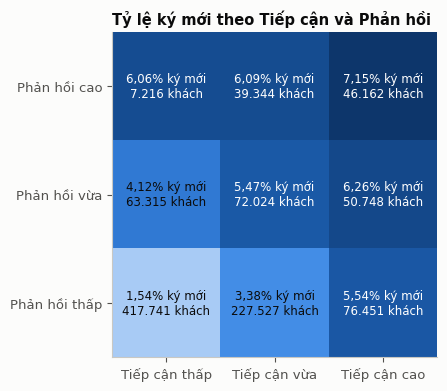

In [37]:
ty_le = (chinh.groupby([bac_phan_hoi(chinh), bac_tiep_can(chinh)], observed=True).KY_MOI.mean().unstack() * 100)
so_khach = pd.crosstab(bac_phan_hoi(chot), bac_tiep_can(chot)).reindex(index=ty_le.index, columns=ty_le.columns)
ty_le, so_khach = ty_le.iloc[::-1], so_khach.iloc[::-1]
fig, ax = plt.subplots(figsize=(7.5, 4))
im = ax.imshow(ty_le.values, cmap=CMAP_XANH, vmin=0, vmax=ty_le.values.max())
for i in range(ty_le.shape[0]):
    for j in range(ty_le.shape[1]):
        v = ty_le.values[i, j]
        ax.text(j, i, f'{so(v, 2)}% ký mới\n{so(so_khach.values[i, j], 0)} khách', ha='center', va='center', fontsize=8.5,
                color='white' if v > ty_le.values.max() * 0.6 else MAU['chu'])
ax.set_xticks(range(3)); ax.set_xticklabels(ty_le.columns); ax.set_yticks(range(3)); ax.set_yticklabels(ty_le.index)
ax.grid(False); ax.set_title('Tỷ lệ ký mới theo Tiếp cận và Phản hồi')
fig.tight_layout()
luu_hinh(fig, 'hinh08_tiep_can_va_phan_hoi')

*Hình 7. Tỷ lệ ký hợp đồng mới tháng 05/2025 theo bậc Tiếp cận và bậc Phản hồi, kèm số khách mỗi ô tại ngày chốt. Ở cùng một bậc Tiếp cận, khách phản hồi cao luôn ký mới nhiều hơn. Nguồn: dữ liệu của đề, nhóm tự tính.*

> **Tóm lại mục 5:** Khách có lead gần nhất từ nguồn TLS, khách vay thẻ tín dụng hoặc tiền mặt, khách đã ký nhiều nhóm sản phẩm và khách dùng app thường xuyên có điểm cao hơn hẳn; khách từ nguồn RA được liên hệ nhiều nhưng ít phản hồi, còn khách xin vay qua app phản hồi nhiều nhưng ít được liên hệ. Theo Tiếp cận và Phản hồi, có khoảng 71 nghìn khách chủ động nhưng ít được liên hệ và khoảng 76 nghìn khách được liên hệ nhiều nhưng ít phản hồi. Đây là tương quan, không phải nguyên nhân.

## 6. Kiểm chứng điểm Engagement với kết quả kinh doanh (yêu cầu 6)

> **Câu hỏi của mục này:** Điểm có thật sự cho biết khách nào sẽ quay lại ký hợp đồng không?
>
> **Cách làm:** xây lại điểm chỉ bằng dữ liệu đến hết tháng 04/2025, rồi xem điểm đó có đoán đúng ai ký hợp đồng mới trong tháng 05/2025 không. Tháng 05 không được dùng khi xây lại, nên không có rò rỉ dữ liệu.

Ngưỡng của điểm ở mục 3 được chọn trên mốc 01/05/2025, với dữ liệu chỉ số trước 01/05/2025 và kết quả tháng 05/2025. Không còn tháng nào sau 05/2025 để kiểm tra bản điểm này. Vì vậy mục này kiểm tra **quy tắc xây điểm**: làm lại toàn bộ cách xây ở mục 3 bằng dữ liệu cũ hơn một tháng, rồi đo bản đó trên tháng 05/2025.

| | Chỉ số tính từ dữ liệu | Kết quả |
|---|---|---|
| **Xây bản kiểm tra** | trước 01/04/2025 | khách nào ký hợp đồng mới trong tháng 04/2025 |
| **Kiểm tra** | trước 01/05/2025 | khách nào ký hợp đồng mới trong tháng 05/2025 |

Bản kiểm tra chỉ dùng dữ liệu đến hết 30/04/2025. Tháng 05/2025 nằm hoàn toàn sau mọi dữ liệu đã dùng để xây, nên không có thông tin nào của tháng kiểm tra lọt vào lúc xây, giống tình huống thật: xây trên quá khứ rồi dùng cho tháng tiếp theo. Nếu bản kiểm tra dự báo tốt tháng 05, quy tắc xây là đáng tin, và bản dùng thật (xây cùng quy tắc trên dữ liệu mới hơn) cũng đáng tin.

Ngưỡng chia nhóm 20/40/60 và cách chia điểm đều giữ nguyên, vì chúng được chọn theo thang điểm, không theo kết quả ký mới (mục 3.4 và mục 4).

### 6.1. Xây bản kiểm tra

Ô code dưới chạy lại đúng quy tắc chọn ngưỡng ở mục 3.3 trên mốc 01/04/2025, rồi so ngưỡng chọn được với ngưỡng của bản dùng thật.

In [38]:
import copy
def dung_cau_hinh(cau_hinh):
    # Đổi bộ ngưỡng đang dùng để chấm điểm (CAU_HINH) sang bộ ngưỡng khác
    CAU_HINH.clear(); CAU_HINH.update(copy.deepcopy(cau_hinh))

CAU_HINH_DUNG_THAT = copy.deepcopy(CAU_HINH)            # ngưỡng của bản dùng thật, chọn ở mục 3.3
kiem_tra = bang_mau('KQ_KIEM_TRA', 'CS90_KIEM_TRA')   # chỉ số trước 01/04/2025, kết quả tháng 04/2025
chinh_05 = chinh
chinh = kiem_tra    # tim_nguong chọn ngưỡng trên dữ liệu trong biến chinh
for ten, k, n, g in [('RECENCY', k_recency, n_recency, False), ('FREQUENCY', k_frequency, n_frequency, False),
                     ('TUONG_TAC', k_tuong_tac, n_tuong_tac, True), ('LEAD', k_lead, n_lead, False),
                     ('SAN_PHAM', k_san_pham, n_san_pham, False)]:
    tim_nguong(ten, k, n, giu_muc_0=g, in_ra=False)
CAU_HINH_KIEM_TRA = copy.deepcopy(CAU_HINH)
chinh = chinh_05

def cac_muc(cau_hinh, ten):
    return ' | '.join(cau_hinh[ten]['nhan'](a, b) for a, b in cau_hinh[ten]['cuts'])
pd.DataFrame([{'khia_canh': TEN_KHIA_CANH[f], 'ban_kiem_tra (xây trên mốc 01/04)': cac_muc(CAU_HINH_KIEM_TRA, f),
               'ban_dung_that (xây trên mốc 01/05)': cac_muc(CAU_HINH_DUNG_THAT, f),
               'giong_nhau': CAU_HINH_KIEM_TRA[f]['cuts'] == CAU_HINH_DUNG_THAT[f]['cuts']} for f in KHIA_CANH])

,khia_canh,ban_kiem_tra (xây trên mốc 01/04),ban_dung_that (xây trên mốc 01/05),giong_nhau
0,Lần gần nhất khách xin vay hoặc phản hồi cuộc gọi,"361–365 ngày, hoặc lâu hơn, hoặc chưa có | 61–360 ngày | 31–60 ngày | 1–30 ngày",Trên 365 ngày hoặc chưa có | 91–365 ngày | 31–90 ngày | 1–30 ngày,False
1,Số cuộc gọi,Không có cuộc gọi | 1–2 cuộc gọi | Từ 3 cuộc gọi,Không có cuộc gọi | 1 cuộc gọi | 2 cuộc gọi | Từ 3 cuộc gọi,False
2,Phản hồi cuộc gọi,"Không có cuộc gọi | Có cuộc gọi, chưa lần nào phản hồi | Có nghe máy hoặc tự gọi đến","Không có cuộc gọi | Có cuộc gọi, chưa lần nào phản hồi | Có nghe máy hoặc tự gọi đến",True
3,Số tháng có lead,Không có lead | Có lead ở 1 tháng | Có lead ở 2 tháng | Có lead ở từ 3 tháng,Không có lead | Có lead ở 1 tháng | Có lead ở 2 tháng | Có lead ở từ 3 tháng,True
4,Số nhóm sản phẩm được chào,Chưa được chào nhóm nào | Được chào 1 nhóm | Được chào 2 nhóm | Được chào 3–5 nhóm,Chưa được chào nhóm nào | Được chào 1 nhóm | Được chào 2 nhóm | Được chào 3–5 nhóm,True


- Ba khía cạnh (phản hồi cuộc gọi, số tháng có lead, số nhóm sản phẩm được chào) cho ra đúng cùng các mức ở hai mốc.
- Số cuộc gọi: ở mốc 01/04 không có cách chia 4 mức nào thỏa điều kiện, nên bản kiểm tra dùng 3 mức (không có cuộc gọi / 1–2 / từ 3 cuộc gọi), trong khi bản dùng thật tách riêng 1 cuộc và 2 cuộc. Hai mức này có tỷ lệ ký mới gần như bằng nhau ở mốc chính (5,38% và 5,41%, mục 3.3), nên gộp hay tách chúng khác nhau rất ít.
- Recency: ngưỡng giữa thành 60 ngày thay cho 90 ngày, và ngưỡng thấp nhất là 360 ngày thay cho 365 ngày. Ở mốc 01/04, 59,0% khách vừa nộp hồ sơ trong 90 ngày (mục 3.2), nên cách chia tốt nhất ở mốc này hơi khác. Đây cũng là lý do bản dùng thật được xây trên mốc 01/05, mốc giống ngày chốt hơn.
- Cùng một quy tắc, chạy trên hai tháng dữ liệu khác nhau, cho ra các mức gần giống nhau. Các ngưỡng không phải là kết quả ngẫu nhiên của một tháng dữ liệu.

### 6.2. Bản kiểm tra trên tháng 05/2025

Bản kiểm tra chấm điểm mọi khách bằng chỉ số trước 01/05/2025, rồi so với việc ký hợp đồng mới trong tháng 05/2025. Bảng thứ nhất cho, theo nhóm: tỷ lệ ký mới, tỷ lệ nộp hồ sơ mới, và giá trị hợp đồng mới ký trong tháng 05/2025 (cột `AMT_CREDIT_ADJ` của bảng CONTRACT: số tiền vay, riêng BNPL là số tiền hóa đơn), tính trung bình mỗi khách (triệu đồng) và theo phần trăm tổng giá trị. Bảng thứ hai và Hình 8 cho tỷ lệ ký mới theo khoảng 10 điểm.

AUC của bản kiểm tra trên tháng 05/2025: 0.67


,so_khach,pct_ky_moi,pct_nop_moi,tien_ky_moi_tb_trieu,pct_khach,pct_tong_tien_ky_moi
ENG_GROUP,,,,,,
1. Tương tác cao,120752,6.63,8.91,1.37,12.07,30.13
2. Tương tác trung bình,191223,5.39,7.29,0.93,19.11,32.33
3. Tương tác thấp,302711,3.34,4.84,0.48,30.26,26.39
4. Ngủ yên,385842,1.43,2.87,0.16,38.56,11.15


,so_khach,pct_ky_moi
ENG_SCORE,,
"[0, 10)",285778,1.13
"[10, 20)",100064,2.28
"[20, 30)",213005,2.93
"[30, 40)",89706,4.34
"[40, 50)",132239,5.20
"[50, 60)",58984,5.82
"[60, 70)",57986,6.28
"[70, 101)",62766,6.94


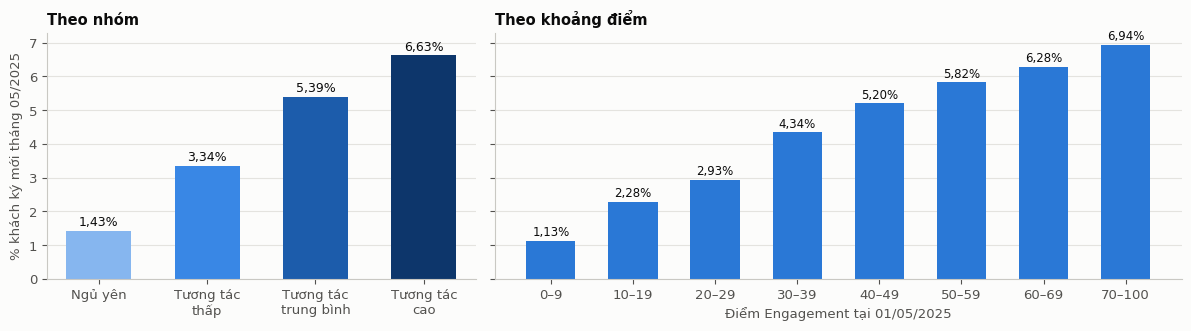

In [39]:
dung_cau_hinh(CAU_HINH_KIEM_TRA)
thang05 = chinh.copy()          # chỉ số trước 01/05/2025, kết quả tháng 05/2025
cham_diem(thang05)
thang05['ENG_GROUP'] = gan_nhom(thang05)
def bang_nhom(d):
    t = d.groupby('ENG_GROUP').agg(so_khach=('KY_MOI', 'size'), pct_ky_moi=('KY_MOI', 'mean'), pct_nop_moi=('NOP_MOI', 'mean'),
                                   tien_ky_moi_tb_trieu=('TIEN_KY_MOI', 'mean'), tong_tien_ky_moi=('TIEN_KY_MOI', 'sum'))
    t['pct_khach'] = t.so_khach / len(d) * 100
    t[['pct_ky_moi', 'pct_nop_moi']] *= 100
    t['tien_ky_moi_tb_trieu'] /= 1e6
    t['pct_tong_tien_ky_moi'] = t.pop('tong_tien_ky_moi') / d.TIEN_KY_MOI.sum() * 100
    return t.round(2)
print('AUC của bản kiểm tra trên tháng 05/2025:', round(auc(thang05, thang05.ENG_SCORE), 4))
display(bang_nhom(thang05))
KHOANG_10 = [0, 10, 20, 30, 40, 50, 60, 70, 101]
t = thang05.groupby(pd.cut(thang05.ENG_SCORE, KHOANG_10, right=False), observed=True).agg(so_khach=('KY_MOI', 'size'), pct_ky_moi=('KY_MOI', 'mean'))
t['pct_ky_moi'] = (t.pct_ky_moi * 100).round(2)
display(t)
thu_tu = ['4. Ngủ yên', '3. Tương tác thấp', '2. Tương tác trung bình', '1. Tương tác cao']
g = thang05.groupby('ENG_GROUP').KY_MOI.mean().reindex(thu_tu) * 100
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.4), sharey=True, gridspec_kw={'width_ratios': [1, 1.6]})
a1.bar([n.split('. ', 1)[1].replace('Tương tác ', 'Tương tác\n') for n in thu_tu], g.values, color=[MAU_NHOM[n] for n in thu_tu], width=0.6)
for i, v in enumerate(g.values):
    a1.text(i, v + 0.15, so(v, 2) + '%', ha='center', fontsize=9, color=MAU['chu'])
a1.set_title('Theo nhóm'); a1.set_ylabel('% khách ký mới tháng 05/2025'); a1.grid(axis='x', visible=False)
nhan = ['0–9', '10–19', '20–29', '30–39', '40–49', '50–59', '60–69', '70–100']
a2.bar(nhan, t.pct_ky_moi.values, color=MAU['xanh'], width=0.6)
for i, v in enumerate(t.pct_ky_moi.values):
    a2.text(i, v + 0.15, so(v, 2) + '%', ha='center', fontsize=8.5, color=MAU['chu'])
a2.set_title('Theo khoảng điểm'); a2.set_xlabel('Điểm Engagement tại 01/05/2025'); a2.grid(axis='x', visible=False)
fig.tight_layout()
luu_hinh(fig, 'hinh09_kiem_tra_thang_05')

*Hình 8. Tỷ lệ khách ký hợp đồng mới trong tháng 05/2025 theo nhóm và theo khoảng điểm Engagement tại 01/05/2025, tính bằng bản kiểm tra xây chỉ trên dữ liệu đến hết tháng 04/2025. Nguồn: dữ liệu của đề, nhóm tự tính.*

- **AUC 0,670** trên tháng 05/2025, tháng bản kiểm tra chưa từng thấy. Con số này bằng AUC của bản dùng thật đo trên chính tháng nó được xây (0,670, mục 3.4), nên cách xây không chỉ khớp với dữ liệu đã dùng để xây.
- **Theo nhóm:** tỷ lệ ký mới tăng đều từ nhóm Ngủ yên đến nhóm Tương tác cao: 1,43% → 3,34% → 5,39% → 6,63%. Nhóm Tương tác cao ký mới gấp 4,6 lần nhóm Ngủ yên. Tỷ lệ nộp hồ sơ mới cũng tăng đều, từ 2,87% lên 8,91%.
- **Theo giá trị hợp đồng:** nhóm Tương tác cao chỉ chiếm 12,1% khách nhưng mang lại 30,1% tổng giá trị hợp đồng mới ký trong tháng 05/2025, trung bình 1,37 triệu đồng mỗi khách, so với 0,16 triệu ở nhóm Ngủ yên. Hai nhóm trên cùng chiếm 31,2% khách và 62,5% giá trị.
- **Theo khoảng 10 điểm:** tỷ lệ ký mới tăng từ 1,13% (dưới 10 điểm) lên 6,94% (từ 70 điểm), không có khoảng nào đi ngược.

Kết quả này cho thấy điểm chọn đúng những khách có khả năng ký mới cao hơn và mang lại giá trị lớn hơn. Như đã nói ở mục 3.1, nó không cho thấy gọi thêm hay tạo thêm lead sẽ làm khách ký.

### 6.3. So sánh với các cách chấm khác

Bảng dưới đo AUC trên tháng 05/2025 cho nhiều cách chấm, tất cả đều chỉ dùng dữ liệu đến hết tháng 04/2025 để xây: tổng điểm, hai điểm con, từng khía cạnh đứng riêng, tổng điểm khi bỏ từng khía cạnh, và hai cách đổi điểm ở mục 3.4 (ước lượng trên tháng 04).

In [40]:
cham_diem(kiem_tra)     # mức của từng khách tại 01/04/2025 theo bản kiểm tra, dùng để ước lượng hai cách đổi điểm
ty_le_04 = {f: kiem_tra.groupby(f).KY_MOI.mean() for f in KHIA_CANH}
def diem_theo_ty_le_04(d):
    return sum(d[f].map((ty_le_04[f] - ty_le_04[f].min()) / (ty_le_04[f].max() - ty_le_04[f].min()) * 20) for f in KHIA_CANH)
X04 = ma_hoa(kiem_tra)
X05 = ma_hoa(thang05).reindex(columns=X04.columns, fill_value=0)
lr04 = LogisticRegression(max_iter=3000).fit(X04, kiem_tra.KY_MOI)
ket_qua = [('Tổng điểm Engagement', thang05.ENG_SCORE), ('Điểm Tiếp cận', thang05.TIEP_CAN), ('Điểm Phản hồi', thang05.PHAN_HOI)]
ket_qua += [(f'Chỉ dùng: {TEN_KHIA_CANH[f]}', thang05[f]) for f in KHIA_CANH]
ket_qua += [(f'Bỏ: {TEN_KHIA_CANH[f]}', thang05.ENG_SCORE - thang05[f + '_DIEM']) for f in KHIA_CANH]
ket_qua += [('Điểm theo tỷ lệ ký mới', diem_theo_ty_le_04(thang05)),
            ('Hồi quy logistic', lr04.predict_proba(X05)[:, 1])]
del X04, X05
bang_auc = pd.DataFrame([(ten, auc(thang05, s)) for ten, s in ket_qua], columns=['cach_cham', 'AUC_thang_05']).round(4)
bang_auc

,cach_cham,AUC_thang_05
0,Tổng điểm Engagement,0.6700
1,Điểm Tiếp cận,0.6479
2,Điểm Phản hồi,0.6358
3,Chỉ dùng: Lần gần nhất khách xin vay hoặc phản hồi cuộc gọi,0.6012
4,Chỉ dùng: Số cuộc gọi,0.5971
5,Chỉ dùng: Phản hồi cuộc gọi,0.5951
6,Chỉ dùng: Số tháng có lead,0.6167
7,Chỉ dùng: Số nhóm sản phẩm được chào,0.6103
8,Bỏ: Lần gần nhất khách xin vay hoặc phản hồi cuộc gọi,0.6544
9,Bỏ: Số cuộc gọi,0.6652


- **Hai điểm con:** Tiếp cận đạt 0,648, Phản hồi đạt 0,636. Mỗi phần đều phân biệt được, và gộp lại tốt hơn hẳn (0,670).
- **Đóng góp của từng khía cạnh:** tổng điểm tốt hơn mọi khía cạnh đứng riêng (cao nhất là số tháng có lead, 0,617). Bỏ recency làm AUC giảm nhiều nhất (còn 0,654). Bỏ số tháng có lead còn 0,664, bỏ số cuộc gọi còn 0,665. Bỏ phản hồi cuộc gọi chỉ giảm 0,001 (còn 0,669), vì trong những khách được gọi, phản hồi hay không chỉ chênh ít về tỷ lệ ký (mục 3.3). Bỏ số nhóm sản phẩm được chào thì AUC tăng nhẹ lên 0,673, vì khía cạnh này trùng nhiều với số tháng có lead (tương quan 0,85, mục 2). Hai khía cạnh này vẫn được giữ vì đề yêu cầu phân tích hành vi tương tác và tương tác sản phẩm, và chúng cho công ty biết khách đã phản hồi ra sao và đã được chào những gì. Cái giá của việc giữ số nhóm sản phẩm được chào là AUC thấp hơn khoảng 0,003.
- **Cách đổi điểm phức tạp hơn:** điểm theo tỷ lệ ký mới đạt 0,670, bằng điểm đều; hồi quy logistic đạt 0,676, chỉ hơn 0,006. Đổi lại, điểm đều là một bảng điểm ai cũng tự tính lại được.

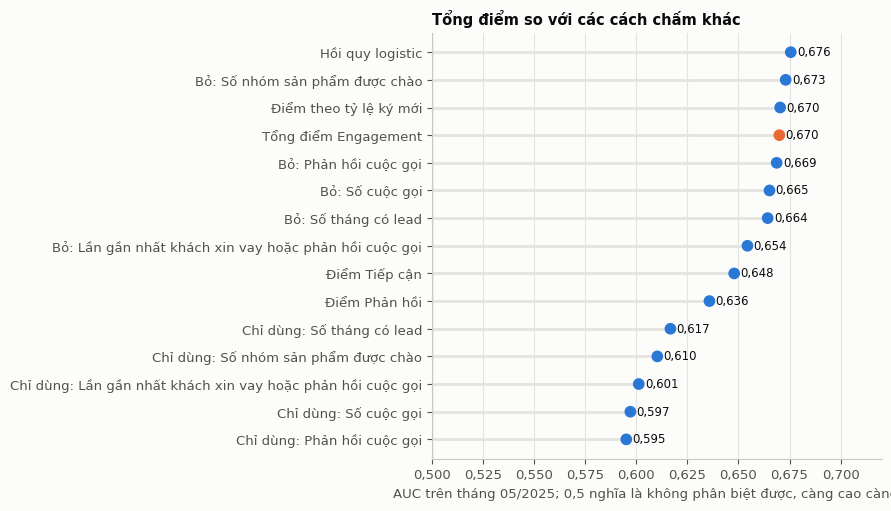

In [41]:
b = bang_auc.sort_values('AUC_thang_05').reset_index(drop=True)
fig, ax = plt.subplots(figsize=(9, 5.2))
mau = [MAU['cam'] if c == 'Tổng điểm Engagement' else MAU['xanh'] for c in b.cach_cham]
ax.hlines(range(len(b)), 0.5, b.AUC_thang_05, color=MAU['luoi'], linewidth=2)
ax.scatter(b.AUC_thang_05, range(len(b)), color=mau, s=55, zorder=3)
for i, v in enumerate(b.AUC_thang_05):
    ax.text(v + 0.003, i, so(v, 3), va='center', fontsize=8.5, color=MAU['chu'])
ax.axvline(0.5, color=MAU['nhat'], linewidth=1)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: so(v, 3)))
ax.set_yticks(range(len(b))); ax.set_yticklabels(b.cach_cham); ax.set_xlim(0.5, 0.72)
ax.set_xlabel('AUC trên tháng 05/2025; 0,5 nghĩa là không phân biệt được, càng cao càng tốt'); ax.grid(axis='y', visible=False)
ax.set_title('Tổng điểm so với các cách chấm khác')
fig.tight_layout()
luu_hinh(fig, 'hinh10_so_sanh_auc')

*Hình 9. AUC trên tháng 05/2025 của tổng điểm (màu cam) và các cách chấm khác, tất cả đều chỉ xây bằng dữ liệu đến hết tháng 04/2025. Nguồn: dữ liệu của đề, nhóm tự tính.*

### 6.4. Khách không quay lại ngay trong tháng sau mốc

Khách không vay đều đặn mỗi tháng, nên một khách điểm cao có thể không ký trong tháng ngay sau mốc nhưng ký ở tháng sau đó. Bảng dưới chấm điểm khách tại 01/04/2025 bằng bản kiểm tra, chỉ giữ những khách **không** ký trong tháng 04/2025, rồi đo tỷ lệ ký trong tháng 05/2025 theo nhóm. Tháng 05/2025 không được dùng khi xây bản kiểm tra.

In [42]:
def ky_trong(tu, den):
    return q(f"""
    SELECT k.SKP_CLIENT, coalesce(max(c.IS_SIGNED), 0) AS Y
    FROM EN_CUSTOMER k
    LEFT JOIN EN_CONTRACT c ON c.SKP_CLIENT = k.SKP_CLIENT
         AND c.APPLY_CONTRACT_TIME >= TIMESTAMP '{tu}' AND c.APPLY_CONTRACT_TIME < TIMESTAMP '{den}'
    GROUP BY 1""")
kiem_tra['ENG_GROUP'] = gan_nhom(kiem_tra)
m = kiem_tra.loc[kiem_tra.KY_MOI == 0, ['SKP_CLIENT', 'ENG_GROUP', 'ENG_SCORE']].merge(ky_trong('2025-05-01', '2025-06-01'), on='SKP_CLIENT')
print('Số khách không ký trong tháng 04/2025:', len(m), '| AUC của điểm tại 01/04 với việc ký tháng 05:', round(roc_auc_score(m.Y, m.ENG_SCORE), 4))
t = m.groupby('ENG_GROUP').agg(so_khach=('Y', 'size'), pct_ky_thang_05=('Y', 'mean'))
t['pct_ky_thang_05'] = (t.pct_ky_thang_05 * 100).round(2)
del m, thang05
dung_cau_hinh(CAU_HINH_DUNG_THAT)   # trả lại ngưỡng của bản dùng thật cho các mục sau
t

Số khách không ký trong tháng 04/2025: 967302 | AUC của điểm tại 01/04 với việc ký tháng 05: 0.6708


,so_khach,pct_ky_thang_05
ENG_GROUP,,
1. Tương tác cao,108045,6.77
2. Tương tác trung bình,180105,5.44
3. Tương tác thấp,294354,3.39
4. Ngủ yên,384798,1.46


Trong 967.302 khách không ký ở tháng 04/2025, tỷ lệ ký ở tháng 05/2025 vẫn xếp đúng thứ tự nhóm, từ Tương tác cao đến Ngủ yên: 6,77% → 5,44% → 3,39% → 1,46%, với AUC 0,671. Khách điểm cao chưa quay lại ngay vẫn có khả năng quay lại ở tháng sau cao hơn khách điểm thấp, nên điểm không chỉ nhận ra những khách sắp ký trong vài tuần tới.

> **Tóm lại mục 6:** Bản xây chỉ bằng dữ liệu đến hết tháng 04 xếp đúng thứ tự ký mới của tháng 05: nhóm Tương tác cao 6,63%, nhóm Ngủ yên 1,43%, AUC 0,670. Nhóm Tương tác cao chiếm 12% khách nhưng 30% giá trị hợp đồng mới ký. Hồi quy logistic chỉ hơn 0,006, nên bảng điểm đơn giản không mất nhiều độ chính xác.

## 7. Điểm của toàn bộ khách tại ngày chốt 05/06/2025

> **Câu hỏi của mục này:** Điểm của từng khách hiện tại là bao nhiêu?
>
> **Cách làm:** dùng cách chấm ở mục 3 và cách chia nhóm ở mục 4 để tính điểm cho toàn bộ 1.000.528 khách tại ngày chốt 05/06/2025, rồi xuất ra file.

Điểm cuối cùng dùng toàn bộ dữ liệu đến ngày chốt, với đúng cách chấm ở mục 3 và ngưỡng nhóm ở mục 4.

count    1000528.0
mean          27.4
std           23.4
min            0.0
25%            6.7
50%           23.3
75%           43.3
max          100.0
Name: ENG_SCORE, dtype: float64


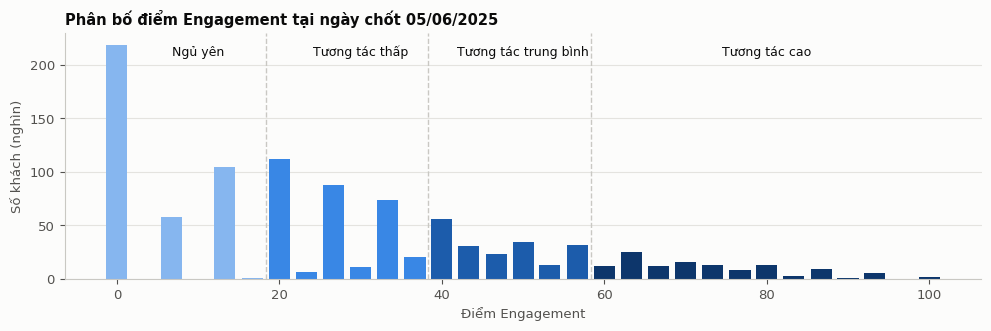

In [43]:
print(chot.ENG_SCORE.describe().round(1))
fig, ax = plt.subplots(figsize=(10, 3.4))
dem = chot.ENG_SCORE.round(1).value_counts().sort_index()
mau = [MAU_NHOM[n] for n in gan_nhom(pd.DataFrame({'ENG_SCORE': dem.index}))]
ax.bar(dem.index, dem.values / 1000, width=2.6, color=mau)
for x, ten in zip([10, 30, 50, 80], ['Ngủ yên', 'Tương tác thấp', 'Tương tác trung bình', 'Tương tác cao']):
    ax.text(x, ax.get_ylim()[1] * 0.95, ten, ha='center', va='top', fontsize=9, color=MAU['chu'])
for x in NGUONG:
    ax.axvline(x - 1.67, color=MAU['nhat'], linewidth=1, linestyle='--')
ax.set_xlabel('Điểm Engagement'); ax.set_ylabel('Số khách (nghìn)'); ax.grid(axis='x', visible=False)
ax.set_title('Phân bố điểm Engagement tại ngày chốt 05/06/2025')
fig.tight_layout()
luu_hinh(fig, 'hinh11_phan_bo_diem')

*Hình 10. Phân bố điểm Engagement của 1.000.528 khách tại ngày chốt 05/06/2025; màu cho biết nhóm, đường đứt nét là ngưỡng 20, 40 và 60 điểm. Nguồn: dữ liệu của đề, nhóm tự tính.*

### 7.1. Ví dụ một khách cụ thể

In [44]:
vi_du = chot[(chot.ENG_GROUP == '2. Tương tác trung bình') & (chot.SO_CUOC_GOI > 0) & (chot.SO_CUOC_PHAN_HOI > 0)
             & (chot.SO_THANG_CO_LEAD > 0) & (chot.NGAY_HOAT_DONG <= 365)].iloc[0]
print('Khách', vi_du.SKP_CLIENT, '| số ngày từ lần xin vay hoặc phản hồi cuộc gọi gần nhất:', vi_du.NGAY_HOAT_DONG, '| số cuộc gọi:', vi_du.SO_CUOC_GOI,
      '| số lần phản hồi cuộc gọi:', vi_du.SO_CUOC_PHAN_HOI, '| số tháng có lead:', vi_du.SO_THANG_CO_LEAD,
      '| số nhóm sản phẩm được chào:', vi_du.SO_SP_DUOC_CHAO)
print('Tổng điểm:', vi_du.ENG_SCORE, '| Tiếp cận:', vi_du.TIEP_CAN, '| Phản hồi:', vi_du.PHAN_HOI, '| Nhóm:', vi_du.ENG_GROUP)
pd.DataFrame([{'phan': 'Tiếp cận' if f in TIEP_CAN else 'Phản hồi', 'khia_canh': TEN_KHIA_CANH[f], 'muc_cua_khach': nhan_muc(f, int(vi_du[f])),
               'diem': round(vi_du[f + '_DIEM'], 1), 'diem_toi_da': 20} for f in KHIA_CANH])

Khách 30134 | số ngày từ lần xin vay hoặc phản hồi cuộc gọi gần nhất: 41 | số cuộc gọi: 1 | số lần phản hồi cuộc gọi: 1 | số tháng có lead: 1 | số nhóm sản phẩm được chào: 1
Tổng điểm: 53.3 | Tiếp cận: 20.0 | Phản hồi: 33.3 | Nhóm: 2. Tương tác trung bình


,phan,khia_canh,muc_cua_khach,diem,diem_toi_da
0,Phản hồi,Lần gần nhất khách xin vay hoặc phản hồi cuộc gọi,2. 31–90 ngày,13.3,20
1,Tiếp cận,Số cuộc gọi,1. 1 cuộc gọi,6.7,20
2,Phản hồi,Phản hồi cuộc gọi,2. Có nghe máy hoặc tự gọi đến,20.0,20
3,Tiếp cận,Số tháng có lead,1. Có lead ở 1 tháng,6.7,20
4,Tiếp cận,Số nhóm sản phẩm được chào,1. Được chào 1 nhóm,6.7,20


Khách 30134 có lần xin vay hoặc phản hồi cuộc gọi gần nhất cách ngày chốt 41 ngày (mức 31–90 ngày, 13,3 điểm), được gọi 1 cuộc (6,7 điểm) và có phản hồi (20 điểm), có lead ở 1 tháng (6,7 điểm) và được chào 1 nhóm sản phẩm (6,7 điểm). Tiếp cận là 6,7 + 6,7 + 6,7 = 20,0 điểm, Phản hồi là 13,3 + 20 = 33,3 điểm, tổng 53,3 điểm, thuộc nhóm Tương tác trung bình. Khách phản hồi tốt nhưng mới được công ty liên hệ ít, đúng kiểu khách chủ động nhưng ít được liên hệ ở mục 5.1.

### 7.2. Xuất file

File `output/engagement_score.csv` có một dòng cho mỗi khách: `ENG_SCORE`, `ENG_GROUP`, hai điểm con `ENG_REACH` (Tiếp cận) và `ENG_RESPONSE` (Phản hồi), mức và điểm của 5 khía cạnh, và `ENG_REASON` ghi các khía cạnh khách còn thiếu điểm, xếp từ khía cạnh thiếu nhiều nhất. File `output/engagement_points.csv` là bảng điểm ở mục 3.4.

In [45]:
TEN_NGAN = {'RECENCY': 'ENG_RECENCY', 'FREQUENCY': 'ENG_FREQUENCY', 'TUONG_TAC': 'ENG_INTERACTION', 'LEAD': 'ENG_LEAD', 'SAN_PHAM': 'ENG_PRODUCT'}
to_hop = chot[KHIA_CANH].drop_duplicates().copy()
def ly_do(row):
    thieu = sorted(((20 - diem_cua_muc(row[f], f), f) for f in KHIA_CANH), reverse=True)
    phan = [f"{TEN_KHIA_CANH[f]}: {nhan_muc(f, int(row[f])).split('. ', 1)[1]} (-{v:.1f} điểm)".replace('.', ',') for v, f in thieu if v > 0.05]
    return '; '.join(phan) if phan else 'Đạt tối đa ở cả 5 khía cạnh'
to_hop['ENG_REASON'] = to_hop.apply(ly_do, axis=1)
for f in KHIA_CANH:
    to_hop[TEN_NGAN[f]] = [nhan_muc(f, int(i)) for i in to_hop[f]]
out = chot[['SKP_CLIENT', 'ENG_SCORE', 'ENG_GROUP', 'TIEP_CAN', 'PHAN_HOI'] + KHIA_CANH + [f + '_DIEM' for f in KHIA_CANH]].merge(to_hop, on=KHIA_CANH, how='left')
out = out.rename(columns={'TIEP_CAN': 'ENG_REACH', 'PHAN_HOI': 'ENG_RESPONSE', **{f + '_DIEM': TEN_NGAN[f] + '_PTS' for f in KHIA_CANH}})
out = out[['SKP_CLIENT', 'ENG_SCORE', 'ENG_GROUP', 'ENG_REACH', 'ENG_RESPONSE'] + [c for f in KHIA_CANH for c in (TEN_NGAN[f], TEN_NGAN[f] + '_PTS')] + ['ENG_REASON']]
for f in KHIA_CANH:
    out[TEN_NGAN[f] + '_PTS'] = out[TEN_NGAN[f] + '_PTS'].round(1)
out.to_csv(f'{OUT_DIR}/engagement_score.csv', index=False, encoding='utf-8-sig')
bang_diem.to_csv(f'{OUT_DIR}/engagement_points.csv', index=False, encoding='utf-8-sig')
print(len(out), 'dòng đã ghi')
out.sample(5, random_state=1)

1000528 dòng đã ghi


,SKP_CLIENT,ENG_SCORE,ENG_GROUP,ENG_REACH,ENG_RESPONSE,ENG_RECENCY,ENG_RECENCY_PTS,ENG_FREQUENCY,ENG_FREQUENCY_PTS,ENG_INTERACTION,ENG_INTERACTION_PTS,ENG_LEAD,ENG_LEAD_PTS,ENG_PRODUCT,ENG_PRODUCT_PTS,ENG_REASON
664327,***,20.0,3. Tương tác thấp,13.3,6.7,1. 91–365 ngày,6.7,0. Không có cuộc gọi,0.0,0. Không có cuộc gọi,0.0,1. Có lead ở 1 tháng,6.7,1. Được chào 1 nhóm,6.7,"Phản hồi cuộc gọi: Không có cuộc gọi (-20,0 điểm); Số cuộc gọi: Không có cuộc gọi (-20,0 điểm); Số nhóm sản phẩm đượ..."
791151,***,56.7,2. Tương tác trung bình,40.0,16.7,1. 91–365 ngày,6.7,2. 2 cuộc gọi,13.3,"1. Có cuộc gọi, chưa lần nào phản hồi",10.0,1. Có lead ở 1 tháng,6.7,3. Được chào 3–5 nhóm,20.0,"Lần gần nhất khách xin vay hoặc phản hồi cuộc gọi: 91–365 ngày (-13,3 điểm); Số tháng có lead: Có lead ở 1 tháng (-1..."
254703,***,6.7,4. Ngủ yên,0.0,6.7,1. 91–365 ngày,6.7,0. Không có cuộc gọi,0.0,0. Không có cuộc gọi,0.0,0. Không có lead,0.0,0. Chưa được chào nhóm nào,0.0,"Phản hồi cuộc gọi: Không có cuộc gọi (-20,0 điểm); Số nhóm sản phẩm được chào: Chưa được chào nhóm nào (-20,0 điểm);..."
173065,***,40.0,2. Tương tác trung bình,40.0,0.0,0. Trên 365 ngày hoặc chưa có,0.0,0. Không có cuộc gọi,0.0,0. Không có cuộc gọi,0.0,3. Có lead ở từ 3 tháng,20.0,3. Được chào 3–5 nhóm,20.0,"Phản hồi cuộc gọi: Không có cuộc gọi (-20,0 điểm); Lần gần nhất khách xin vay hoặc phản hồi cuộc gọi: Trên 365 ngày ..."
645576,***,53.3,2. Tương tác trung bình,40.0,13.3,2. 31–90 ngày,13.3,0. Không có cuộc gọi,0.0,0. Không có cuộc gọi,0.0,3. Có lead ở từ 3 tháng,20.0,3. Được chào 3–5 nhóm,20.0,"Phản hồi cuộc gọi: Không có cuộc gọi (-20,0 điểm); Số cuộc gọi: Không có cuộc gọi (-20,0 điểm); Lần gần nhất khách x..."


> **Tóm lại mục 7:** 1.000.528 khách đã có điểm, trung vị 23,3. File `engagement_score.csv` có một dòng cho mỗi khách: điểm, nhóm, hai điểm con, mức và điểm của từng chỉ số, và lý do khách mất điểm.

## 8. Tổng kết

1. **Hành vi khách theo 5 khía cạnh (mục 1):** khoảng 21% khách còn tự xin vay hoặc phản hồi cuộc gọi trong 90 ngày; trong 90 ngày công ty gọi cho 26% khách nhưng chỉ 7% khách phản hồi; 64,5% khách có lead nhưng chưa đến 3% lead thành Deal; công ty chủ yếu chào sản phẩm cho khách đã có hợp đồng.
2. **Yếu tố phản ánh tương tác (mục 2):** mỗi khía cạnh một chỉ số, chọn theo ý nghĩa, độ tin cậy của dữ liệu và mức trùng với các chỉ số khác: số ngày từ lần xin vay hoặc phản hồi cuộc gọi gần nhất, số cuộc gọi trong 90 ngày, việc khách có phản hồi cuộc gọi, số tháng có lead, số nhóm sản phẩm được chào.
3. **Điểm Engagement (mục 3):** ngưỡng chia mức chọn theo một quy tắc chung, mỗi khía cạnh 20 điểm chia đều theo mức, tách thành Tiếp cận (60 điểm) và Phản hồi (40 điểm).
4. **Nhóm (mục 4):** ngưỡng 20/40/60 điểm. Tại ngày chốt: Tương tác cao 11,8%, Trung bình 18,8%, Thấp 31,1%, Ngủ yên 38,3%. Trung vị điểm là 23,3.
5. **Yếu tố làm tăng hoặc giảm tương tác (mục 5):** khách có lead từ nguồn TLS, khách đang vay thẻ hoặc tiền mặt, khách đã ký nhiều nhóm sản phẩm và khách dùng app thường xuyên tương tác cao hơn hẳn; khách nguồn RA được tiếp cận nhiều nhưng ít phản hồi; khoảng 71 nghìn khách chủ động nhưng ít được liên hệ.
6. **Kiểm chứng (mục 6):** cách xây điểm được làm lại chỉ bằng dữ liệu đến hết tháng 04/2025, rồi kiểm tra trên tháng 05/2025, tháng không dùng khi xây lại. Nhóm Tương tác cao ký mới 6,63% so với 1,43% của nhóm Ngủ yên, và mang lại 30,1% giá trị hợp đồng mới với 12,1% khách; AUC 0,670, gần bằng hồi quy logistic (0,676). Kết quả giữ nguyên với những khách chưa ký ngay trong tháng đầu.

**Hạn chế cần nói rõ khi trình bày:**

- Bảng CALL chỉ có dữ liệu từ 01/01/2025, nên chỉ số từ cuộc gọi chỉ tính trong 90 ngày. 74% khách không có cuộc gọi trong 90 ngày nên nhận 0 điểm ở cả hai khía cạnh cuộc gọi.
- Trong những khách được gọi, việc phản hồi hay không chỉ chênh ít về tỷ lệ ký mới (mục 3.3), nên khía cạnh hành vi tương tác đóng góp ít vào khả năng dự báo của điểm.
- Điểm Tiếp cận phụ thuộc vào việc công ty chọn liên hệ với ai, nên đo cả mức độ công ty đang tiếp cận khách chứ không chỉ hành vi của khách. Vì vậy điểm được tách thành hai phần.
- Số phiên dùng app không được dùng trong điểm vì là số trung bình của cả năm 2025, gồm cả thời gian sau ngày chốt.
- Số nhóm sản phẩm được chào trùng nhiều với số tháng có lead (tương quan 0,85).
- Hai lựa chọn của nhóm trong quy tắc chọn ngưỡng là số mức tối đa (4) và tỷ lệ khách tối thiểu mỗi mức (5%). Mục 3.3 cho thấy các cách chia gần nhau cho AUC gần như bằng nhau.
- Kết quả kinh doanh đo trong 1 tháng sau mốc. Mục 6.4 cho thấy khách chưa ký trong tháng đầu vẫn ký ở tháng sau theo đúng thứ tự nhóm.
- Không còn tháng nào sau 05/2025, nên bản điểm dùng thật không được kiểm tra trực tiếp; mục 6 kiểm tra cách xây bằng một bản xây lại trên dữ liệu cũ hơn một tháng.
- Quan hệ giữa điểm và việc ký mới là tương quan, không phải nhân quả (mục 3.1). Điểm dùng được để chọn khách cần ưu tiên, nhưng chưa cho biết liên hệ thêm có làm khách ký hay không.